In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/sensor_data_clean.tsv", sep="\t")

df.head()

,id,device_id,temperature,ph,turbidity,created_at,temp_status,ph_status,tur_status
0,5742895,8CD0B2A87FA6,31.44,0.0,0.0,2026-07-28 21:41:21,online,offline,online
1,5742896,8CD0B2A87FA6,31.31,0.0,0.0,2026-07-28 21:41:27,online,offline,online
2,5742897,8CD0B2A87FA6,31.38,0.0,0.0,2026-07-28 21:41:33,online,offline,online
3,5742898,8CD0B2A87FA6,31.38,0.0,0.0,2026-07-28 21:41:39,online,offline,online
4,5742899,8CD0B2A87FA6,31.31,0.0,0.0,2026-07-28 21:41:45,online,offline,online


In [ ]:
print("Số dòng, số cột:", df.shape)

print("\nKiểu dữ liệu:")
print(df.dtypes)

Số dòng, số cột: (3973, 9)

Kiểu dữ liệu:
id               int64
device_id          str
temperature    float64
ph             float64
turbidity      float64
created_at         str
temp_status        str
ph_status          str
tur_status         str
dtype: object


In [ ]:
# 1. Chuyển created_at sang datetime
df["created_at"] = pd.to_datetime(df["created_at"])

# 2. Sắp xếp theo thời gian
df = df.sort_values("created_at").reset_index(drop=True)

# 3. Thông tin dataset
print("=== THÔNG TIN DATASET ===")
print("Số dòng:", len(df))
print("Số cột:", len(df.columns))

print("\n=== KHOẢNG THỜI GIAN ===")
print("Bắt đầu:", df["created_at"].min())
print("Kết thúc:", df["created_at"].max())
print("Thời lượng:", df["created_at"].max() - df["created_at"].min())

print("\n=== SỐ DEVICE ===")
print(df["device_id"].nunique())
print(df["device_id"].value_counts())

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== DUPLICATE ===")
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

print("\n=== THỐNG KÊ SENSOR ===")
print(df[["temperature", "ph", "turbidity"]].describe().T)

print("\n=== SENSOR STATUS ===")
print("Temperature:")
print(df["temp_status"].value_counts())

print("\npH:")
print(df["ph_status"].value_counts())

print("\nTurbidity:")
print(df["tur_status"].value_counts())

=== THÔNG TIN DATASET ===
Số dòng: 3973
Số cột: 9

=== KHOẢNG THỜI GIAN ===
Bắt đầu: 2026-07-28 21:41:21
Kết thúc: 2026-09-04 20:55:26
Thời lượng: 37 days 23:14:05

=== SỐ DEVICE ===
3
device_id
8CD0B2A87FA6    2464
7C2C67D36FB8    1500
004B123D9970       9
Name: count, dtype: int64

=== MISSING VALUES ===
id              0
device_id       0
temperature    16
ph             27
turbidity       0
created_at      0
temp_status     9
ph_status       9
tur_status      9
dtype: int64

=== DUPLICATE ===
Số dòng trùng hoàn toàn: 0

=== THỐNG KÊ SENSOR ===
              count        mean         std  min  25%  50%      75%      max
temperature  3957.0   10.021221   14.065970  0.0  0.0  0.0    29.75    32.69
ph           3946.0    2.561123    3.276411  0.0  0.0  0.0     6.72     6.96
turbidity    3973.0  416.608837  596.341244  0.0  0.0  0.0  1117.74  1448.69

=== SENSOR STATUS ===
Temperature:
temp_status
offline    2552
online     1316
missing      96
Name: count, dtype: int64

pH:
ph_status
o

=== GIÁ TRỊ BẰNG 0 ===
temperature : 2612 dòng (65.74%)
ph          : 2449 dòng (61.64%)
turbidity   : 2577 dòng (64.86%)

=== SỐ MẪU THEO DEVICE ===
              samples  temp_missing  ph_missing  turbidity_missing  temp_zero  \
device_id                                                                       
004B123D9970        9             0           0                  0          9   
7C2C67D36FB8     1500             1           0                  0       1489   
8CD0B2A87FA6     2464            15          27                  0       1114   

              ph_zero  turbidity_zero  
device_id                              
004B123D9970        0               9  
7C2C67D36FB8     1500            1500  
8CD0B2A87FA6      949            1068  

=== TEMPERATURE THEO STATUS ===
             count       mean   min    max
temp_status                               
missing         94   8.942021  0.00  32.62
offline       2552   0.070016  0.00  29.81
online        1303  29.450276  1.19  31

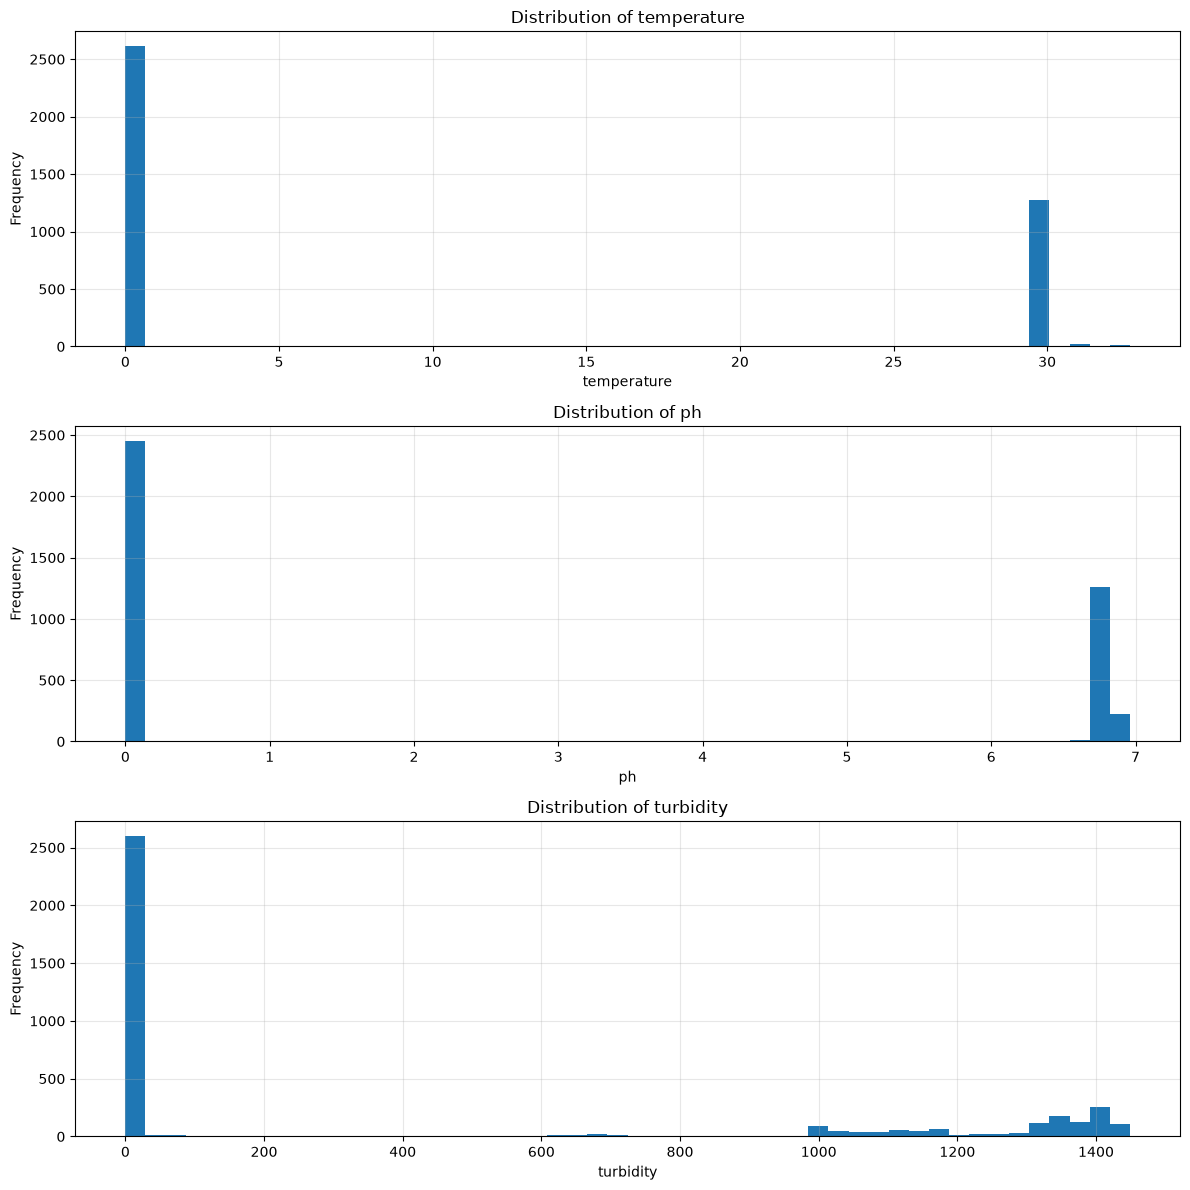

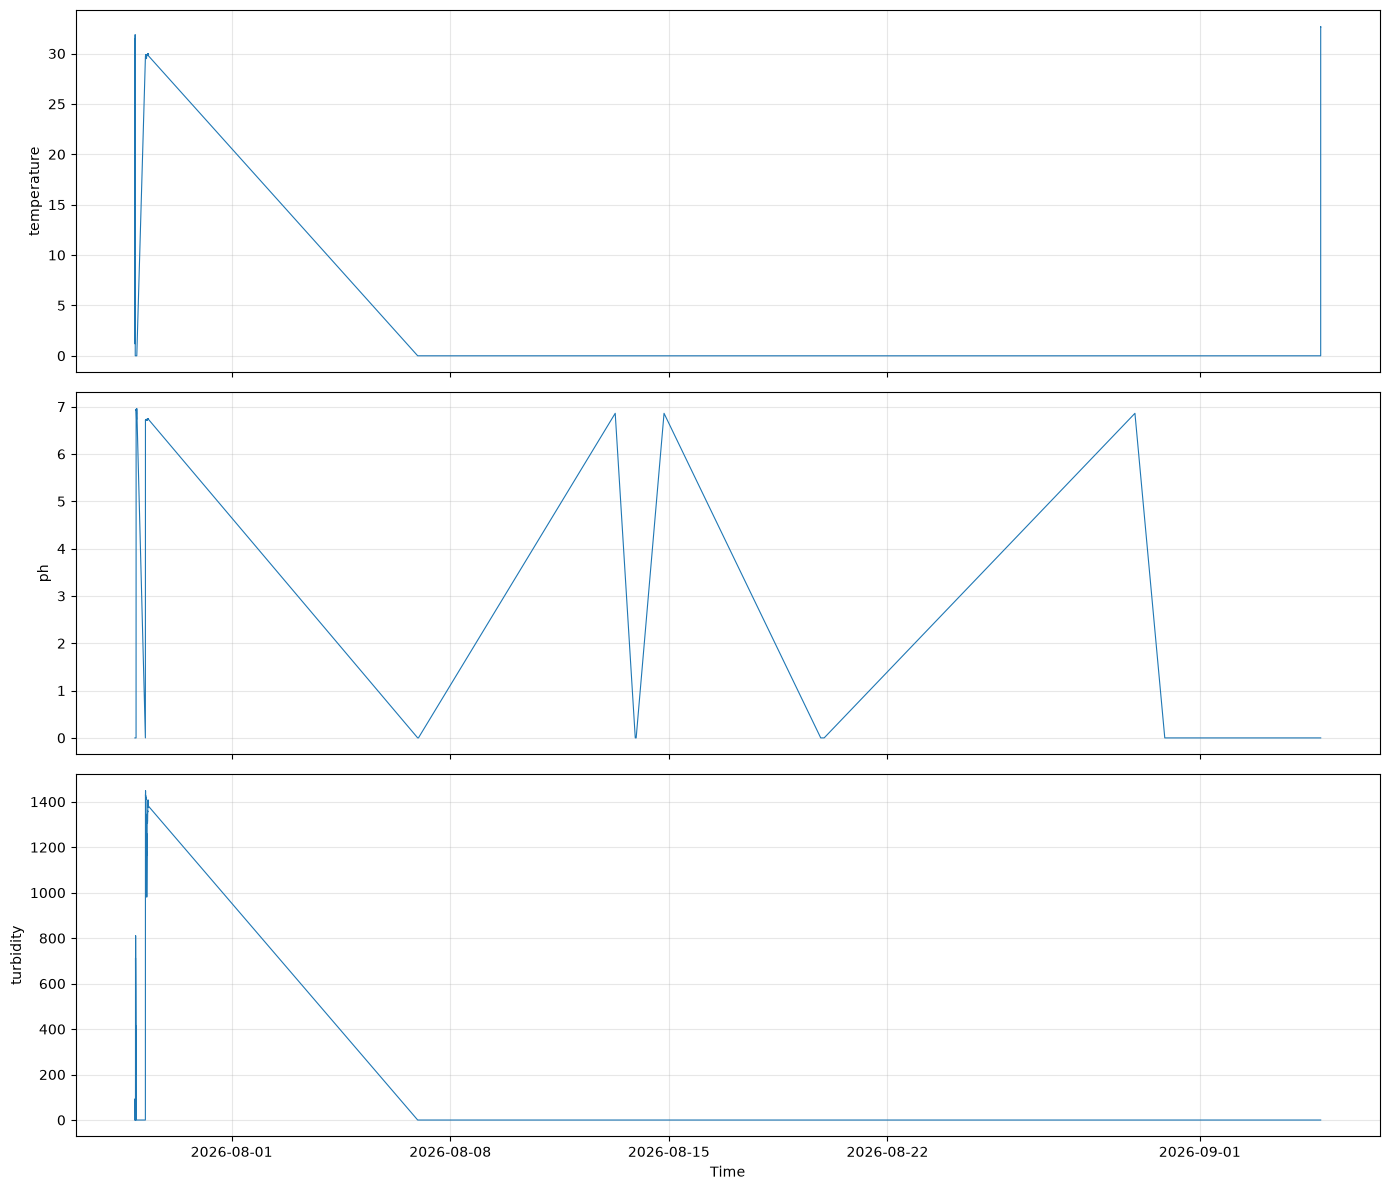

In [ ]:
# ============================================================
# EDA 2 - Phân tích giá trị 0, trạng thái, phân bố và thời gian
# ============================================================

sensor_cols = ["temperature", "ph", "turbidity"]

# ------------------------------------------------------------
# 1. Tỷ lệ giá trị 0
# ------------------------------------------------------------
print("=== GIÁ TRỊ BẰNG 0 ===")

for col in sensor_cols:
    zero_count = (df[col] == 0).sum()
    zero_pct = zero_count / len(df) * 100

    print(f"{col:12s}: {zero_count:4d} dòng ({zero_pct:.2f}%)")


# ------------------------------------------------------------
# 2. Phân tích sensor theo device
# ------------------------------------------------------------
print("\n=== SỐ MẪU THEO DEVICE ===")

device_summary = df.groupby("device_id").agg(
    samples=("id", "count"),
    temp_missing=("temperature", lambda x: x.isna().sum()),
    ph_missing=("ph", lambda x: x.isna().sum()),
    turbidity_missing=("turbidity", lambda x: x.isna().sum()),
    temp_zero=("temperature", lambda x: (x == 0).sum()),
    ph_zero=("ph", lambda x: (x == 0).sum()),
    turbidity_zero=("turbidity", lambda x: (x == 0).sum())
)

print(device_summary)


# ------------------------------------------------------------
# 3. Quan hệ giữa giá trị sensor và status
# ------------------------------------------------------------
print("\n=== TEMPERATURE THEO STATUS ===")
print(df.groupby("temp_status")["temperature"].agg(
    ["count", "mean", "min", "max"]
))

print("\n=== pH THEO STATUS ===")
print(df.groupby("ph_status")["ph"].agg(
    ["count", "mean", "min", "max"]
))

print("\n=== TURBIDITY THEO STATUS ===")
print(df.groupby("tur_status")["turbidity"].agg(
    ["count", "mean", "min", "max"]
))


# ------------------------------------------------------------
# 4. Khoảng cách giữa các mẫu
# ------------------------------------------------------------
time_diff = df["created_at"].diff().dt.total_seconds()

print("\n=== KHOẢNG CÁCH GIỮA CÁC MẪU ===")
print(time_diff.describe())

print("\nCác khoảng cách phổ biến nhất:")
print(
    time_diff
    .round(2)
    .value_counts()
    .head(15)
)


# ------------------------------------------------------------
# 5. Các khoảng gap lớn
# ------------------------------------------------------------
print("\n=== GAP > 1 PHÚT ===")

large_gaps = df.loc[
    time_diff > 60,
    ["created_at", "device_id"]
].copy()

large_gaps["gap_seconds"] = time_diff[time_diff > 60]

print("Số gap > 60 giây:", len(large_gaps))
print(large_gaps.head(20))


# ------------------------------------------------------------
# 6. Biểu đồ phân bố sensor
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

for ax, col in zip(axes, sensor_cols):
    ax.hist(df[col].dropna(), bins=50)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Biểu đồ sensor theo thời gian
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for ax, col in zip(axes, sensor_cols):
    ax.plot(df["created_at"], df[col], linewidth=0.8)
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()

=== DATASET ===
Số dòng: 3973
Số cột: 9

=== TỔ HỢP TRẠNG THÁI SENSOR ===
temp_status  ph_status  tur_status
offline      offline    offline       1446
online       online     online        1217
offline      offline    online         839
             online     online         267
online       offline    online          99
missing      missing    missing         96
NaN          NaN        NaN              9
dtype: int64

=== CẢ 3 SENSOR ONLINE ===
Số mẫu: 1217
Tỷ lệ: 30.63%

=== SỐ MẪU ONLINE TỪNG SENSOR ===
temperature : 1316 mẫu (33.12%)
ph          : 1484 mẫu (37.35%)
turbidity   : 2422 mẫu (60.96%)

=== GIÁ TRỊ 0 KHI SENSOR ONLINE ===
temperature : 0 / 1316 (0.00%)
ph          : 1 / 1484 (0.07%)
turbidity   : 1054 / 2422 (43.52%)

=== ONLINE THEO DEVICE ===

Device: 8CD0B2A87FA6
Số mẫu: 2464
  temperature : 1316 online
  ph          : 1484 online
  turbidity   : 2422 online

Device: 004B123D9970
Số mẫu: 9
  temperature :    0 online
  ph          :    0 online
  turbidity   :    0 o

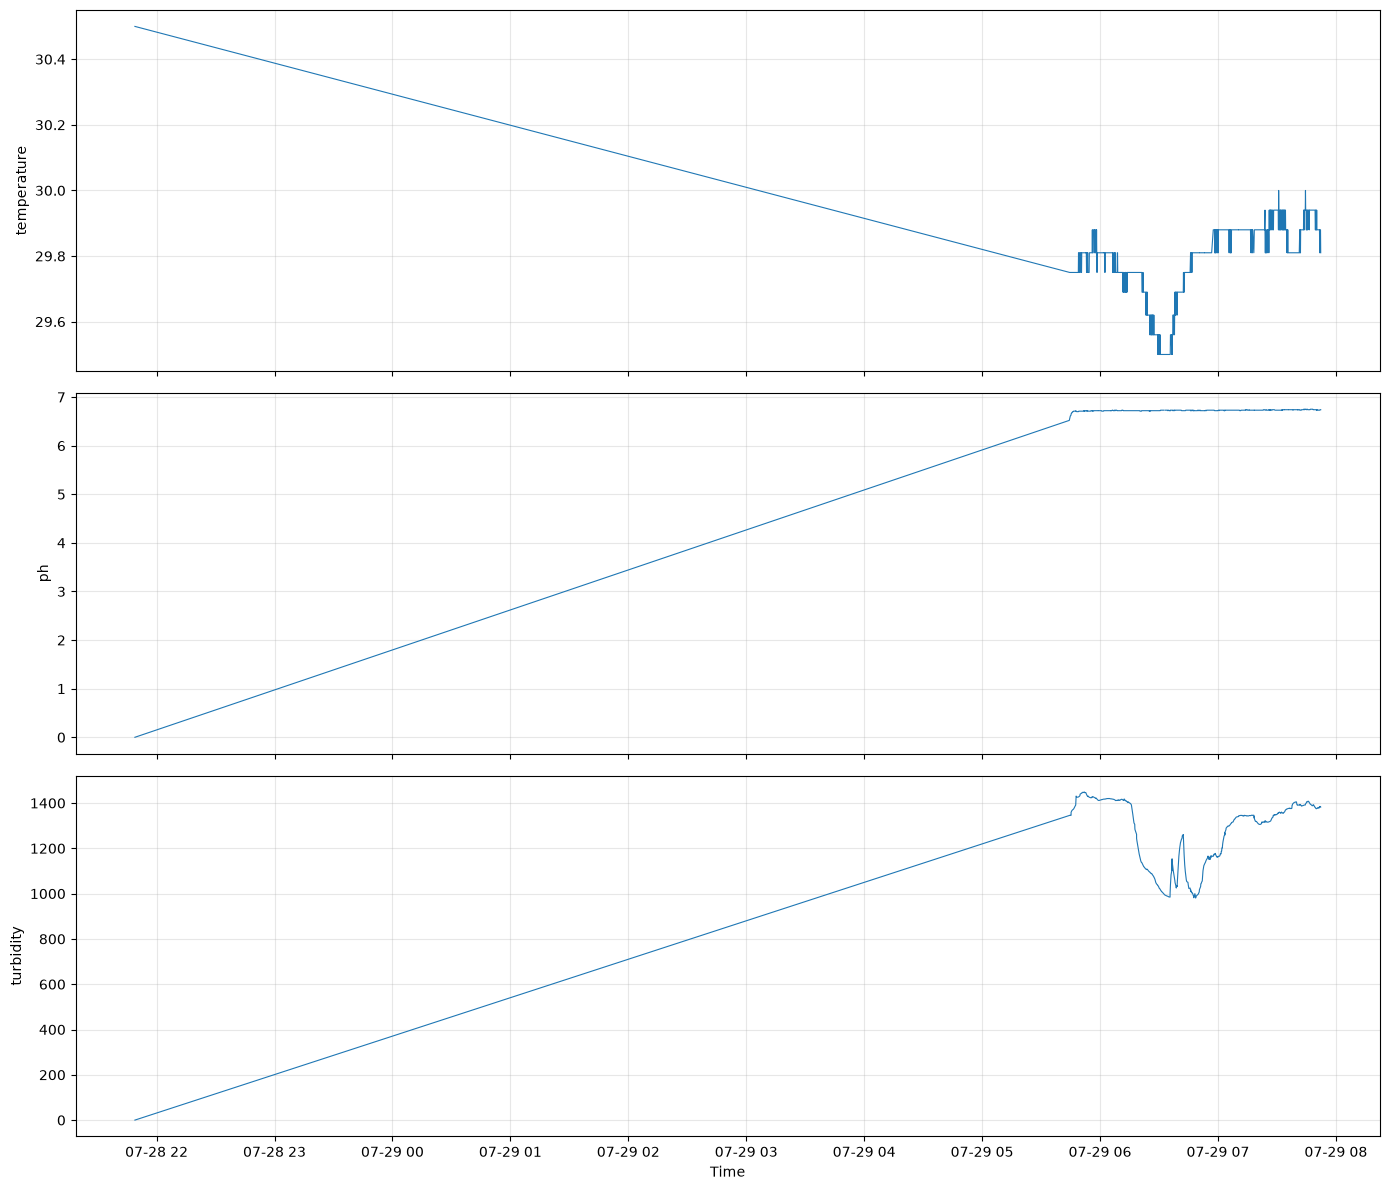

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Đọc dữ liệu
df = pd.read_csv("../data/sensor_data_clean.tsv", sep="\t")

# Chuyển thời gian
df["created_at"] = pd.to_datetime(df["created_at"])

# Sắp xếp
df = df.sort_values("created_at").reset_index(drop=True)

sensor_cols = ["temperature", "ph", "turbidity"]

# ============================================================
# EDA - XÁC ĐỊNH DỮ LIỆU HỢP LỆ CHO AI
# ============================================================

print("=== DATASET ===")
print("Số dòng:", len(df))
print("Số cột:", len(df.columns))

# 1. Tổ hợp trạng thái
print("\n=== TỔ HỢP TRẠNG THÁI SENSOR ===")

status_combo = (
    df.groupby(
        ["temp_status", "ph_status", "tur_status"],
        dropna=False
    )
    .size()
    .sort_values(ascending=False)
)

print(status_combo)

# 2. Cả 3 sensor online
all_online = (
    (df["temp_status"] == "online") &
    (df["ph_status"] == "online") &
    (df["tur_status"] == "online")
)

print("\n=== CẢ 3 SENSOR ONLINE ===")
print("Số mẫu:", all_online.sum())
print("Tỷ lệ:", f"{all_online.mean() * 100:.2f}%")

# 3. Online từng sensor
print("\n=== SỐ MẪU ONLINE TỪNG SENSOR ===")

for sensor, status in [
    ("temperature", "temp_status"),
    ("ph", "ph_status"),
    ("turbidity", "tur_status")
]:
    mask = df[status] == "online"

    print(
        f"{sensor:12s}: "
        f"{mask.sum():4d} mẫu "
        f"({mask.mean() * 100:.2f}%)"
    )

# 4. Giá trị 0 khi sensor ONLINE
print("\n=== GIÁ TRỊ 0 KHI SENSOR ONLINE ===")

for sensor, status in [
    ("temperature", "temp_status"),
    ("ph", "ph_status"),
    ("turbidity", "tur_status")
]:
    mask = df[status] == "online"
    zero_count = (df.loc[mask, sensor] == 0).sum()

    print(
        f"{sensor:12s}: "
        f"{zero_count} / {mask.sum()} "
        f"({zero_count / mask.sum() * 100:.2f}%)"
    )

# 5. Online theo device
print("\n=== ONLINE THEO DEVICE ===")

for device in df["device_id"].unique():

    device_df = df[df["device_id"] == device]

    print(f"\nDevice: {device}")
    print("Số mẫu:", len(device_df))

    for sensor, status in [
        ("temperature", "temp_status"),
        ("ph", "ph_status"),
        ("turbidity", "tur_status")
    ]:
        count = (device_df[status] == "online").sum()
        print(f"  {sensor:12s}: {count:4d} online")

# 6. Tạo dataset chỉ gồm mẫu cả 3 sensor online
df_online = df[all_online].copy()

print("\n=== DATASET AI TẠM THỜI ===")
print("Số mẫu:", len(df_online))
print("Start:", df_online["created_at"].min())
print("End  :", df_online["created_at"].max())

# 7. Thống kê
print("\n=== THỐNG KÊ SENSOR ONLINE ===")
print(df_online[sensor_cols].describe().T)

# 8. Vẽ biểu đồ
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for ax, sensor in zip(axes, sensor_cols):
    ax.plot(
        df_online["created_at"],
        df_online[sensor],
        linewidth=0.8
    )
    ax.set_ylabel(sensor)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# EDA 4 - Kiểm tra giá trị 0 và tính liên tục của dữ liệu
# ============================================================

# ------------------------------------------------------------
# 1. pH = 0 nhưng sensor ONLINE
# ------------------------------------------------------------
print("=== pH = 0 KHI ONLINE ===")

ph_zero_online = df[
    (df["ph_status"] == "online") &
    (df["ph"] == 0)
][[
    "id", "device_id", "temperature", "ph",
    "turbidity", "created_at",
    "temp_status", "ph_status", "tur_status"
]]

print(ph_zero_online)


# ------------------------------------------------------------
# 2. Turbidity = 0 nhưng sensor ONLINE
# ------------------------------------------------------------
print("\n=== TURBIDITY = 0 KHI ONLINE ===")

tur_zero_online = df[
    (df["tur_status"] == "online") &
    (df["turbidity"] == 0)
][[
    "id", "device_id", "temperature", "ph",
    "turbidity", "created_at",
    "temp_status", "ph_status", "tur_status"
]]

print("Số dòng:", len(tur_zero_online))
print(tur_zero_online.head(30))


# ------------------------------------------------------------
# 3. Xem turbidity theo thời gian - chỉ device có dữ liệu
# ------------------------------------------------------------
print("\n=== TURBIDITY ONLINE: 20 DÒNG ĐẦU ===")

tur_online = df[df["tur_status"] == "online"].copy()

print(
    tur_online[
        ["created_at", "device_id", "turbidity"]
    ].head(20).to_string(index=False)
)


# ------------------------------------------------------------
# 4. Tìm đoạn turbidity = 0 liên tiếp
# ------------------------------------------------------------
tur_online = tur_online.sort_values("created_at").copy()

is_zero = tur_online["turbidity"].eq(0)

group = is_zero.ne(is_zero.shift()).cumsum()

zero_runs = (
    tur_online[is_zero]
    .groupby(group)
    .agg(
        start=("created_at", "min"),
        end=("created_at", "max"),
        samples=("turbidity", "size")
    )
    .sort_values("samples", ascending=False)
)

print("\n=== CÁC ĐOẠN TURBIDITY = 0 LIÊN TIẾP ===")
print(zero_runs.head(20))


# ------------------------------------------------------------
# 5. Kiểm tra thời gian của dataset cả 3 sensor online
# ------------------------------------------------------------
print("\n=== GAP TRONG DATASET CẢ 3 SENSOR ONLINE ===")

online_time_diff = df_online["created_at"].diff().dt.total_seconds()

print(online_time_diff.describe())

print("\nCác gap > 60 giây:")
print(
    df_online.loc[
        online_time_diff > 60,
        ["created_at", "device_id"]
    ].assign(
        gap_seconds=online_time_diff[online_time_diff > 60]
    ).head(20)
)


# ------------------------------------------------------------
# 6. Kiểm tra dữ liệu theo ngày
# ------------------------------------------------------------
print("\n=== SỐ MẪU THEO NGÀY ===")

df["date"] = df["created_at"].dt.date

print(
    df.groupby("date")
      .size()
      .to_string()
)

=== pH = 0 KHI ONLINE ===
         id     device_id  temperature   ph  turbidity          created_at  \
49  5742944  8CD0B2A87FA6         30.5  0.0        0.0 2026-07-28 21:48:58   

   temp_status ph_status tur_status  
49      online    online     online  

=== TURBIDITY = 0 KHI ONLINE ===
Số dòng: 1054
         id     device_id  temperature   ph  turbidity          created_at  \
0   5742895  8CD0B2A87FA6        31.44  0.0        0.0 2026-07-28 21:41:21   
1   5742896  8CD0B2A87FA6        31.31  0.0        0.0 2026-07-28 21:41:27   
2   5742897  8CD0B2A87FA6        31.38  0.0        0.0 2026-07-28 21:41:33   
3   5742898  8CD0B2A87FA6        31.38  0.0        0.0 2026-07-28 21:41:39   
4   5742899  8CD0B2A87FA6        31.31  0.0        0.0 2026-07-28 21:41:45   
5   5742900  8CD0B2A87FA6        31.31  0.0        0.0 2026-07-28 21:41:51   
6   5742901  8CD0B2A87FA6        31.31  0.0        0.0 2026-07-28 21:41:57   
7   5742902  8CD0B2A87FA6        31.38  0.0        0.0 2026-07-28 21:

=== MAIN DEVICE ===
Device: 8CD0B2A87FA6
Số mẫu: 2464
Start: 2026-07-28 21:41:21
End  : 2026-08-29 22:08:27

=== TRẠNG THÁI SENSOR ===

temp_status
temp_status
online     1316
offline    1110
missing      38
Name: count, dtype: int64

ph_status
ph_status
online     1484
offline     942
missing      38
Name: count, dtype: int64

tur_status
tur_status
online     2422
missing      38
offline       4
Name: count, dtype: int64

=== ALL SENSOR ONLINE ===
Số mẫu: 1217
Start: 2026-07-28 21:48:58
End  : 2026-07-29 07:52:16

=== MISSING TRONG ALL-ONLINE ===
temperature    13
ph             22
turbidity       0
dtype: int64

=== ZERO TRONG ALL-ONLINE ===
temperature : 0
ph          : 1
turbidity   : 1

=== TURBIDITY 0 / >0 ===
turbidity_zero
False    1182
True        1
Name: count, dtype: int64

=== TURBIDITY > 0 ===
Số mẫu: 1182
Bắt đầu: 2026-07-29 05:44:21
Kết thúc: 2026-07-29 07:52:16

=== DATASET ỨNG VIÊN ===
Số mẫu: 1183
Start: 2026-07-28 21:48:58
End  : 2026-07-29 07:52:16

=== THỐNG KÊ ===

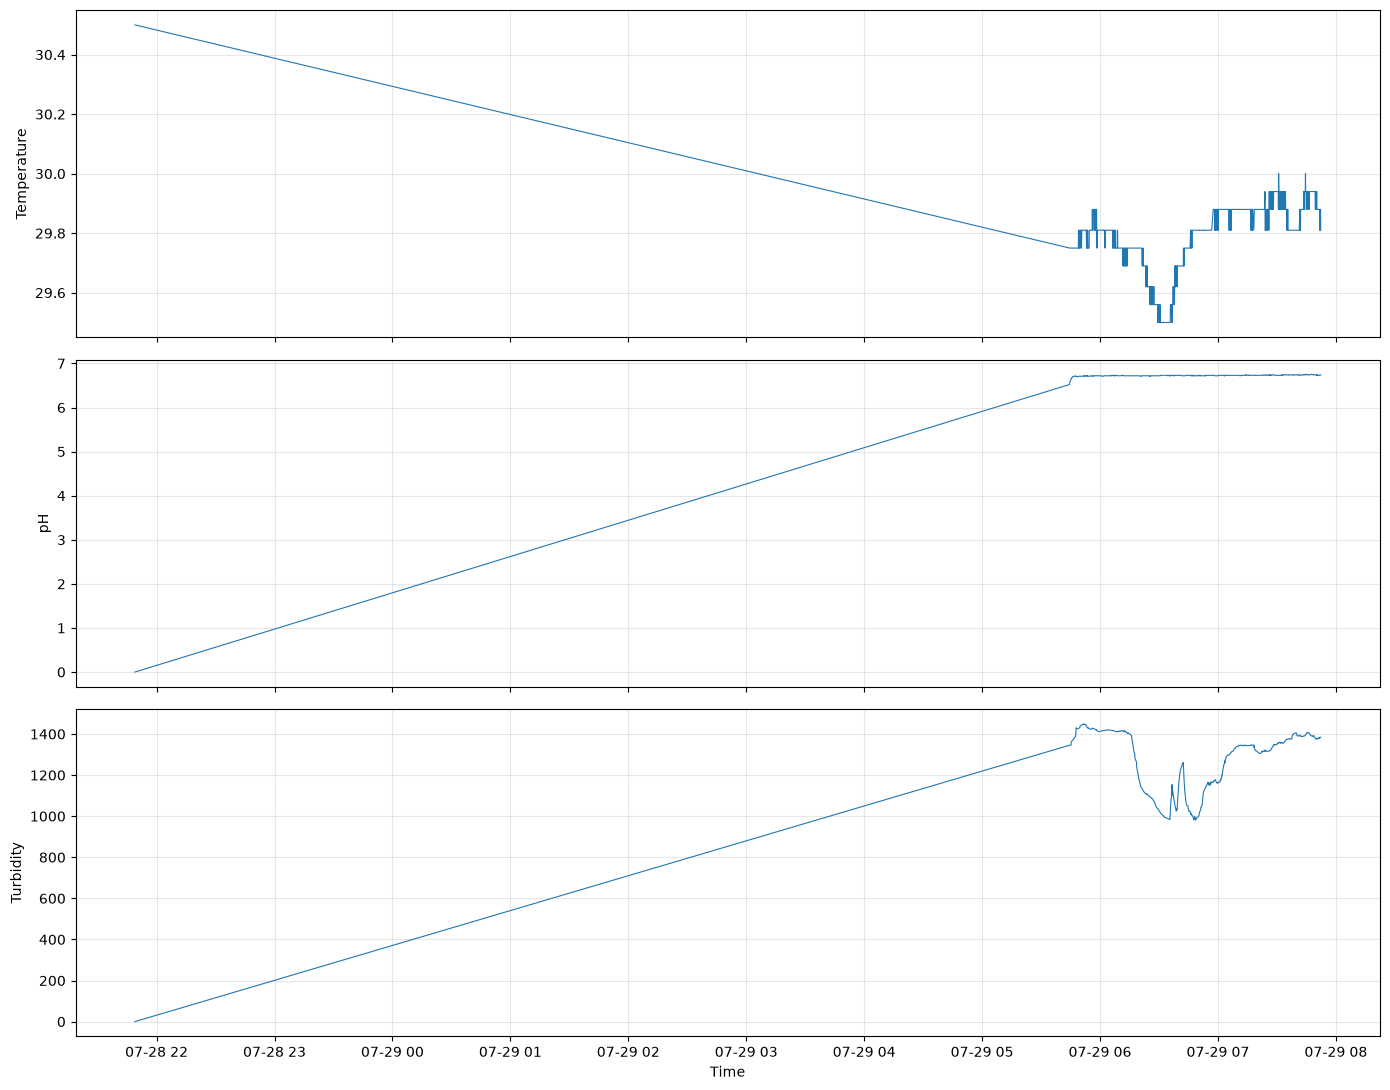

In [4]:
# ============================================================
# EDA 5 - Xác định vùng dữ liệu hợp lệ cho anomaly detection
# ============================================================

# Chỉ xét device có dữ liệu đáng kể
MAIN_DEVICE = "8CD0B2A87FA6"

d = df[df["device_id"] == MAIN_DEVICE].copy()

# ------------------------------------------------------------
# 1. Thống kê sensor theo từng giai đoạn trạng thái
# ------------------------------------------------------------

print("=== MAIN DEVICE ===")
print("Device:", MAIN_DEVICE)
print("Số mẫu:", len(d))
print("Start:", d["created_at"].min())
print("End  :", d["created_at"].max())

print("\n=== TRẠNG THÁI SENSOR ===")

for col in ["temp_status", "ph_status", "tur_status"]:
    print(f"\n{col}")
    print(d[col].value_counts(dropna=False))


# ------------------------------------------------------------
# 2. Xác định mẫu cả 3 sensor online
# ------------------------------------------------------------

all_online_main = (
    (d["temp_status"] == "online") &
    (d["ph_status"] == "online") &
    (d["tur_status"] == "online")
)

d_online = d[all_online_main].copy()

print("\n=== ALL SENSOR ONLINE ===")
print("Số mẫu:", len(d_online))
print("Start:", d_online["created_at"].min())
print("End  :", d_online["created_at"].max())


# ------------------------------------------------------------
# 3. Xác định dữ liệu có giá trị đo thực tế
# ------------------------------------------------------------

valid_values = (
    d_online["temperature"].notna() &
    d_online["ph"].notna() &
    d_online["turbidity"].notna()
)

# Không loại turbidity = 0 ở đây.
# Chỉ thống kê để xem nó nằm ở đâu.
d_online_valid = d_online[valid_values].copy()

print("\n=== MISSING TRONG ALL-ONLINE ===")
print(d_online[["temperature", "ph", "turbidity"]].isna().sum())

print("\n=== ZERO TRONG ALL-ONLINE ===")
for col in ["temperature", "ph", "turbidity"]:
    count = (d_online[col] == 0).sum()
    print(f"{col:12s}: {count}")


# ------------------------------------------------------------
# 4. Chia turbidity thành 0 / >0
# ------------------------------------------------------------

d_online_valid["turbidity_zero"] = (
    d_online_valid["turbidity"] == 0
)

print("\n=== TURBIDITY 0 / >0 ===")

print(
    d_online_valid["turbidity_zero"]
    .value_counts()
)


# ------------------------------------------------------------
# 5. Tìm thời điểm turbidity bắt đầu có giá trị > 0
# ------------------------------------------------------------

tur_positive = d_online_valid[
    d_online_valid["turbidity"] > 0
]

print("\n=== TURBIDITY > 0 ===")

print("Số mẫu:", len(tur_positive))

if len(tur_positive) > 0:
    print("Bắt đầu:", tur_positive["created_at"].min())
    print("Kết thúc:", tur_positive["created_at"].max())


# ------------------------------------------------------------
# 6. Dataset ứng viên cho AI:
#    cả 3 sensor online + không missing
# ------------------------------------------------------------

df_candidate = d_online_valid.copy()

print("\n=== DATASET ỨNG VIÊN ===")
print("Số mẫu:", len(df_candidate))
print("Start:", df_candidate["created_at"].min())
print("End  :", df_candidate["created_at"].max())

print("\n=== THỐNG KÊ ===")
print(
    df_candidate[
        ["temperature", "ph", "turbidity"]
    ].describe().T
)


# ------------------------------------------------------------
# 7. Vẽ từng sensor và đánh dấu turbidity = 0
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

axes[0].plot(
    d_online["created_at"],
    d_online["temperature"],
    linewidth=0.8
)
axes[0].set_ylabel("Temperature")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    d_online["created_at"],
    d_online["ph"],
    linewidth=0.8
)
axes[1].set_ylabel("pH")
axes[1].grid(True, alpha=0.3)

axes[2].plot(
    d_online["created_at"],
    d_online["turbidity"],
    linewidth=0.8
)
axes[2].set_ylabel("Turbidity")
axes[2].set_xlabel("Time")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== THỐNG KÊ THEO 30 PHÚT ===
                    temperature                                       ph  \
                          count       mean       std    min    max count   
time_bin                                                                   
2026-07-28 21:30:00           1  30.500000       NaN  30.50  30.50     1   
2026-07-29 05:30:00         148  29.789324  0.039515  29.75  29.88   148   
2026-07-29 06:00:00         283  29.719364  0.082149  29.50  29.81   283   
2026-07-29 06:30:00         269  29.703680  0.128319  29.50  29.88   269   
2026-07-29 07:00:00         277  29.880542  0.028247  29.81  29.94   277   
2026-07-29 07:30:00         205  29.884780  0.051531  29.81  30.00   205   

                                                    turbidity               \
                         mean       std   min   max     count         mean   
time_bin                                                                     
2026-07-28 21:30:00  0.000000       NaN  0.00  0.00

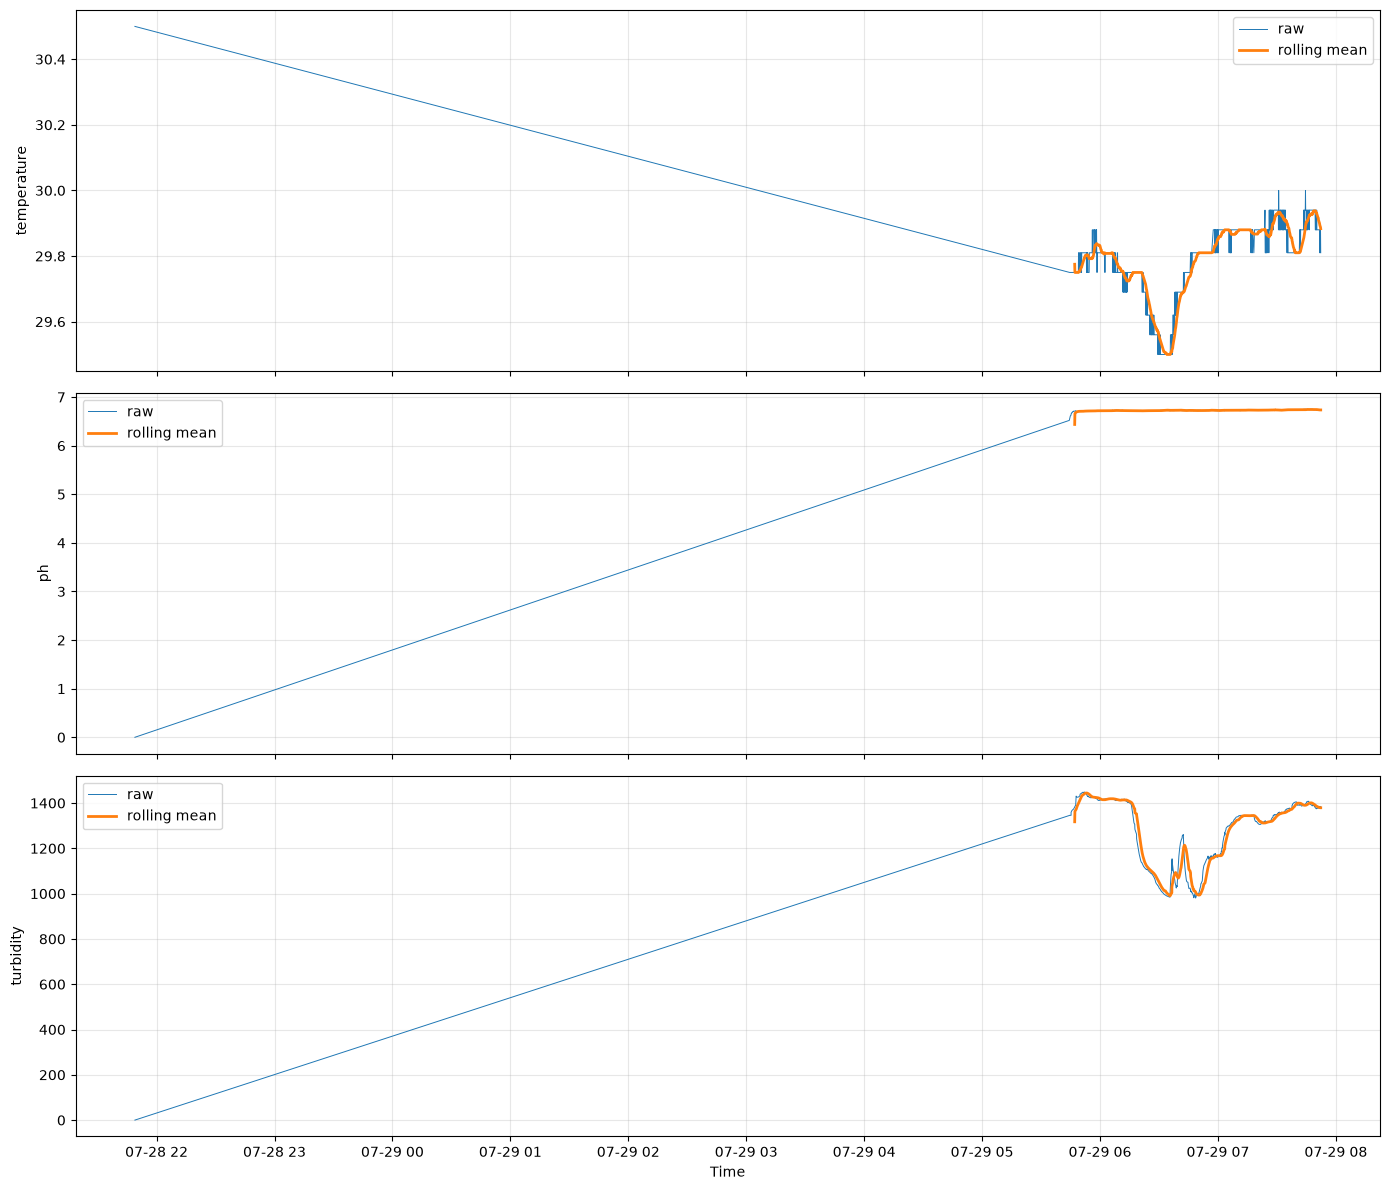


=== SO SÁNH ĐẦU / CUỐI DATASET ===

temperature
Giai đoạn đầu: mean=30.5000, std=nan
Giai đoạn cuối: mean=29.7910, std=0.1121

ph
Giai đoạn đầu: mean=0.0000, std=nan
Giai đoạn cuối: mean=6.7249, std=0.0165

turbidity
Giai đoạn đầu: mean=0.0000, std=nan
Giai đoạn cuối: mean=1278.4513, std=144.0623


In [5]:
# ============================================================
# EDA 6 - Phân tích độ ổn định của sensor theo thời gian
# ============================================================

d = df_candidate.copy()

sensor_cols = ["temperature", "ph", "turbidity"]

# ------------------------------------------------------------
# 1. Chia dữ liệu thành các khoảng 30 phút
# ------------------------------------------------------------

d["time_bin"] = d["created_at"].dt.floor("30min")

summary_30m = d.groupby("time_bin")[sensor_cols].agg(
    ["count", "mean", "std", "min", "max"]
)

print("=== THỐNG KÊ THEO 30 PHÚT ===")
print(summary_30m)


# ------------------------------------------------------------
# 2. Tính tốc độ thay đổi trung bình
# ------------------------------------------------------------

print("\n=== TỐC ĐỘ THAY ĐỔI SENSOR ===")

for col in sensor_cols:

    diff = d[col].diff().abs()

    print(f"\n{col}")
    print("Mean |Δ| :", diff.mean())
    print("Median |Δ|:", diff.median())
    print("Max |Δ|   :", diff.max())


# ------------------------------------------------------------
# 3. Rolling statistics
# ------------------------------------------------------------

print("\n=== ROLLING STATISTICS ===")

window = 30

for col in sensor_cols:

    d[f"{col}_rolling_mean"] = (
        d[col].rolling(window).mean()
    )

    d[f"{col}_rolling_std"] = (
        d[col].rolling(window).std()
    )


# ------------------------------------------------------------
# 4. Vẽ giá trị + rolling mean
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 12),
    sharex=True
)

for ax, col in zip(axes, sensor_cols):

    ax.plot(
        d["created_at"],
        d[col],
        linewidth=0.7,
        label="raw"
    )

    ax.plot(
        d["created_at"],
        d[f"{col}_rolling_mean"],
        linewidth=2,
        label="rolling mean"
    )

    ax.set_ylabel(col)
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Chia dữ liệu thành 2 giai đoạn
# ------------------------------------------------------------

midpoint = d["created_at"].min() + (
    d["created_at"].max() - d["created_at"].min()
) / 2

early = d[d["created_at"] <= midpoint]
late = d[d["created_at"] > midpoint]

print("\n=== SO SÁNH ĐẦU / CUỐI DATASET ===")

for col in sensor_cols:

    print(f"\n{col}")

    print(
        "Giai đoạn đầu:"
        f" mean={early[col].mean():.4f},"
        f" std={early[col].std():.4f}"
    )

    print(
        "Giai đoạn cuối:"
        f" mean={late[col].mean():.4f},"
        f" std={late[col].std():.4f}"
    )

=== THỐNG KÊ THEO 10 PHÚT ===
                    temperature                                       ph                                 turbidity                                          
                          count       mean       std    min    max count      mean       std   min   max     count         mean        std      min      max
time_bin_10m                                                                                                                                                
2026-07-28 21:40:00           1  30.500000       NaN  30.50  30.50     1  0.000000       NaN  0.00  0.00         1     0.000000        NaN     0.00     0.00
2026-07-29 05:40:00          56  29.754286  0.015592  29.75  29.81    56  6.681429  0.047422  6.52  6.72        56  1391.018929  33.101657  1344.50  1440.00
2026-07-29 05:50:00          92  29.810652  0.034059  29.75  29.88    92  6.715109  0.005026  6.71  6.72        92  1429.922935  11.276774  1411.23  1448.69
2026-07-29 06:00:00         

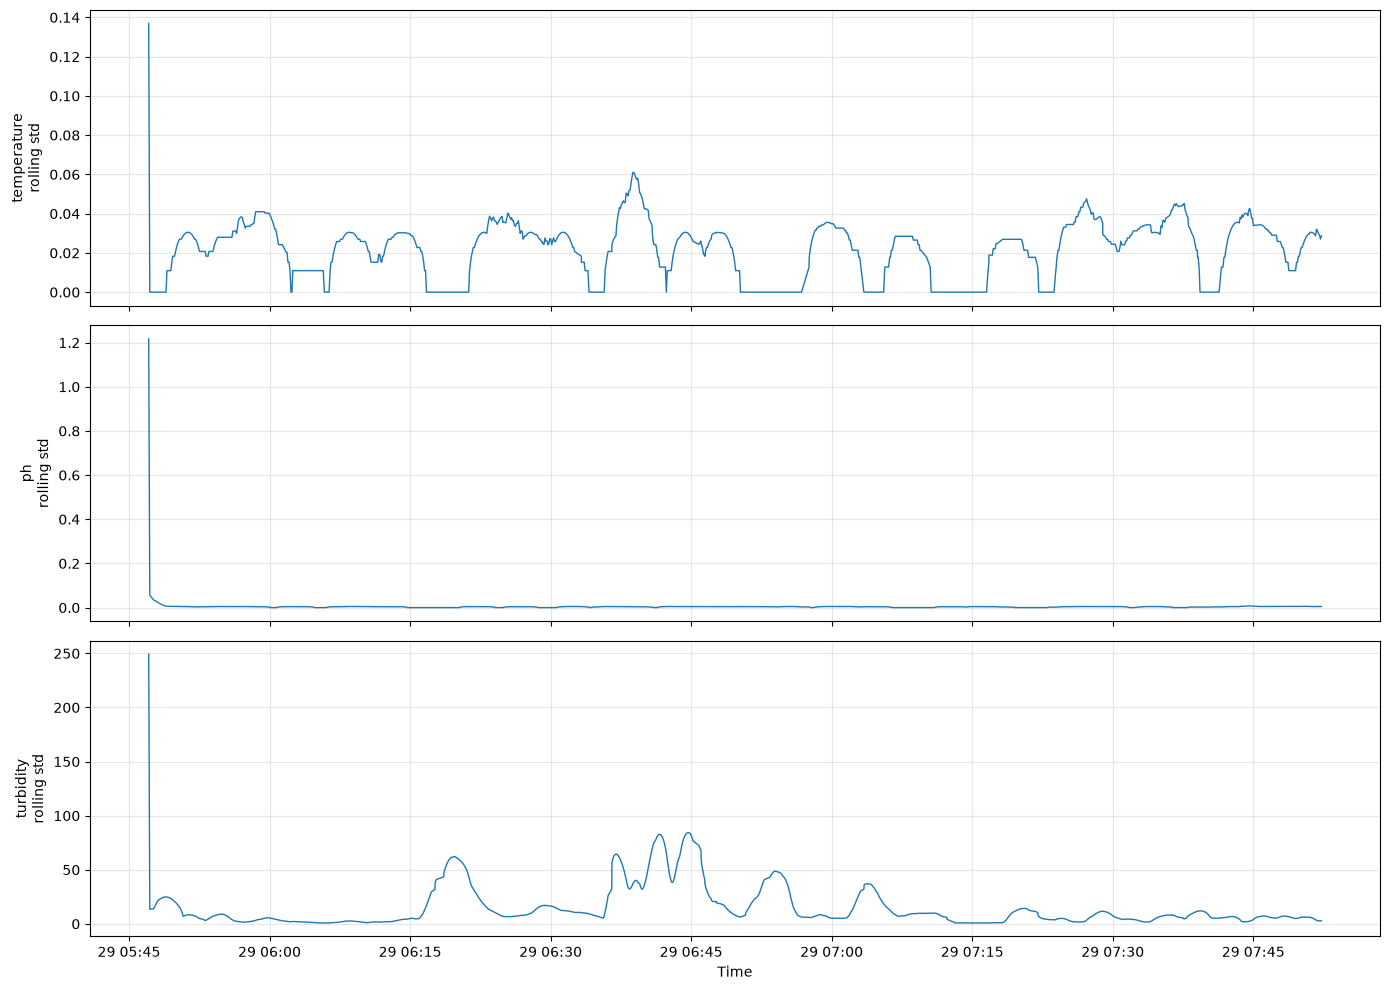


=== SO SÁNH TRƯỚC / SAU 05:44:21 ===

temperature
Trước 05:44: mean=30.5000, std=nan
Sau 05:44:  mean=29.7910, std=0.1121

ph
Trước 05:44: mean=0.0000, std=nan
Sau 05:44:  mean=6.7249, std=0.0165

turbidity
Trước 05:44: mean=0.0000, std=nan
Sau 05:44:  mean=1278.4513, std=144.0623


In [6]:
# ============================================================
# EDA 7 - Đánh giá độ ổn định theo thời gian
# ============================================================

d = df_candidate.copy()

sensor_cols = ["temperature", "ph", "turbidity"]

# ------------------------------------------------------------
# 1. Chia dữ liệu thành các cửa sổ 10 phút
# ------------------------------------------------------------

d["time_bin_10m"] = d["created_at"].dt.floor("10min")

stats_10m = (
    d.groupby("time_bin_10m")[sensor_cols]
    .agg(["count", "mean", "std", "min", "max"])
)

print("=== THỐNG KÊ THEO 10 PHÚT ===")
print(stats_10m.to_string())


# ------------------------------------------------------------
# 2. Tính độ thay đổi trung bình trong từng cửa sổ
# ------------------------------------------------------------

print("\n=== MEAN ABSOLUTE CHANGE THEO 10 PHÚT ===")

change_stats = []

for time_bin, group in d.groupby("time_bin_10m"):

    row = {"time": time_bin}

    for col in sensor_cols:
        row[col] = group[col].diff().abs().mean()

    change_stats.append(row)

change_df = pd.DataFrame(change_stats)

print(change_df.to_string(index=False))


# ------------------------------------------------------------
# 3. Tính rolling standard deviation
# ------------------------------------------------------------

window = 30

for col in sensor_cols:
    d[f"{col}_rolling_std"] = (
        d[col].rolling(window).std()
    )


# ------------------------------------------------------------
# 4. Vẽ rolling std
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)

for ax, col in zip(axes, sensor_cols):

    ax.plot(
        d["created_at"],
        d[f"{col}_rolling_std"],
        linewidth=1
    )

    ax.set_ylabel(f"{col}\nrolling std")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. So sánh biến thiên trước và sau 05:44
# ------------------------------------------------------------

cutoff = pd.Timestamp("2026-07-29 05:44:21")

before = d[d["created_at"] < cutoff]
after = d[d["created_at"] >= cutoff]

print("\n=== SO SÁNH TRƯỚC / SAU 05:44:21 ===")

for col in sensor_cols:

    print(f"\n{col}")

    print(
        f"Trước 05:44: "
        f"mean={before[col].mean():.4f}, "
        f"std={before[col].std():.4f}"
    )

    print(
        f"Sau 05:44:  "
        f"mean={after[col].mean():.4f}, "
        f"std={after[col].std():.4f}"
    )

In [7]:
# ============================================================
# CHỐT DATASET CHO ANOMALY DETECTION
# ============================================================

# Dữ liệu từ giai đoạn sensor đã ổn định
cutoff = pd.Timestamp("2026-07-29 05:44:21")

df_ai = df[
    (df["device_id"] == "8CD0B2A87FA6") &
    (df["created_at"] >= cutoff)
].copy()

# Chỉ giữ các mẫu có đủ 3 giá trị sensor
df_ai = df_ai.dropna(
    subset=["temperature", "ph", "turbidity"]
).copy()

# Loại các mẫu chuyển tiếp có giá trị 0
df_ai = df_ai[
    (df_ai["temperature"] > 0) &
    (df_ai["ph"] > 0) &
    (df_ai["turbidity"] > 0)
].copy()

# Sắp xếp lại
df_ai = df_ai.sort_values("created_at").reset_index(drop=True)

# ------------------------------------------------------------
# Kiểm tra dataset cuối
# ------------------------------------------------------------

print("=== DATASET AI ĐÃ CHỐT ===")

print("Số mẫu:", len(df_ai))
print("Số đặc trưng:", 3)

print("\nKhoảng thời gian:")
print("Start:", df_ai["created_at"].min())
print("End  :", df_ai["created_at"].max())

print("\nMissing:")
print(df_ai[["temperature", "ph", "turbidity"]].isna().sum())

print("\nZero:")
print(
    (df_ai[["temperature", "ph", "turbidity"]] == 0).sum()
)

print("\nThống kê:")
print(
    df_ai[
        ["temperature", "ph", "turbidity"]
    ].describe().T
)

print("\n=== 10 MẪU ĐẦU ===")
print(
    df_ai[
        ["created_at", "temperature", "ph", "turbidity"]
    ].head(10)
)

print("\n=== 10 MẪU CUỐI ===")
print(
    df_ai[
        ["created_at", "temperature", "ph", "turbidity"]
    ].tail(10)
)

=== DATASET AI ĐÃ CHỐT ===
Số mẫu: 1212
Số đặc trưng: 3

Khoảng thời gian:
Start: 2026-07-29 05:44:21
End  : 2026-07-29 07:52:16

Missing:
temperature    0
ph             0
turbidity      0
dtype: int64

Zero:
temperature    0
ph             0
turbidity      0
dtype: int64

Thống kê:
              count         mean         std     min       25%       50%  \
temperature  1212.0    29.791774    0.111483   29.50    29.750    29.810   
ph           1212.0     6.724950    0.016334    6.52     6.720     6.730   
turbidity    1212.0  1277.752244  144.606206  980.55  1154.575  1343.545   

                   75%      max  
temperature    29.8800    30.00  
ph              6.7300     6.75  
turbidity    1397.6225  1448.69  

=== 10 MẪU ĐẦU ===
           created_at  temperature    ph  turbidity
0 2026-07-29 05:44:21        29.75  6.52    1344.50
1 2026-07-29 05:44:28        29.75  6.54    1344.87
2 2026-07-29 05:44:34        29.75  6.55    1345.62
3 2026-07-29 05:44:40        29.75  6.57    13

In [2]:
# ============================================================
# CHUẨN BỊ DATASET + CHIA TRAIN / VALIDATION / TEST
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Đọc Dataset (tập dữ liệu) gốc
# ------------------------------------------------------------

df = pd.read_csv(
    "../data/sensor_data_clean.tsv",
    sep="\t"
)

df["created_at"] = pd.to_datetime(df["created_at"])

df = (
    df.sort_values("created_at")
      .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Chọn Device chính
# ------------------------------------------------------------

MAIN_DEVICE = "8CD0B2A87FA6"

df_main = df[
    df["device_id"] == MAIN_DEVICE
].copy()


# ------------------------------------------------------------
# 3. Xác định thời điểm sensor đã ổn định
# ------------------------------------------------------------

cutoff = pd.Timestamp("2026-07-29 05:44:21")


# ------------------------------------------------------------
# 4. Tạo Dataset AI
# ------------------------------------------------------------

df_ai = df_main[
    df_main["created_at"] >= cutoff
].copy()


# ------------------------------------------------------------
# 5. Chỉ giữ mẫu có đủ 3 Feature (đặc trưng)
# ------------------------------------------------------------

features = [
    "temperature",
    "ph",
    "turbidity"
]

df_ai = df_ai.dropna(
    subset=features
).copy()


# ------------------------------------------------------------
# 6. Loại các giá trị 0 không hợp lệ
# ------------------------------------------------------------

for col in features:
    df_ai = df_ai[
        df_ai[col] > 0
    ]


# Sắp xếp lại
df_ai = (
    df_ai.sort_values("created_at")
          .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Kiểm tra Dataset AI
# ------------------------------------------------------------

print("=== DATASET AI ===")
print("Số mẫu:", len(df_ai))
print("Số Feature:", len(features))

print("\nKhoảng thời gian:")
print("Start:", df_ai["created_at"].min())
print("End  :", df_ai["created_at"].max())


# ------------------------------------------------------------
# 8. Time-series Split (chia theo chuỗi thời gian)
# ------------------------------------------------------------

n = len(df_ai)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

train_df = df_ai.iloc[:train_end].copy()
val_df = df_ai.iloc[train_end:val_end].copy()
test_df = df_ai.iloc[val_end:].copy()


# ------------------------------------------------------------
# 9. Kết quả chia
# ------------------------------------------------------------

print("\n========================================")
print("TIME-SERIES SPLIT")
print("========================================")

print("\nTRAINING SET (TẬP HUẤN LUYỆN)")
print("Số mẫu:", len(train_df))
print("Tỷ lệ:", f"{len(train_df)/n*100:.1f}%")
print("Start:", train_df["created_at"].min())
print("End  :", train_df["created_at"].max())

print("\nVALIDATION SET (TẬP KIỂM ĐỊNH)")
print("Số mẫu:", len(val_df))
print("Tỷ lệ:", f"{len(val_df)/n*100:.1f}%")
print("Start:", val_df["created_at"].min())
print("End  :", val_df["created_at"].max())

print("\nTEST SET (TẬP KIỂM TRA)")
print("Số mẫu:", len(test_df))
print("Tỷ lệ:", f"{len(test_df)/n*100:.1f}%")
print("Start:", test_df["created_at"].min())
print("End  :", test_df["created_at"].max())


# ------------------------------------------------------------
# 10. Thống kê từng tập
# ------------------------------------------------------------

print("\n========================================")
print("THỐNG KÊ TRAINING SET")
print("========================================")
print(train_df[features].describe().T)

print("\n========================================")
print("THỐNG KÊ VALIDATION SET")
print("========================================")
print(val_df[features].describe().T)

print("\n========================================")
print("THỐNG KÊ TEST SET")
print("========================================")
print(test_df[features].describe().T)

=== DATASET AI ===
Số mẫu: 1212
Số Feature: 3

Khoảng thời gian:
Start: 2026-07-29 05:44:21
End  : 2026-07-29 07:52:16

TIME-SERIES SPLIT

TRAINING SET (TẬP HUẤN LUYỆN)
Số mẫu: 727
Tỷ lệ: 60.0%
Start: 2026-07-29 05:44:21
End  : 2026-07-29 07:01:23

VALIDATION SET (TẬP KIỂM ĐỊNH)
Số mẫu: 242
Tỷ lệ: 20.0%
Start: 2026-07-29 07:01:29
End  : 2026-07-29 07:27:00

TEST SET (TẬP KIỂM TRA)
Số mẫu: 243
Tỷ lệ: 20.0%
Start: 2026-07-29 07:27:06
End  : 2026-07-29 07:52:16

THỐNG KÊ TRAINING SET
             count         mean         std     min      25%      50%  \
temperature  727.0    29.731527    0.102817   29.50    29.69    29.75   
ph           727.0     6.718666    0.017838    6.52     6.72     6.72   
turbidity    727.0  1231.839120  168.485273  980.55  1078.02  1175.62   

                  75%      max  
temperature    29.810    29.88  
ph              6.730     6.73  
turbidity    1414.365  1448.69  

THỐNG KÊ VALIDATION SET
             count         mean        std      min        25%  

In [4]:
# Tạo dataset AI từ df_ai
features = ["temperature", "ph", "turbidity"]

data_ai = df_ai[["created_at"] + features].copy()

# Sắp xếp theo thời gian
data_ai = data_ai.sort_values("created_at").reset_index(drop=True)

# Chia dữ liệu theo thời gian
n = len(data_ai)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

train_df = data_ai.iloc[:train_end].copy()
val_df = data_ai.iloc[train_end:val_end].copy()
test_df = data_ai.iloc[val_end:].copy()

print("Tổng dữ liệu:", len(data_ai))
print("Training set (tập huấn luyện):", len(train_df))
print("Validation set (tập kiểm định):", len(val_df))
print("Test set (tập kiểm tra):", len(test_df))

Tổng dữ liệu: 1212
Training set (tập huấn luyện): 727
Validation set (tập kiểm định): 242
Test set (tập kiểm tra): 243


=== TREND THEO TẬP DỮ LIỆU ===

temperature
TRAIN       : 29.7500 -> 29.8800 (Δ = +0.1300)
VALIDATION  : 29.8800 -> 29.9400 (Δ = +0.0600)
TEST        : 29.9400 -> 29.8100 (Δ = -0.1300)

ph
TRAIN       : 6.5200 -> 6.7300 (Δ = +0.2100)
VALIDATION  : 6.7300 -> 6.7400 (Δ = +0.0100)
TEST        : 6.7300 -> 6.7400 (Δ = +0.0100)

turbidity
TRAIN       : 1344.5000 -> 1175.6200 (Δ = -168.8800)
VALIDATION  : 1176.3700 -> 1325.3400 (Δ = +148.9700)
TEST        : 1326.3800 -> 1382.3500 (Δ = +55.9700)

=== SLOPE (ĐỘ DỐC) ===

temperature
TRAIN       : -0.00005894 / sample
VALIDATION  : -0.00000262 / sample
TEST        : -0.00001329 / sample

ph
TRAIN       : 0.00003764 / sample
VALIDATION  : 0.00002412 / sample
TEST        : 0.00003037 / sample

turbidity
TRAIN       : -0.64414866 / sample
VALIDATION  : 0.24571321 / sample
TEST        : 0.20111942 / sample


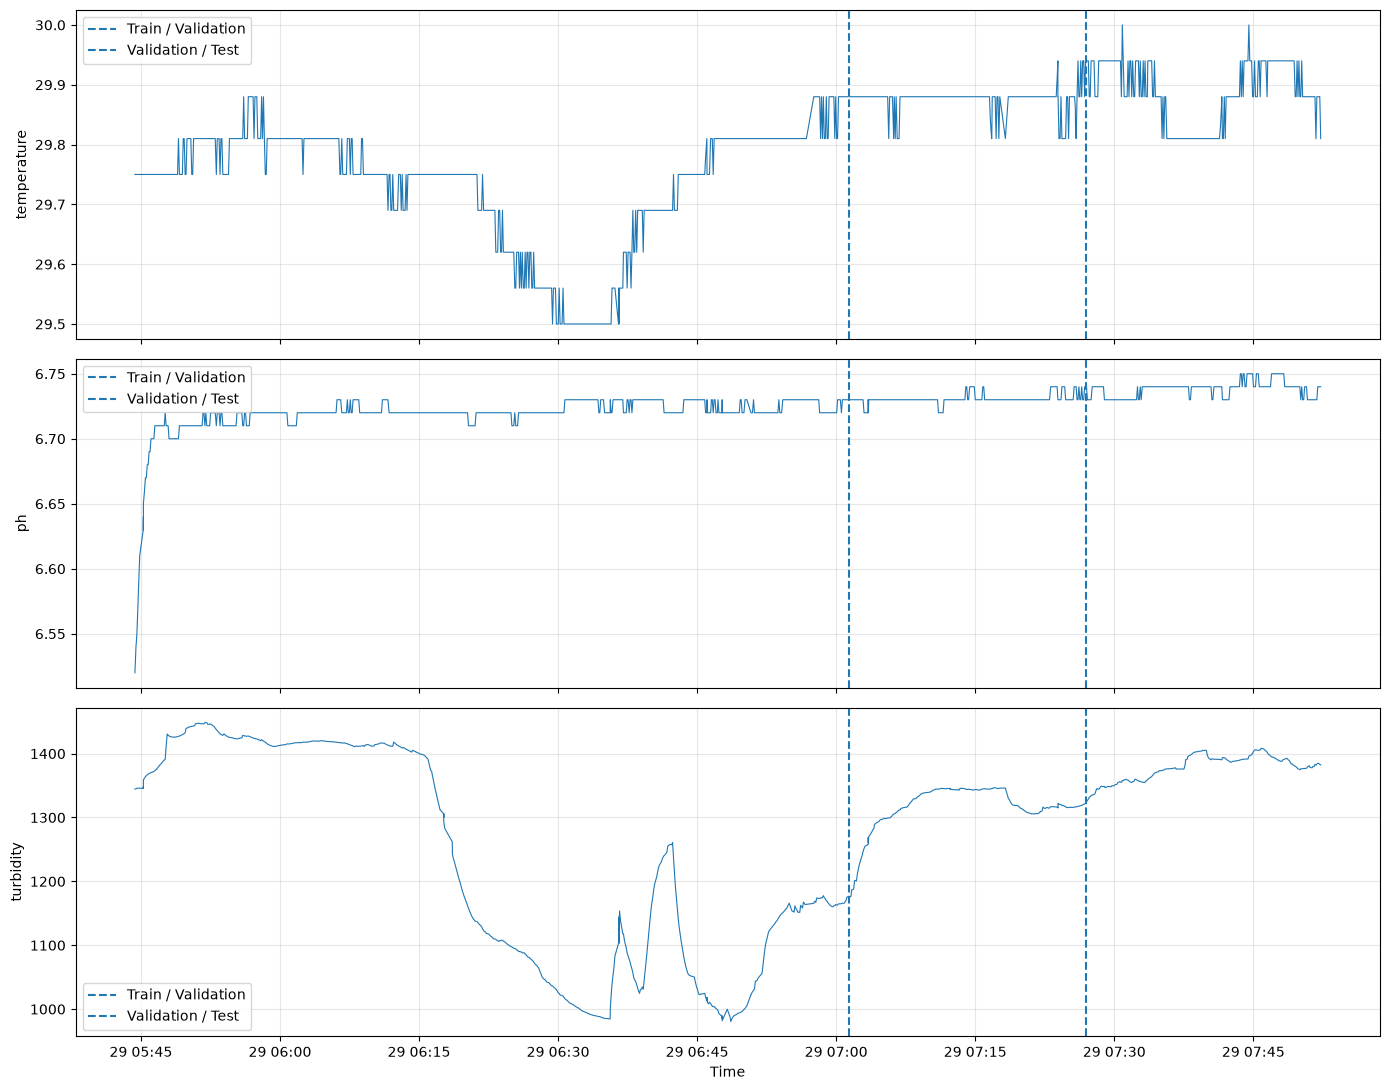

In [5]:
# ============================================================
# KIỂM TRA TREND (XU HƯỚNG) TRONG TRAIN / VALIDATION / TEST
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

features = [
    "temperature",
    "ph",
    "turbidity"
]

# ------------------------------------------------------------
# 1. Tính thay đổi từ đầu đến cuối mỗi tập
# ------------------------------------------------------------

print("=== TREND THEO TẬP DỮ LIỆU ===")

for col in features:

    print(f"\n{col}")

    for name, data in [
        ("TRAIN", train_df),
        ("VALIDATION", val_df),
        ("TEST", test_df)
    ]:

        start_value = data[col].iloc[0]
        end_value = data[col].iloc[-1]
        change = end_value - start_value

        print(
            f"{name:12s}: "
            f"{start_value:.4f} -> "
            f"{end_value:.4f} "
            f"(Δ = {change:+.4f})"
        )


# ------------------------------------------------------------
# 2. Tính slope (độ dốc) bằng hồi quy tuyến tính
# ------------------------------------------------------------

print("\n=== SLOPE (ĐỘ DỐC) ===")

for col in features:

    print(f"\n{col}")

    for name, data in [
        ("TRAIN", train_df),
        ("VALIDATION", val_df),
        ("TEST", test_df)
    ]:

        x = np.arange(len(data))
        y = data[col].values

        slope = np.polyfit(x, y, 1)[0]

        print(
            f"{name:12s}: "
            f"{slope:.8f} / sample"
        )


# ------------------------------------------------------------
# 3. Vẽ toàn bộ chuỗi dữ liệu
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

for ax, col in zip(axes, features):

    ax.plot(
        data_ai["created_at"],
        data_ai[col],
        linewidth=0.8
    )

    # Đường chia Train / Validation
    ax.axvline(
        train_df["created_at"].iloc[-1],
        linestyle="--",
        label="Train / Validation"
    )

    ax.axvline(
        val_df["created_at"].iloc[-1],
        linestyle="--",
        label="Validation / Test"
    )

    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [6]:
# Kiểm tra mức thay đổi giữa hai mẫu liên tiếp

for col in features:
    diff = data_ai[col].diff().dropna()

    print(f"\n=== {col.upper()} ===")
    print(f"Mean |Δ| : {diff.abs().mean():.6f}")
    print(f"Median |Δ|: {diff.abs().median():.6f}")
    print(f"Max |Δ|  : {diff.abs().max():.6f}")

    print("\n5 thay đổi lớn nhất:")
    print(
        diff.abs()
        .sort_values(ascending=False)
        .head(5)
    )


=== TEMPERATURE ===
Mean |Δ| : 0.011049
Median |Δ|: 0.000000
Max |Δ|  : 0.120000

5 thay đổi lớn nhất:
1007    0.12
516     0.07
1211    0.07
688     0.07
373     0.07
Name: temperature, dtype: float64

=== PH ===
Mean |Δ| : 0.001239
Median |Δ|: 0.000000
Max |Δ|  : 0.020000

5 thay đổi lớn nhất:
1    0.02
9    0.02
5    0.02
3    0.02
4    0.02
Name: ph, dtype: float64

=== TURBIDITY ===
Mean |Δ| : 2.072857
Median |Δ|: 0.830000
Max |Δ|  : 50.960000

5 thay đổi lớn nhất:
498    50.96
496    25.72
556    23.58
557    22.46
558    21.70
Name: turbidity, dtype: float64


In [7]:
# Tìm các bước nhảy lớn của turbidity

turb_diff = data_ai["turbidity"].diff().abs()

jump_threshold = turb_diff.quantile(0.99)

jumps = data_ai.loc[
    turb_diff >= jump_threshold,
    ["created_at", "temperature", "ph", "turbidity"]
].copy()

jumps["delta_turbidity"] = turb_diff[
    turb_diff >= jump_threshold
].values

print("Ngưỡng jump 99%:", jump_threshold)
print("\nCác điểm biến động lớn:")
display(jumps)

Ngưỡng jump 99%: 18.47200000000013

Các điểm biến động lớn:


,created_at,temperature,ph,turbidity,delta_turbidity
34,2026-07-29 05:47:43,29.75,6.71,1410.92,19.78
35,2026-07-29 05:47:50,29.75,6.71,1430.70,19.78
321,2026-07-29 06:18:35,29.75,6.72,1261.92,20.81
322,2026-07-29 06:18:36,29.75,6.72,1243.01,18.91
486,2026-07-29 06:35:43,29.50,6.72,1020.39,19.56
487,2026-07-29 06:35:49,29.56,6.72,1038.90,18.51
491,2026-07-29 06:36:31,29.50,6.73,1102.79,19.43
496,2026-07-29 06:36:33,29.50,6.73,1118.65,25.72
498,2026-07-29 06:36:38,29.56,6.73,1153.75,50.96
556,2026-07-29 06:42:27,29.75,6.72,1237.16,23.58


In [8]:
# Kiểm tra dữ liệu xung quanh các jump lớn của turbidity

jump_indices = [34, 35, 321, 322, 486, 487, 491, 496, 498, 556, 557, 558, 559]

for idx in jump_indices:
    start = max(0, idx - 2)
    end = min(len(data_ai), idx + 3)

    print("\n" + "=" * 70)
    print(f"INDEX {idx}")
    
    temp_view = data_ai.loc[
        start:end,
        ["created_at", "temperature", "ph", "turbidity"]
    ].copy()
    
    temp_view["dt_sec"] = (
        temp_view["created_at"]
        .diff()
        .dt.total_seconds()
    )
    
    temp_view["delta_turbidity"] = (
        temp_view["turbidity"].diff()
    )
    
    display(temp_view)


INDEX 34


,created_at,temperature,ph,turbidity,dt_sec,delta_turbidity
32,2026-07-29 05:47:31,29.75,6.71,1389.84,NaN,NaN
33,2026-07-29 05:47:37,29.75,6.72,1391.14,6.0,1.30
34,2026-07-29 05:47:43,29.75,6.71,1410.92,6.0,19.78
35,2026-07-29 05:47:50,29.75,6.71,1430.70,7.0,19.78
36,2026-07-29 05:47:56,29.75,6.71,1428.90,6.0,-1.80
37,2026-07-29 05:48:02,29.75,6.70,1427.72,6.0,-1.18



INDEX 35


,created_at,temperature,ph,turbidity,dt_sec,delta_turbidity
33,2026-07-29 05:47:37,29.75,6.72,1391.14,NaN,NaN
34,2026-07-29 05:47:43,29.75,6.71,1410.92,6.0,19.78
35,2026-07-29 05:47:50,29.75,6.71,1430.70,7.0,19.78
36,2026-07-29 05:47:56,29.75,6.71,1428.90,6.0,-1.80
37,2026-07-29 05:48:02,29.75,6.70,1427.72,6.0,-1.18
38,2026-07-29 05:48:08,29.75,6.70,1426.64,6.0,-1.08



INDEX 321


,created_at,temperature,ph,turbidity,dt_sec,delta_turbidity
319,2026-07-29 06:17:43,29.75,6.72,1288.41,NaN,NaN
320,2026-07-29 06:17:47,29.75,6.72,1282.73,4.0,-5.68
321,2026-07-29 06:18:35,29.75,6.72,1261.92,48.0,-20.81
322,2026-07-29 06:18:36,29.75,6.72,1243.01,1.0,-18.91
323,2026-07-29 06:18:42,29.75,6.72,1235.79,6.0,-7.22
324,2026-07-29 06:18:48,29.75,6.72,1231.38,6.0,-4.41


... (16 outputs left out)


INDEX 558


,created_at,temperature,ph,turbidity,dt_sec,delta_turbidity
556,2026-07-29 06:42:27,29.75,6.72,1237.16,NaN,NaN
557,2026-07-29 06:42:33,29.69,6.72,1214.70,6.0,-22.46
558,2026-07-29 06:42:39,29.69,6.72,1193.00,6.0,-21.70
559,2026-07-29 06:42:46,29.69,6.72,1173.55,7.0,-19.45
560,2026-07-29 06:42:52,29.69,6.72,1156.13,6.0,-17.42
561,2026-07-29 06:42:58,29.75,6.72,1140.34,6.0,-15.79



INDEX 559


,created_at,temperature,ph,turbidity,dt_sec,delta_turbidity
557,2026-07-29 06:42:33,29.69,6.72,1214.70,NaN,NaN
558,2026-07-29 06:42:39,29.69,6.72,1193.00,6.0,-21.70
559,2026-07-29 06:42:46,29.69,6.72,1173.55,7.0,-19.45
560,2026-07-29 06:42:52,29.69,6.72,1156.13,6.0,-17.42
561,2026-07-29 06:42:58,29.75,6.72,1140.34,6.0,-15.79
562,2026-07-29 06:43:04,29.75,6.72,1127.97,6.0,-12.37


In [9]:
# Phân loại các jump lớn của turbidity
# Kiểm tra xem sau jump tín hiệu có đảo chiều hay tiếp tục xu hướng

data_check = data_ai.copy()

data_check["delta"] = data_check["turbidity"].diff()

threshold = data_check["delta"].abs().quantile(0.99)

jump_rows = []

for i in range(1, len(data_check) - 1):

    current_delta = data_check.loc[i, "delta"]
    next_delta = data_check.loc[i + 1, "delta"]

    if abs(current_delta) >= threshold:

        # Nếu delta hiện tại và delta tiếp theo trái dấu
        # => có khả năng spike rồi quay lại
        if current_delta * next_delta < 0:
            behavior = "REVERSAL - nghi ngờ spike"
        else:
            behavior = "CONTINUATION - tiếp tục xu hướng"

        jump_rows.append({
            "index": i,
            "time": data_check.loc[i, "created_at"],
            "turbidity": data_check.loc[i, "turbidity"],
            "delta": current_delta,
            "next_delta": next_delta,
            "behavior": behavior
        })

jump_analysis = pd.DataFrame(jump_rows)

print("Ngưỡng jump:", threshold)
print("\nKết quả:")
display(jump_analysis)

print("\n=== THỐNG KÊ ===")
print(
    jump_analysis["behavior"]
    .value_counts()
)

Ngưỡng jump: 18.47200000000013

Kết quả:


,index,time,turbidity,delta,next_delta,behavior
0,34,2026-07-29 05:47:43,1410.92,19.78,19.78,CONTINUATION - tiếp tục xu hướng
1,35,2026-07-29 05:47:50,1430.70,19.78,-1.80,REVERSAL - nghi ngờ spike
2,321,2026-07-29 06:18:35,1261.92,-20.81,-18.91,CONTINUATION - tiếp tục xu hướng
3,322,2026-07-29 06:18:36,1243.01,-18.91,-7.22,CONTINUATION - tiếp tục xu hướng
4,486,2026-07-29 06:35:43,1020.39,19.56,18.51,CONTINUATION - tiếp tục xu hướng
5,487,2026-07-29 06:35:49,1038.90,18.51,15.17,CONTINUATION - tiếp tục xu hướng
6,491,2026-07-29 06:36:31,1102.79,19.43,0.00,CONTINUATION - tiếp tục xu hướng
7,496,2026-07-29 06:36:33,1118.65,-25.72,-15.86,CONTINUATION - tiếp tục xu hướng
8,498,2026-07-29 06:36:38,1153.75,50.96,-15.69,REVERSAL - nghi ngờ spike
9,556,2026-07-29 06:42:27,1237.16,-23.58,-22.46,CONTINUATION - tiếp tục xu hướng



=== THỐNG KÊ ===
behavior
CONTINUATION - tiếp tục xu hướng    11
REVERSAL - nghi ngờ spike            2
Name: count, dtype: int64


In [10]:
from sklearn.preprocessing import StandardScaler

features = ["temperature", "ph", "turbidity"]

# Tạo bộ chuẩn hóa
scaler = StandardScaler()

# Fit CHỈ trên Training set
scaler.fit(train_df[features])

# Transform cho cả 3 tập
train_scaled = scaler.transform(train_df[features])
val_scaled = scaler.transform(val_df[features])
test_scaled = scaler.transform(test_df[features])

# Chuyển về DataFrame để dễ kiểm tra
train_scaled = pd.DataFrame(
    train_scaled,
    columns=features,
    index=train_df.index
)

val_scaled = pd.DataFrame(
    val_scaled,
    columns=features,
    index=val_df.index
)

test_scaled = pd.DataFrame(
    test_scaled,
    columns=features,
    index=test_df.index
)

print("=== SCALER ===")
print("Mean:")
print(scaler.mean_)

print("\nScale (standard deviation):")
print(scaler.scale_)

print("\n=== TRAIN SCALED ===")
display(train_scaled.describe())

print("\n=== VALIDATION SCALED ===")
display(val_scaled.describe())

print("\n=== TEST SCALED ===")
display(test_scaled.describe())

=== SCALER ===
Mean:
[  29.73152682    6.71866575 1231.83911967]

Scale (standard deviation):
[1.02746367e-01 1.78256024e-02 1.68369356e+02]

=== TRAIN SCALED ===


,temperature,ph,turbidity
count,7.270000e+02,7.270000e+02,7.270000e+02
mean,1.524686e-14,-9.036696e-14,-2.345671e-16
std,1.000688e+00,1.000688e+00,1.000688e+00
min,-2.253382e+00,-1.114497e+01,-1.492487e+00
25%,-4.041683e-01,7.485022e-02,-9.135814e-01
50%,1.797940e-01,7.485022e-02,-3.339035e-01
75%,7.637562e-01,6.358411e-01,1.084080e+00
max,1.445046e+00,6.358411e-01,1.287947e+00



=== VALIDATION SCALED ===


,temperature,ph,turbidity
count,242.000000,242.000000,242.000000
mean,1.402415,0.665977,0.492300
std,0.220730,0.229408,0.209092
min,0.763756,0.074850,-0.331528
25%,1.445046,0.635841,0.449805
50%,1.445046,0.635841,0.514232
75%,1.445046,0.635841,0.664259
max,2.029008,1.196832,0.681899



=== TEST SCALED ===


,temperature,ph,turbidity
count,243.000000,243.000000,243.000000
mean,1.527954,1.095253,0.869824
std,0.499600,0.345955,0.118099
min,0.763756,0.635841,0.561509
25%,1.445046,0.635841,0.755309
50%,1.445046,1.196832,0.891319
75%,2.029008,1.196832,0.951366
max,2.612970,1.757823,1.048533


In [11]:
# Kiểm tra quá trình ổn định của pH

check_ph = data_ai[["created_at", "ph"]].copy()

print("=== pH theo các mốc thời gian ===")

# Chia thành các khoảng 1 phút
check_ph["minute"] = check_ph["created_at"].dt.floor("1min")

ph_stats = (
    check_ph
    .groupby("minute")["ph"]
    .agg(["count", "min", "max", "mean", "std"])
)

display(ph_stats.head(20))

=== pH theo các mốc thời gian ===


,count,min,max,mean,std
minute,,,,,
2026-07-29 05:44:00,6,6.52,6.61,6.563333,0.033267
2026-07-29 05:45:00,12,6.63,6.69,6.661667,0.021672
2026-07-29 05:46:00,9,6.70,6.71,6.705556,0.005270
2026-07-29 05:47:00,10,6.71,6.72,6.711000,0.003162
2026-07-29 05:48:00,10,6.70,6.70,6.700000,0.000000
2026-07-29 05:49:00,10,6.70,6.71,6.709000,0.003162
2026-07-29 05:50:00,10,6.71,6.71,6.710000,0.000000
2026-07-29 05:51:00,9,6.71,6.72,6.712222,0.004410
2026-07-29 05:52:00,7,6.71,6.72,6.714286,0.005345


In [12]:
# Tìm thời điểm pH đạt vùng ổn định

stable_ph = data_ai[
    (data_ai["ph"] >= 6.70) &
    (data_ai["ph"] <= 6.75)
].copy()

print("Số mẫu pH trong vùng 6.70–6.75:", len(stable_ph))

print("\n5 mẫu đầu tiên:")
display(
    stable_ph[
        ["created_at", "temperature", "ph", "turbidity"]
    ].head()
)

Số mẫu pH trong vùng 6.70–6.75: 1194

5 mẫu đầu tiên:


,created_at,temperature,ph,turbidity
18,2026-07-29 05:46:05,29.75,6.70,1370.21
19,2026-07-29 05:46:11,29.75,6.70,1370.76
20,2026-07-29 05:46:18,29.75,6.70,1371.36
21,2026-07-29 05:46:24,29.75,6.70,1372.05
22,2026-07-29 05:46:30,29.75,6.71,1373.27


In [13]:
# Xác định vùng vận hành tương đối ổn định trên cả 3 cảm biến

stable = (
    (data_ai["temperature"].between(29.5, 30.0)) &
    (data_ai["ph"].between(6.70, 6.75)) &
    (data_ai["turbidity"].between(980, 1450))
)

stable_df = data_ai[stable].copy()

print("Tổng số mẫu:", len(data_ai))
print("Số mẫu đạt điều kiện:", len(stable_df))
print("Tỷ lệ:", len(stable_df) / len(data_ai) * 100, "%")

print("\nThời điểm đầu:")
print(stable_df["created_at"].iloc[0])

print("\nThời điểm cuối:")
print(stable_df["created_at"].iloc[-1])

print("\n=== THỐNG KÊ ===")
display(stable_df[features].describe())

Tổng số mẫu: 1212
Số mẫu đạt điều kiện: 1194
Tỷ lệ: 98.51485148514851 %

Thời điểm đầu:
2026-07-29 05:46:05

Thời điểm cuối:
2026-07-29 07:52:16

=== THỐNG KÊ ===


,temperature,ph,turbidity
count,1194.000000,1194.000000,1194.000000
mean,29.792404,6.726399,1276.589422
std,0.112202,0.009387,145.374968
min,29.500000,6.700000,980.550000
25%,29.750000,6.720000,1153.280000
50%,29.810000,6.730000,1343.215000
75%,29.880000,6.730000,1398.692500
max,30.000000,6.750000,1448.690000


In [14]:
# ==========================================
# CHỐT DATASET NORMAL CHO AI
# ==========================================

features = ["temperature", "ph", "turbidity"]

# Dataset normal đã xác định
normal_df = stable_df[
    ["created_at"] + features
].copy()

normal_df = normal_df.sort_values("created_at").reset_index(drop=True)

# Time-series split (chia dữ liệu theo thời gian)
n = len(normal_df)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

train_df = normal_df.iloc[:train_end].copy()
val_df = normal_df.iloc[train_end:val_end].copy()
test_df = normal_df.iloc[val_end:].copy()

print("=== DATASET NORMAL ===")
print("Total:", len(normal_df))

print("\nTraining set (tập huấn luyện):", len(train_df))
print(
    train_df["created_at"].iloc[0],
    "->",
    train_df["created_at"].iloc[-1]
)

print("\nValidation set (tập kiểm định):", len(val_df))
print(
    val_df["created_at"].iloc[0],
    "->",
    val_df["created_at"].iloc[-1]
)

print("\nTest set (tập kiểm tra):", len(test_df))
print(
    test_df["created_at"].iloc[0],
    "->",
    test_df["created_at"].iloc[-1]
)

=== DATASET NORMAL ===
Total: 1194

Training set (tập huấn luyện): 716
2026-07-29 05:46:05 -> 2026-07-29 07:02:05

Validation set (tập kiểm định): 239
2026-07-29 07:02:11 -> 2026-07-29 07:27:24

Test set (tập kiểm tra): 239
2026-07-29 07:27:30 -> 2026-07-29 07:52:16


In [15]:
# ==========================================
# STANDARDIZATION LẠI
# ==========================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Chỉ fit trên Training set
scaler.fit(train_df[features])

train_scaled = scaler.transform(train_df[features])
val_scaled = scaler.transform(val_df[features])
test_scaled = scaler.transform(test_df[features])

train_scaled = pd.DataFrame(
    train_scaled,
    columns=features,
    index=train_df.index
)

val_scaled = pd.DataFrame(
    val_scaled,
    columns=features,
    index=val_df.index
)

test_scaled = pd.DataFrame(
    test_scaled,
    columns=features,
    index=test_df.index
)

print("=== SCALER MỚI ===")
for feature, mean, std in zip(
    features,
    scaler.mean_,
    scaler.scale_
):
    print(f"{feature}: mean={mean:.6f}, std={std:.6f}")

print("\n=== TRAIN SCALED ===")
display(train_scaled.describe())

print("\n=== VALIDATION SCALED ===")
display(val_scaled.describe())

print("\n=== TEST SCALED ===")
display(test_scaled.describe())

=== SCALER MỚI ===
temperature: mean=29.732514, std=0.104523
ph: mean=6.721034, std=0.006834
turbidity: mean=1228.318268, std=168.546365

=== TRAIN SCALED ===


,temperature,ph,turbidity
count,7.160000e+02,7.160000e+02,7.160000e+02
mean,-1.984756e-15,-3.318512e-14,-4.763415e-16
std,1.000699e+00,1.000699e+00,1.000699e+00
min,-2.224534e+00,-3.077985e+00,-1.470030e+00
25%,-4.067444e-01,-1.512423e-01,-9.066394e-01
50%,1.672944e-01,-1.512423e-01,-3.231649e-01
75%,7.413331e-01,1.312129e+00,1.104691e+00
max,1.411045e+00,1.312129e+00,1.307484e+00



=== VALIDATION SCALED ===


,temperature,ph,turbidity
count,239.000000,239.000000,239.000000
mean,1.373416,1.391727,0.536180
std,0.225402,0.602116,0.164534
min,0.741333,-0.151242,-0.164218
25%,1.411045,1.312129,0.481480
50%,1.411045,1.312129,0.537192
75%,1.411045,1.312129,0.684540
max,1.985084,2.775501,0.702072



=== TEST SCALED ===


,temperature,ph,turbidity
count,239.000000,239.000000,239.000000
mean,1.489105,2.530585,0.894606
std,0.493089,0.896407,0.112870
min,0.741333,1.312129,0.628324
25%,1.411045,1.312129,0.778817
50%,1.411045,2.775501,0.913883
75%,1.985084,2.775501,0.972028
max,2.559123,4.238872,1.068322


In [16]:
# ==========================================
# KIỂM TRA TEMPORAL DRIFT
# ==========================================

for col in features:

    print("\n" + "=" * 60)
    print(col.upper())

    # Chia thành 10 đoạn theo thứ tự thời gian
    temp = data_ai[["created_at", col]].copy()
    temp["segment"] = pd.qcut(
        temp.index,
        q=10,
        labels=False
    )

    stats = (
        temp
        .groupby("segment")
        .agg(
            start_time=("created_at", "first"),
            end_time=("created_at", "last"),
            mean=(col, "mean"),
            std=(col, "std"),
            min=(col, "min"),
            max=(col, "max")
        )
    )

    display(stats)


TEMPERATURE


,start_time,end_time,mean,std,min,max
segment,,,,,,
0,2026-07-29 05:44:21,2026-07-29 05:56:47,29.780820,0.034750,29.75,29.88
1,2026-07-29 05:56:54,2026-07-29 06:09:55,29.799752,0.033478,29.75,29.88
2,2026-07-29 06:10:02,2026-07-29 06:22:48,29.736612,0.025085,29.69,29.75
3,2026-07-29 06:22:53,2026-07-29 06:35:37,29.555620,0.058021,29.50,29.69
4,2026-07-29 06:35:38,2026-07-29 06:47:33,29.688595,0.084807,29.50,29.81
5,2026-07-29 06:47:41,2026-07-29 07:01:23,29.827355,0.030353,29.81,29.88
6,2026-07-29 07:01:29,2026-07-29 07:13:35,29.876529,0.015259,29.81,29.88
7,2026-07-29 07:13:41,2026-07-29 07:27:00,29.874711,0.028257,29.81,29.94
8,2026-07-29 07:27:06,2026-07-29 07:39:43,29.880661,0.055972,29.81,30.00



PH


,start_time,end_time,mean,std,min,max
segment,,,,,,
0,2026-07-29 05:44:21,2026-07-29 05:56:47,6.698525,0.035830,6.52,6.72
1,2026-07-29 05:56:54,2026-07-29 06:09:55,6.720579,0.004143,6.71,6.73
2,2026-07-29 06:10:02,2026-07-29 06:22:48,6.719917,0.003535,6.71,6.73
3,2026-07-29 06:22:53,2026-07-29 06:35:37,6.722397,0.005327,6.71,6.73
4,2026-07-29 06:35:38,2026-07-29 06:47:33,6.726364,0.004830,6.72,6.73
5,2026-07-29 06:47:41,2026-07-29 07:01:23,6.724380,0.004982,6.72,6.73
6,2026-07-29 07:01:29,2026-07-29 07:13:35,6.728843,0.003212,6.72,6.73
7,2026-07-29 07:13:41,2026-07-29 07:27:00,6.732231,0.004181,6.73,6.74
8,2026-07-29 07:27:06,2026-07-29 07:39:43,6.736198,0.004874,6.73,6.74



TURBIDITY


,start_time,end_time,mean,std,min,max
segment,,,,,,
0,2026-07-29 05:44:21,2026-07-29 05:56:47,1414.490164,31.955805,1344.50,1448.69
1,2026-07-29 05:56:54,2026-07-29 06:09:55,1416.569256,3.551461,1410.72,1425.57
2,2026-07-29 06:10:02,2026-07-29 06:22:48,1308.984380,116.086687,1113.62,1418.16
3,2026-07-29 06:22:53,2026-07-29 06:35:37,1045.334463,44.609797,984.71,1112.59
4,2026-07-29 06:35:38,2026-07-29 06:47:33,1096.926281,80.777673,990.33,1260.74
5,2026-07-29 06:47:41,2026-07-29 07:01:23,1107.220661,72.769574,980.55,1177.61
6,2026-07-29 07:01:29,2026-07-29 07:13:35,1303.633140,45.111861,1176.02,1345.76
7,2026-07-29 07:13:41,2026-07-29 07:27:00,1325.821405,14.344833,1305.66,1346.65
8,2026-07-29 07:27:06,2026-07-29 07:39:43,1366.275785,20.789359,1326.38,1405.15


In [18]:
# ============================================================
# NORMAL DATASET FINAL
# Main device + sau startup + 3 sensors ONLINE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------
df = pd.read_csv("../data/sensor_data_clean.tsv", sep="\t")

df["created_at"] = pd.to_datetime(df["created_at"])

df = (
    df.sort_values("created_at")
      .reset_index(drop=True)
)

MAIN_DEVICE = "8CD0B2A87FA6"

features = [
    "temperature",
    "ph",
    "turbidity"
]

# ------------------------------------------------------------
# 2. Chỉ lấy device chính
# ------------------------------------------------------------
df_main = df[
    df["device_id"] == MAIN_DEVICE
].copy()

# ------------------------------------------------------------
# 3. Sau thời điểm startup ổn định
# ------------------------------------------------------------
NORMAL_START = pd.Timestamp("2026-07-29 05:46:05")

df_normal = df_main[
    df_main["created_at"] >= NORMAL_START
].copy()

# ------------------------------------------------------------
# 4. Chỉ lấy thời điểm cả 3 sensor đều ONLINE
# ------------------------------------------------------------
normal_df = df_normal[
    (df_normal["temp_status"] == "online") &
    (df_normal["ph_status"] == "online") &
    (df_normal["tur_status"] == "online")
].copy()

# ------------------------------------------------------------
# 5. Loại dữ liệu thiếu
# ------------------------------------------------------------
normal_df = normal_df.dropna(
    subset=features
)

normal_df = (
    normal_df
    .sort_values("created_at")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. Kiểm tra
# ------------------------------------------------------------
print("===== FINAL NORMAL DATASET =====")

print("Số mẫu:", len(normal_df))

print(
    "Thời gian:",
    normal_df["created_at"].min(),
    "→",
    normal_df["created_at"].max()
)

print("\nSensor status:")
print("Temperature:", normal_df["temp_status"].unique())
print("pH:", normal_df["ph_status"].unique())
print("Turbidity:", normal_df["tur_status"].unique())

print("\nMissing values:")
print(normal_df[features].isna().sum())

# ------------------------------------------------------------
# 7. Time-series split
# ------------------------------------------------------------
n = len(normal_df)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

train_df = normal_df.iloc[:train_end].copy()
val_df   = normal_df.iloc[train_end:val_end].copy()
test_df  = normal_df.iloc[val_end:].copy()

print("\n===== DATASET SPLIT =====")

print("Training set:", len(train_df))
print("Validation set:", len(val_df))
print("Test set:", len(test_df))

print("\nTraining:")
print(train_df["created_at"].min(), "→",
      train_df["created_at"].max())

print("\nValidation:")
print(val_df["created_at"].min(), "→",
      val_df["created_at"].max())

print("\nTest:")
print(test_df["created_at"].min(), "→",
      test_df["created_at"].max())

# ------------------------------------------------------------
# 8. Normal behavior profile
# ------------------------------------------------------------
print("\n===== NORMAL BEHAVIOR PROFILE =====")

profile = train_df[features].describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]

print(profile)

# ------------------------------------------------------------
# 9. Correlation
# ------------------------------------------------------------
print("\n===== CORRELATION MATRIX =====")

corr = train_df[features].corr()

print(corr)

# ------------------------------------------------------------
# 10. Standardization
#     StandardScaler chỉ fit trên TRAIN
# ------------------------------------------------------------
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(
    train_df[features]
)

X_val = scaler.transform(
    val_df[features]
)

X_test = scaler.transform(
    test_df[features]
)

print("\n===== STANDARDIZATION =====")

print("Scaler mean:")
print(scaler.mean_)

print("\nScaler scale:")
print(scaler.scale_)

print("\nTraining scaled mean:")
print(X_train.mean(axis=0))

print("\nTraining scaled std:")
print(X_train.std(axis=0))

# ------------------------------------------------------------
# 11. Lưu profile để dùng cho các model sau
# ------------------------------------------------------------
normal_profile = {
    "features": features,
    "mean": scaler.mean_,
    "std": scaler.scale_
}

print("\n===== READY FOR AI =====")
print("Normal dataset đã sẵn sàng.")

===== FINAL NORMAL DATASET =====
Số mẫu: 1164
Thời gian: 2026-07-29 05:46:05 → 2026-07-29 07:52:16

Sensor status:
Temperature: <StringArray>
['online']
Length: 1, dtype: str
pH: <StringArray>
['online']
Length: 1, dtype: str
Turbidity: <StringArray>
['online']
Length: 1, dtype: str

Missing values:
temperature    0
ph             0
turbidity      0
dtype: int64

===== DATASET SPLIT =====
Training set: 698
Validation set: 233
Test set: 233

Training:
2026-07-29 05:46:05 → 2026-07-29 07:01:35

Validation:
2026-07-29 07:01:41 → 2026-07-29 07:27:06

Test:
2026-07-29 07:27:12 → 2026-07-29 07:52:16

===== NORMAL BEHAVIOR PROFILE =====
                    mean         std     min       25%      50%        75%  \
temperature    29.730845    0.104455   29.50    29.690    29.75    29.8100   
ph              6.720974    0.006853    6.70     6.720     6.72     6.7300   
turbidity    1230.529957  168.556557  980.55  1078.765  1173.85  1415.0725   

                 max  
temperature    29.88  
ph 

===== TRAIN STATISTICS =====
Mean:
temperature      29.730845
ph                6.720974
turbidity      1230.529957
dtype: float64

Std:
temperature      0.104455
ph               0.006853
turbidity      168.556557
dtype: float64

===== GROUND TRUTH =====
Normal: 211
Anomaly: 22
Anomaly ratio: 0.0944206008583691

===== ANOMALY TYPES =====
normal                        211
sensor_stuck                   12
multivariate_inconsistency      4
point_spike                     3
point_drop                      3
Name: count, dtype: int64

===== INJECTED ANOMALIES =====
             created_at  temperature    ph    turbidity  \
30  2026-07-29 07:30:16    29.940000  6.73  2026.006229   
50  2026-07-29 07:32:18    29.522182  6.73  1360.060000   
70  2026-07-29 07:34:32    29.880000  6.74  1370.430000   
71  2026-07-29 07:34:38    29.880000  6.74  1370.430000   
72  2026-07-29 07:34:45    29.880000  6.74  1370.430000   
73  2026-07-29 07:34:51    29.880000  6.74  1370.430000   
74  2026-07-29 07:

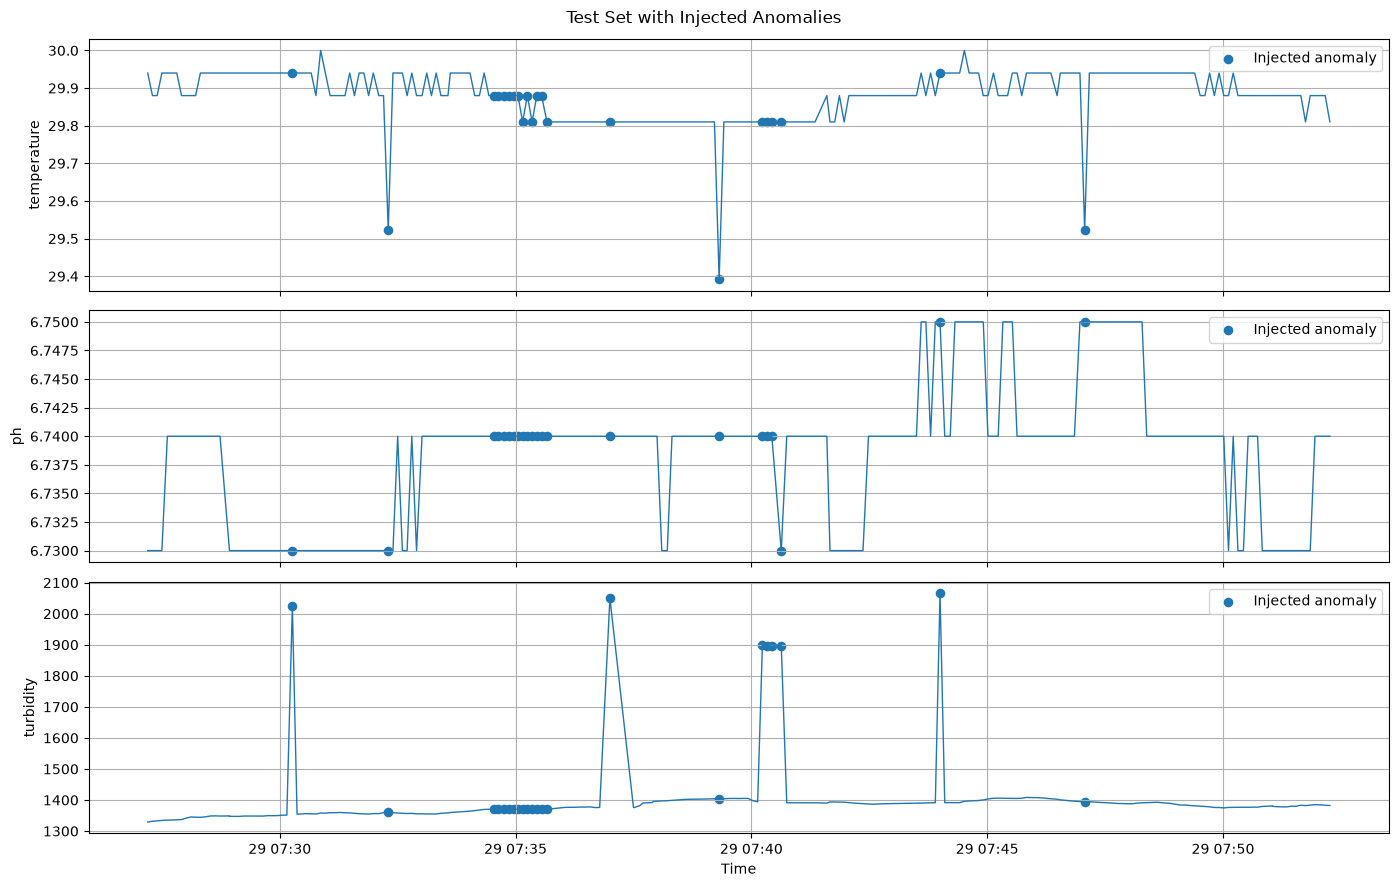

In [19]:
# ============================================================
# BƯỚC 2 - GROUND TRUTH + ANOMALY INJECTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

features = [
    "temperature",
    "ph",
    "turbidity"
]

# ------------------------------------------------------------
# 1. Tạo bản sao TEST SET
# ------------------------------------------------------------

test_injected = test_df[
    ["created_at"] + features
].copy().reset_index(drop=True)

# Ground Truth:
# 0 = Normal
# 1 = Anomaly

y_test = np.zeros(len(test_injected), dtype=int)

# Lưu loại anomaly để phân tích sau
anomaly_type = np.array(
    ["normal"] * len(test_injected),
    dtype=object
)

# ------------------------------------------------------------
# 2. Thống kê TRAINING SET
#    Dùng TRAIN để xác định mức độ injection
# ------------------------------------------------------------

train_mean = train_df[features].mean()
train_std = train_df[features].std()

print("===== TRAIN STATISTICS =====")
print("Mean:")
print(train_mean)

print("\nStd:")
print(train_std)

# ------------------------------------------------------------
# 3. Hàm đánh dấu anomaly
# ------------------------------------------------------------

def mark_anomaly(indexes, anomaly_name):
    y_test[indexes] = 1
    anomaly_type[indexes] = anomaly_name


# ============================================================
# 4. POINT SPIKE
# ============================================================

# 3 điểm khác nhau
spike_indices = [30, 90, 150]

for idx in spike_indices:

    # Spike turbidity + 4 sigma
    test_injected.loc[idx, "turbidity"] = (
        test_injected.loc[idx, "turbidity"]
        + 4 * train_std["turbidity"]
    )

mark_anomaly(
    spike_indices,
    "point_spike"
)


# ============================================================
# 5. POINT DROP
# ============================================================

drop_indices = [50, 110, 180]

for idx in drop_indices:

    # Drop temperature - 4 sigma
    test_injected.loc[idx, "temperature"] = (
        test_injected.loc[idx, "temperature"]
        - 4 * train_std["temperature"]
    )

mark_anomaly(
    drop_indices,
    "point_drop"
)


# ============================================================
# 6. SENSOR STUCK
# ============================================================

stuck_start = 70
stuck_length = 12

stuck_indices = np.arange(
    stuck_start,
    stuck_start + stuck_length
)

# Giữ nguyên giá trị đầu tiên
stuck_value = test_injected.loc[
    stuck_start,
    "turbidity"
]

test_injected.loc[
    stuck_indices,
    "turbidity"
] = stuck_value

mark_anomaly(
    stuck_indices,
    "sensor_stuck"
)


# ============================================================
# 7. MULTIVARIATE INCONSISTENCY
# ============================================================

multi_indices = [120, 121, 122, 123]

# Làm turbidity tăng mạnh trong khi
# temperature và pH giữ nguyên.
for idx in multi_indices:

    test_injected.loc[
        idx,
        "turbidity"
    ] = (
        test_injected.loc[idx, "turbidity"]
        + 3 * train_std["turbidity"]
    )

mark_anomaly(
    multi_indices,
    "multivariate_inconsistency"
)


# ============================================================
# 8. Tổng hợp Ground Truth
# ============================================================

ground_truth = test_injected.copy()

ground_truth["anomaly"] = y_test
ground_truth["anomaly_type"] = anomaly_type


# ============================================================
# 9. Kiểm tra kết quả
# ============================================================

print("\n===== GROUND TRUTH =====")

print(
    "Normal:",
    np.sum(y_test == 0)
)

print(
    "Anomaly:",
    np.sum(y_test == 1)
)

print(
    "Anomaly ratio:",
    np.mean(y_test)
)

print("\n===== ANOMALY TYPES =====")

print(
    pd.Series(anomaly_type)
    .value_counts()
)


# ============================================================
# 10. Hiển thị các anomaly
# ============================================================

print("\n===== INJECTED ANOMALIES =====")

print(
    ground_truth[
        ground_truth["anomaly"] == 1
    ][
        ["created_at"] + features +
        ["anomaly_type"]
    ]
)


# ============================================================
# 11. Vẽ TEST SET SAU KHI INJECTION
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 9),
    sharex=True
)

for i, col in enumerate(features):

    axes[i].plot(
        test_injected["created_at"],
        test_injected[col],
        linewidth=1
    )

    anomaly_mask = y_test == 1

    axes[i].scatter(
        test_injected.loc[
            anomaly_mask,
            "created_at"
        ],
        test_injected.loc[
            anomaly_mask,
            col
        ],
        s=35,
        label="Injected anomaly"
    )

    axes[i].set_ylabel(col)
    axes[i].grid(True)
    axes[i].legend()

axes[-1].set_xlabel("Time")

plt.suptitle(
    "Test Set with Injected Anomalies"
)

plt.tight_layout()
plt.show()

===== VALIDATION Z-SCORE =====
Mean score: 1.5808965790921998
Std score: 0.4261079138291156
Max score: 2.7780967757658126

Percentiles:
90%: 2.7780967757658126
95%: 2.7780967757658126
97%: 2.7780967757658126
98%: 2.7780967757658126
99%: 2.7780967757658126

===== THRESHOLD =====
Z-score threshold: 2.7780967757658126

===== STATISTICAL BASELINE RESULT =====
Ground Truth anomalies: 22
Predicted anomalies: 166

Precision: 0.12650602409638553
Recall: 0.9545454545454546
F1-score: 0.22340425531914893

===== CONFUSION MATRIX =====
[[ 66 145]
 [  1  21]]

                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal       0.99      0.31      0.47       211
     Anomaly       0.13      0.95      0.22        22

    accuracy                           0.37       233
   macro avg       0.56      0.63      0.35       233
weighted avg       0.90     

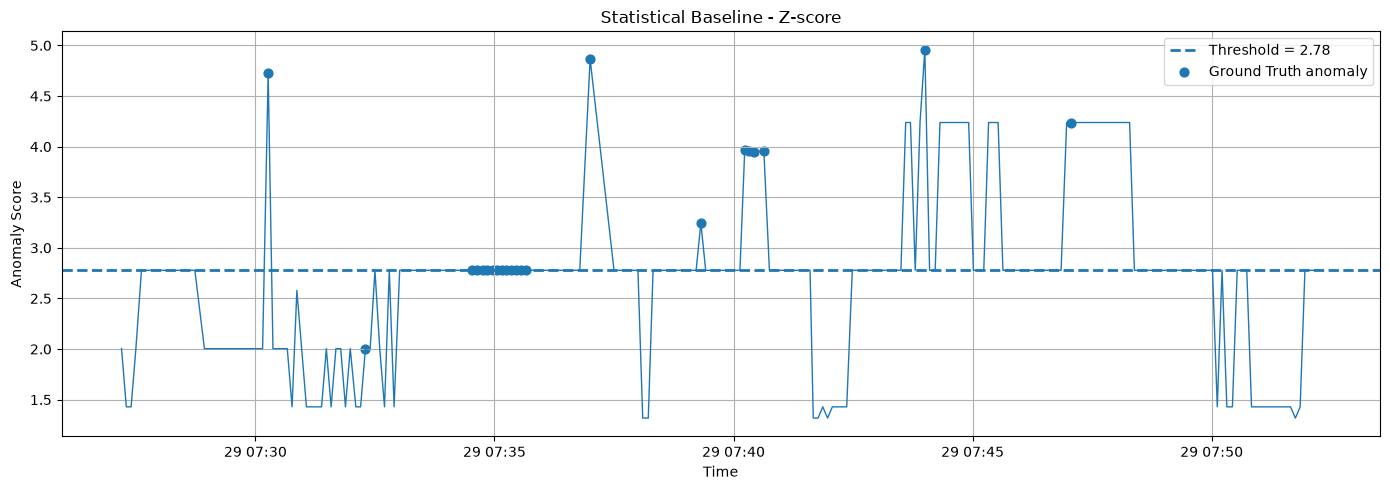

In [20]:
# ============================================================
# BƯỚC 3 - STATISTICAL BASELINE: Z-SCORE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

features = [
    "temperature",
    "ph",
    "turbidity"
]

# ============================================================
# 1. Tính Z-score cho VALIDATION SET
# ============================================================

# scaler đã fit trên TRAINING SET
X_val_scaled = scaler.transform(
    val_df[features]
)

val_scores = np.max(
    np.abs(X_val_scaled),
    axis=1
)

print("===== VALIDATION Z-SCORE =====")

print("Mean score:", val_scores.mean())
print("Std score:", val_scores.std())
print("Max score:", val_scores.max())

print("\nPercentiles:")

for p in [90, 95, 97, 98, 99]:
    print(
        f"{p}%:",
        np.percentile(val_scores, p)
    )


# ============================================================
# 2. Chọn threshold từ VALIDATION
# ============================================================

THRESHOLD = np.percentile(
    val_scores,
    99
)

print("\n===== THRESHOLD =====")
print("Z-score threshold:", THRESHOLD)


# ============================================================
# 3. Tính Z-score cho TEST SET
# ============================================================

X_test_scaled = scaler.transform(
    test_injected[features]
)

test_scores = np.max(
    np.abs(X_test_scaled),
    axis=1
)

# Prediction
y_pred = (
    test_scores >= THRESHOLD
).astype(int)


# ============================================================
# 4. Kết quả
# ============================================================

print("\n===== STATISTICAL BASELINE RESULT =====")

print("Ground Truth anomalies:", y_test.sum())
print("Predicted anomalies:", y_pred.sum())

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("\nPrecision:", precision)
print("Recall:", recall)
print("F1-score:", f1)


# ============================================================
# 5. Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n===== CONFUSION MATRIX =====")

print(cm)

print("""
                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP
""")


# ============================================================
# 6. Classification Report
# ============================================================

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal",
            "Anomaly"
        ],
        zero_division=0
    )
)


# ============================================================
# 7. Phân tích từng loại anomaly
# ============================================================

result = test_injected.copy()

result["ground_truth"] = y_test
result["prediction"] = y_pred
result["anomaly_score"] = test_scores
result["anomaly_type"] = anomaly_type

print("\n===== RESULT BY ANOMALY TYPE =====")

for anomaly in [
    "point_spike",
    "point_drop",
    "sensor_stuck",
    "multivariate_inconsistency"
]:

    subset = result[
        result["anomaly_type"] == anomaly
    ]

    detected = (
        subset["prediction"] == 1
    ).sum()

    total = len(subset)

    print(
        f"{anomaly}: "
        f"{detected}/{total} detected"
    )


# ============================================================
# 8. Những mẫu bị model đánh dấu anomaly
# ============================================================

print("\n===== PREDICTED ANOMALIES =====")

print(
    result[
        result["prediction"] == 1
    ][
        [
            "created_at",
            "temperature",
            "ph",
            "turbidity",
            "ground_truth",
            "prediction",
            "anomaly_score",
            "anomaly_type"
        ]
    ]
)


# ============================================================
# 9. Vẽ anomaly score
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    test_injected["created_at"],
    test_scores,
    linewidth=1
)

plt.axhline(
    THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {THRESHOLD:.2f}"
)

# Ground truth anomaly
gt_mask = y_test == 1

plt.scatter(
    test_injected.loc[
        gt_mask,
        "created_at"
    ],
    test_scores[gt_mask],
    s=40,
    label="Ground Truth anomaly"
)

plt.xlabel("Time")
plt.ylabel("Anomaly Score")
plt.title(
    "Statistical Baseline - Z-score"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

===== ISOLATION FOREST =====
Training samples: 698
Number of trees: 200

===== VALIDATION SCORE =====
Mean: 0.12962208139952763
Std: 0.0183675851387658
Min: 0.07852964353658742
Max: 0.14354491369859101

Percentiles:
90%: 0.14310964728110342
95%: 0.14354491369859101
97%: 0.14354491369859101
98%: 0.14354491369859101
99%: 0.14354491369859101

===== THRESHOLD =====
Isolation Forest threshold: 0.14354491369859101

===== ISOLATION FOREST RESULT =====
Ground Truth anomalies: 22
Predicted anomalies: 99

Precision: 0.050505050505050504
Recall: 0.22727272727272727
F1-score: 0.08264462809917356

===== CONFUSION MATRIX =====
[[117  94]
 [ 17   5]]

                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal       0.87      0.55      0.68       211
     Anomaly       0.05      0.23      0.08        22

    accuracy                           0.52 

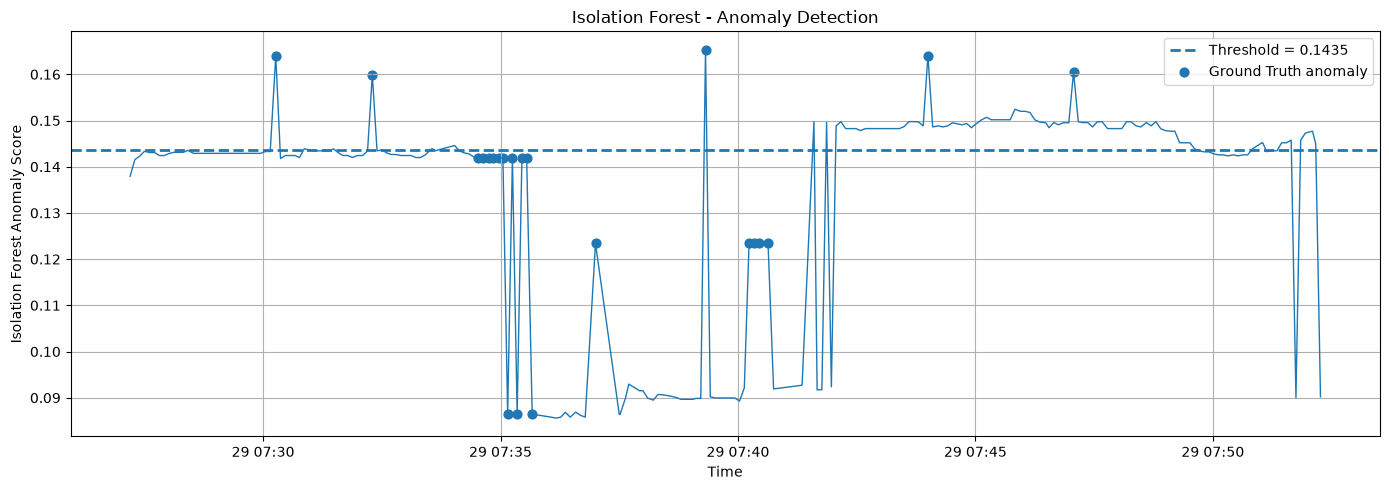

In [21]:
# ============================================================
# BƯỚC 4 - ISOLATION FOREST
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

features = [
    "temperature",
    "ph",
    "turbidity"
]

# ============================================================
# 1. Chuẩn bị dữ liệu
# ============================================================

# Training: chỉ normal data
X_train = train_df[features].values

# Validation: chỉ normal data
X_val = val_df[features].values

# Test: dữ liệu đã được anomaly injection
X_test = test_injected[features].values


# ============================================================
# 2. Train Isolation Forest
# ============================================================

iso_forest = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

iso_forest.fit(X_train)

print("===== ISOLATION FOREST =====")
print("Training samples:", len(X_train))
print("Number of trees:", iso_forest.n_estimators)


# ============================================================
# 3. Tính anomaly score
# ============================================================

# decision_function:
# score càng thấp -> càng bất thường
#
# Đổi dấu để:
# score càng cao -> càng bất thường

val_scores = -iso_forest.decision_function(X_val)

test_scores = -iso_forest.decision_function(X_test)


# ============================================================
# 4. Kiểm tra Validation score
# ============================================================

print("\n===== VALIDATION SCORE =====")

print("Mean:", val_scores.mean())
print("Std:", val_scores.std())
print("Min:", val_scores.min())
print("Max:", val_scores.max())

print("\nPercentiles:")

for p in [90, 95, 97, 98, 99]:
    print(
        f"{p}%:",
        np.percentile(val_scores, p)
    )


# ============================================================
# 5. Chọn threshold từ Validation
# ============================================================

THRESHOLD_IF = np.percentile(
    val_scores,
    99
)

print("\n===== THRESHOLD =====")
print(
    "Isolation Forest threshold:",
    THRESHOLD_IF
)


# ============================================================
# 6. Predict TEST
# ============================================================

y_pred_if = (
    test_scores >= THRESHOLD_IF
).astype(int)


# ============================================================
# 7. Evaluation
# ============================================================

print("\n===== ISOLATION FOREST RESULT =====")

print(
    "Ground Truth anomalies:",
    y_test.sum()
)

print(
    "Predicted anomalies:",
    y_pred_if.sum()
)

precision_if = precision_score(
    y_test,
    y_pred_if,
    zero_division=0
)

recall_if = recall_score(
    y_test,
    y_pred_if,
    zero_division=0
)

f1_if = f1_score(
    y_test,
    y_pred_if,
    zero_division=0
)

print("\nPrecision:", precision_if)
print("Recall:", recall_if)
print("F1-score:", f1_if)


# ============================================================
# 8. Confusion Matrix
# ============================================================

cm_if = confusion_matrix(
    y_test,
    y_pred_if
)

print("\n===== CONFUSION MATRIX =====")
print(cm_if)

print("""
                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP
""")


# ============================================================
# 9. Classification Report
# ============================================================

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test,
        y_pred_if,
        target_names=[
            "Normal",
            "Anomaly"
        ],
        zero_division=0
    )
)


# ============================================================
# 10. Phân tích từng loại anomaly
# ============================================================

result_if = test_injected.copy()

result_if["ground_truth"] = y_test
result_if["prediction"] = y_pred_if
result_if["anomaly_score"] = test_scores
result_if["anomaly_type"] = anomaly_type

print("\n===== RESULT BY ANOMALY TYPE =====")

for anomaly in [
    "point_spike",
    "point_drop",
    "sensor_stuck",
    "multivariate_inconsistency"
]:

    subset = result_if[
        result_if["anomaly_type"] == anomaly
    ]

    detected = (
        subset["prediction"] == 1
    ).sum()

    total = len(subset)

    print(
        f"{anomaly}: "
        f"{detected}/{total} detected"
    )


# ============================================================
# 11. Các mẫu bị phát hiện
# ============================================================

print("\n===== PREDICTED ANOMALIES =====")

print(
    result_if[
        result_if["prediction"] == 1
    ][
        [
            "created_at",
            "temperature",
            "ph",
            "turbidity",
            "ground_truth",
            "prediction",
            "anomaly_score",
            "anomaly_type"
        ]
    ]
)


# ============================================================
# 12. Vẽ Anomaly Score
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    test_injected["created_at"],
    test_scores,
    linewidth=1
)

plt.axhline(
    THRESHOLD_IF,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {THRESHOLD_IF:.4f}"
)

# Ground Truth
gt_mask = y_test == 1

plt.scatter(
    test_injected.loc[
        gt_mask,
        "created_at"
    ],
    test_scores[gt_mask],
    s=40,
    label="Ground Truth anomaly"
)

plt.xlabel("Time")
plt.ylabel("Isolation Forest Anomaly Score")

plt.title(
    "Isolation Forest - Anomaly Detection"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [2]:
# ============================================================
# KHÔI PHỤC ENVIRONMENT CHO AUTOENCODER
# ============================================================

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

df = pd.read_csv("../data/sensor_data_clean.tsv", sep="\t")

df["created_at"] = pd.to_datetime(df["created_at"])

df = (
    df.sort_values("created_at")
      .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Main device
# ------------------------------------------------------------

MAIN_DEVICE = "8CD0B2A87FA6"

features = [
    "temperature",
    "ph",
    "turbidity"
]

df_main = df[
    df["device_id"] == MAIN_DEVICE
].copy()

# ------------------------------------------------------------
# 3. Normal dataset
# ------------------------------------------------------------

NORMAL_START = pd.Timestamp(
    "2026-07-29 05:46:05"
)

df_normal = df_main[
    df_main["created_at"] >= NORMAL_START
].copy()

# Cả 3 sensor phải online
normal_df = df_normal[
    (df_normal["temp_status"] == "online") &
    (df_normal["ph_status"] == "online") &
    (df_normal["tur_status"] == "online")
].copy()

normal_df = normal_df.dropna(
    subset=features
)

normal_df = (
    normal_df
    .sort_values("created_at")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Time-series split
# ------------------------------------------------------------

n = len(normal_df)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

train_df = normal_df.iloc[:train_end].copy()
val_df = normal_df.iloc[train_end:val_end].copy()
test_df = normal_df.iloc[val_end:].copy()

# ------------------------------------------------------------
# 5. StandardScaler
# ------------------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(
    train_df[features]
).astype("float32")

X_val = scaler.transform(
    val_df[features]
).astype("float32"
)

X_test_normal = scaler.transform(
    test_df[features]
).astype("float32")

# ------------------------------------------------------------
# 6. Tạo lại Test Set + Anomaly Injection
# ------------------------------------------------------------

np.random.seed(42)

test_injected = test_df[
    ["created_at"] + features
].copy().reset_index(drop=True)

y_test = np.zeros(
    len(test_injected),
    dtype=int
)

anomaly_type = np.array(
    ["normal"] * len(test_injected),
    dtype=object
)

train_std = train_df[features].std()


def mark_anomaly(indexes, anomaly_name):
    y_test[indexes] = 1
    anomaly_type[indexes] = anomaly_name


# ------------------------------------------------------------
# Point Spike
# ------------------------------------------------------------

spike_indices = [30, 90, 150]

for idx in spike_indices:

    test_injected.loc[
        idx,
        "turbidity"
    ] += 4 * train_std["turbidity"]

mark_anomaly(
    spike_indices,
    "point_spike"
)


# ------------------------------------------------------------
# Point Drop
# ------------------------------------------------------------

drop_indices = [50, 110, 180]

for idx in drop_indices:

    test_injected.loc[
        idx,
        "temperature"
    ] -= 4 * train_std["temperature"]

mark_anomaly(
    drop_indices,
    "point_drop"
)


# ------------------------------------------------------------
# Sensor Stuck
# ------------------------------------------------------------

stuck_start = 70
stuck_length = 12

stuck_indices = np.arange(
    stuck_start,
    stuck_start + stuck_length
)

stuck_value = test_injected.loc[
    stuck_start,
    "turbidity"
]

test_injected.loc[
    stuck_indices,
    "turbidity"
] = stuck_value

mark_anomaly(
    stuck_indices,
    "sensor_stuck"
)


# ------------------------------------------------------------
# Multivariate Inconsistency
# ------------------------------------------------------------

multi_indices = [120, 121, 122, 123]

for idx in multi_indices:

    test_injected.loc[
        idx,
        "turbidity"
    ] += 3 * train_std["turbidity"]

mark_anomaly(
    multi_indices,
    "multivariate_inconsistency"
)

# ------------------------------------------------------------
# 7. Chuẩn hóa Test sau injection
# ------------------------------------------------------------

X_test = scaler.transform(
    test_injected[features]
).astype("float32")


# ------------------------------------------------------------
# 8. Kiểm tra
# ------------------------------------------------------------

print("===== ENVIRONMENT RESTORED =====")

print("Normal dataset:", len(normal_df))
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nScaler mean:")
print(scaler.mean_)

print("\nScaler scale:")
print(scaler.scale_)

print("\nGround Truth:")
print("Normal:", np.sum(y_test == 0))
print("Anomaly:", np.sum(y_test == 1))

print("\nAnomaly types:")
print(
    pd.Series(anomaly_type).value_counts()
)

===== ENVIRONMENT RESTORED =====
Normal dataset: 1164
Training: (698, 3)
Validation: (233, 3)
Test: (233, 3)

Scaler mean:
[  29.73084527    6.72097421 1230.52995702]

Scaler scale:
[1.04379743e-01 6.84849719e-03 1.68435771e+02]

Ground Truth:
Normal: 211
Anomaly: 22

Anomaly types:
normal                        211
sensor_stuck                   12
multivariate_inconsistency      4
point_spike                     3
point_drop                      3
Name: count, dtype: int64


===== DATA =====
Training: (698, 3)
Validation: (233, 3)
Test: (233, 3)

===== AUTOENCODER =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 3)              │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118 (472.00 B)

 Trainable params: 118 (472.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 1.1164 - val_loss: 1.8930
Epoch 2/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.0436 - val_loss: 1.8269
Epoch 3/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9971 - val_loss: 1.7743
Epoch 4/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9545 - val_loss: 1.7316
Epoch 5/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9089 - val_loss: 1.6954
Epoch 6/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8555 - val_loss: 1.6617
Epoch 7/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.7982 - val_loss: 1.6329
Epoch 8/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7403 - val_loss: 1.6187
Epoch 9/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6886 - val_loss: 1.6106
Epoch 10/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6414 - val_loss: 1.6066
Epoch 11/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5940 - val_loss: 1.6039
Epoch 12/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.

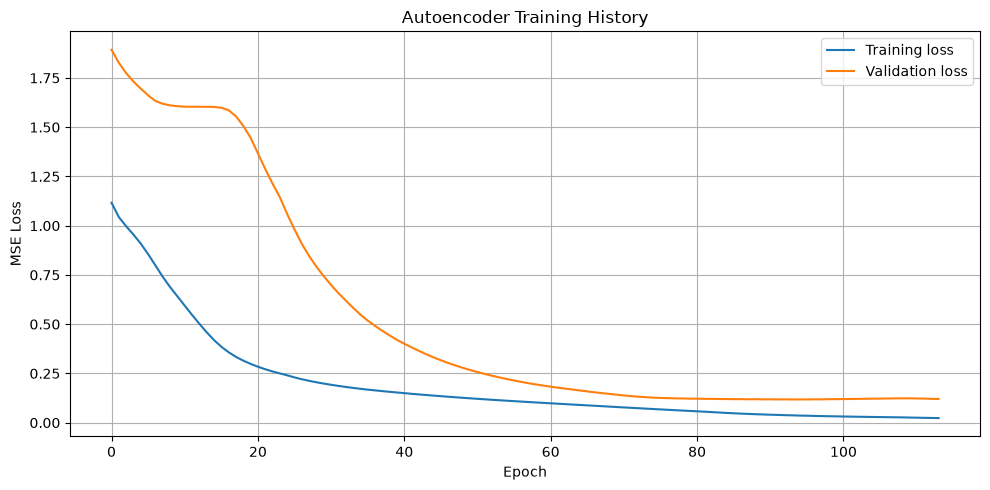


===== RECONSTRUCTION ERROR =====
Validation mean: 0.11778936
Validation std: 0.06634018
Validation min: 0.012457973
Validation max: 0.43217647

Percentiles:
90%: 0.16311207
95%: 0.1935714
97%: 0.4047977
98%: 0.41412345
99%: 0.41829285

===== AUTOENCODER THRESHOLD =====
Threshold: 0.41829285

===== AUTOENCODER RESULT =====
Ground Truth anomalies: 22
Predicted anomalies: 31

Precision: 0.2903225806451613
Recall: 0.4090909090909091
F1-score: 0.33962264150943394

===== CONFUSION MATRIX =====
[[189  22]
 [ 13   9]]

                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal       0.94      0.90      0.92       211
     Anomaly       0.29      0.41      0.34        22

    accuracy                           0.85       233
   macro avg       0.61      0.65      0.63       233
weighted avg       0.87      0.85      0.86       233


===== R

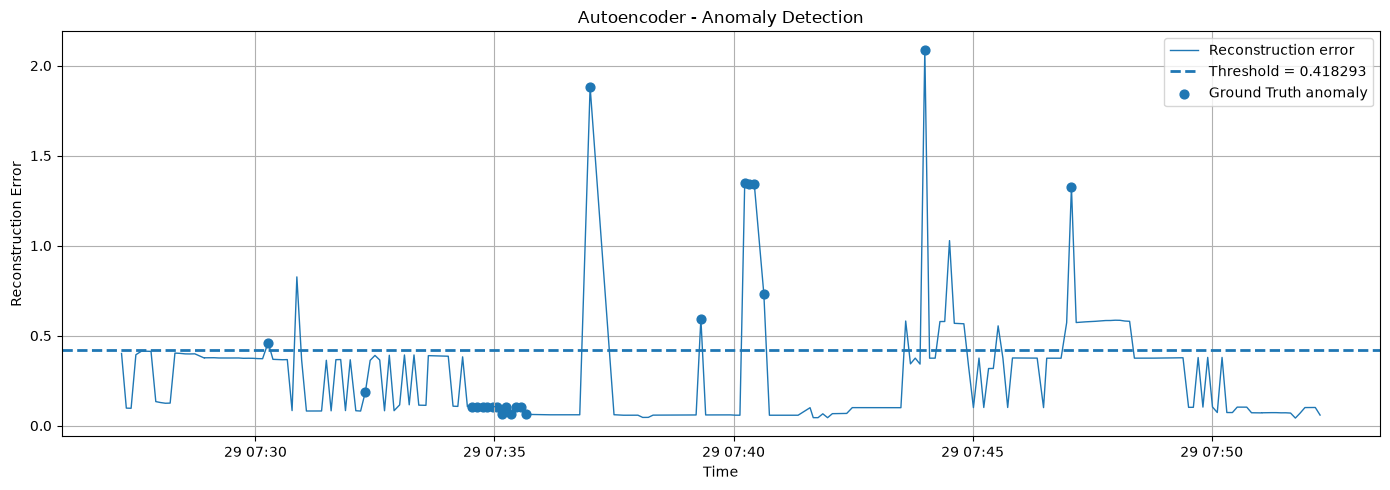

In [3]:
# ============================================================
# BƯỚC 5 - AUTOENCODER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

features = [
    "temperature",
    "ph",
    "turbidity"
]

# ------------------------------------------------------------
# 2. Dữ liệu
# ------------------------------------------------------------

# Training normal
X_train = scaler.transform(
    train_df[features]
).astype("float32")

# Validation normal
X_val = scaler.transform(
    val_df[features]
).astype("float32")

# Test có anomaly injection
X_test = scaler.transform(
    test_injected[features]
).astype("float32")

print("===== DATA =====")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


# ============================================================
# 3. Xây dựng Autoencoder
# ============================================================

input_layer = layers.Input(
    shape=(len(features),)
)

# Encoder
encoded = layers.Dense(
    8,
    activation="relu"
)(input_layer)

latent = layers.Dense(
    3,
    activation="linear",
    name="latent"
)(encoded)

# Decoder
decoded = layers.Dense(
    8,
    activation="relu"
)(latent)

output_layer = layers.Dense(
    len(features),
    activation="linear"
)(decoded)

autoencoder = Model(
    input_layer,
    output_layer
)

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

print("\n===== AUTOENCODER =====")

autoencoder.summary()


# ============================================================
# 4. Training
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(
        X_val,
        X_val
    ),
    epochs=300,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)


# ============================================================
# 5. Training history
# ============================================================

print("\n===== TRAINING RESULT =====")

print(
    "Epochs trained:",
    len(history.history["loss"])
)

print(
    "Best validation loss:",
    min(history.history["val_loss"])
)

# ------------------------------------------------------------
# Plot loss
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "Autoencoder Training History"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 6. Reconstruction
# ============================================================

X_val_reconstructed = autoencoder.predict(
    X_val,
    verbose=0
)

X_test_reconstructed = autoencoder.predict(
    X_test,
    verbose=0
)


# ============================================================
# 7. Reconstruction Error
# ============================================================

# MSE theo từng sample
val_errors = np.mean(
    np.square(
        X_val - X_val_reconstructed
    ),
    axis=1
)

test_errors = np.mean(
    np.square(
        X_test - X_test_reconstructed
    ),
    axis=1
)

print("\n===== RECONSTRUCTION ERROR =====")

print("Validation mean:", val_errors.mean())
print("Validation std:", val_errors.std())
print("Validation min:", val_errors.min())
print("Validation max:", val_errors.max())

print("\nPercentiles:")

for p in [90, 95, 97, 98, 99]:
    print(
        f"{p}%:",
        np.percentile(
            val_errors,
            p
        )
    )


# ============================================================
# 8. Chọn threshold từ Validation
# ============================================================

THRESHOLD_AE = np.percentile(
    val_errors,
    99
)

print("\n===== AUTOENCODER THRESHOLD =====")

print(
    "Threshold:",
    THRESHOLD_AE
)


# ============================================================
# 9. Predict Test
# ============================================================

y_pred_ae = (
    test_errors >= THRESHOLD_AE
).astype(int)


# ============================================================
# 10. Evaluation
# ============================================================

print("\n===== AUTOENCODER RESULT =====")

print(
    "Ground Truth anomalies:",
    y_test.sum()
)

print(
    "Predicted anomalies:",
    y_pred_ae.sum()
)

precision_ae = precision_score(
    y_test,
    y_pred_ae,
    zero_division=0
)

recall_ae = recall_score(
    y_test,
    y_pred_ae,
    zero_division=0
)

f1_ae = f1_score(
    y_test,
    y_pred_ae,
    zero_division=0
)

print("\nPrecision:", precision_ae)
print("Recall:", recall_ae)
print("F1-score:", f1_ae)


# ============================================================
# 11. Confusion Matrix
# ============================================================

cm_ae = confusion_matrix(
    y_test,
    y_pred_ae
)

print("\n===== CONFUSION MATRIX =====")

print(cm_ae)

print("""
                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP
""")


# ============================================================
# 12. Classification Report
# ============================================================

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test,
        y_pred_ae,
        target_names=[
            "Normal",
            "Anomaly"
        ],
        zero_division=0
    )
)


# ============================================================
# 13. Theo dõi từng loại anomaly
# ============================================================

result_ae = test_injected.copy()

result_ae["ground_truth"] = y_test
result_ae["prediction"] = y_pred_ae
result_ae["reconstruction_error"] = test_errors
result_ae["anomaly_type"] = anomaly_type

print("\n===== RESULT BY ANOMALY TYPE =====")

for anomaly in [
    "point_spike",
    "point_drop",
    "sensor_stuck",
    "multivariate_inconsistency"
]:

    subset = result_ae[
        result_ae["anomaly_type"] == anomaly
    ]

    detected = (
        subset["prediction"] == 1
    ).sum()

    total = len(subset)

    print(
        f"{anomaly}: "
        f"{detected}/{total} detected"
    )


# ============================================================
# 14. Những mẫu bị phát hiện
# ============================================================

print("\n===== PREDICTED ANOMALIES =====")

print(
    result_ae[
        result_ae["prediction"] == 1
    ][
        [
            "created_at",
            "temperature",
            "ph",
            "turbidity",
            "ground_truth",
            "prediction",
            "reconstruction_error",
            "anomaly_type"
        ]
    ]
)


# ============================================================
# 15. Vẽ Reconstruction Error
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    test_injected["created_at"],
    test_errors,
    linewidth=1,
    label="Reconstruction error"
)

plt.axhline(
    THRESHOLD_AE,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {THRESHOLD_AE:.6f}"
)

gt_mask = y_test == 1

plt.scatter(
    test_injected.loc[
        gt_mask,
        "created_at"
    ],
    test_errors[gt_mask],
    s=40,
    label="Ground Truth anomaly"
)

plt.xlabel("Time")
plt.ylabel("Reconstruction Error")

plt.title(
    "Autoencoder - Anomaly Detection"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

===== CONFIGURATION =====
Window size: 10
Number of features: 3

===== NORMAL WINDOWS =====
Training windows: (689, 10, 3)
Validation windows: (224, 10, 3)
Test windows: (224, 10, 3)

===== WINDOW GROUND TRUTH =====
Normal windows: 131
Anomaly windows: 93

===== WINDOW AUTOENCODER =====


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 10, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 30)             │           990 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 10, 3)          │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,610 (10.20 KB)

 Trainable params: 2,610 (10.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 1.0042 - val_loss: 1.4960
Epoch 2/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9853 - val_loss: 1.4917
Epoch 3/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9757 - val_loss: 1.4825
Epoch 4/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9554 - val_loss: 1.4673
Epoch 5/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9107 - val_loss: 1.4249
Epoch 6/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8167 - val_loss: 1.3542
Epoch 7/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6626 - val_loss: 1.2655
Epoch 8/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5095 - val_loss: 1.1743
Epoch 9/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4096 - val_loss: 1.1051
Epoch 10/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3616 - val_loss: 0.9660
Epoch 11/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3431 - val_loss: 0.8863
Epoch 12/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.

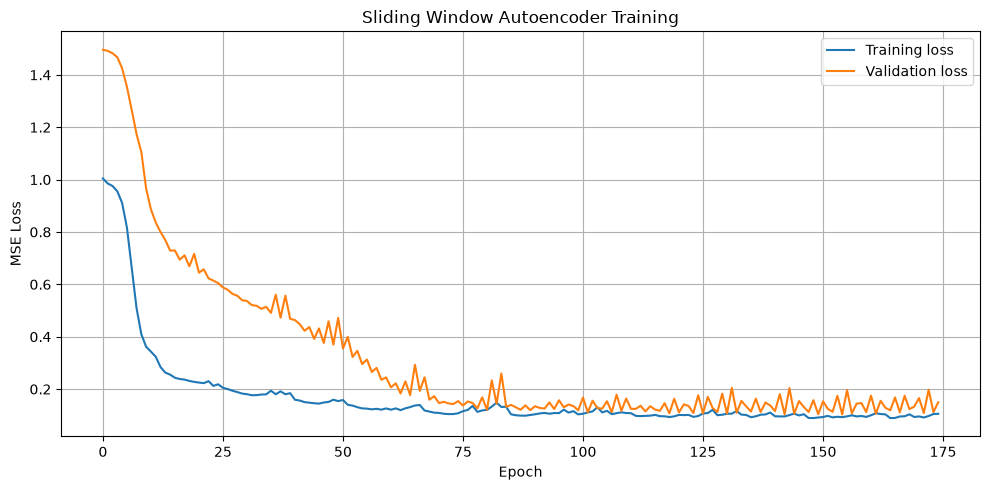


===== WINDOW RECONSTRUCTION ERROR =====
Validation mean: 0.102971636
Validation std: 0.09465568
Validation min: 0.013563005
Validation max: 0.4133756

Percentiles:
90%: 0.23849824
95%: 0.30081627
97%: 0.33133617
98%: 0.3596305
99%: 0.36532035

===== WINDOW THRESHOLD =====
Threshold: 0.36532035

===== WINDOW AUTOENCODER RESULT =====
Ground Truth anomaly windows: 93
Predicted anomaly windows: 93

Precision: 0.7849462365591398
Recall: 0.7849462365591398
F1-score: 0.7849462365591398

===== CONFUSION MATRIX =====
[[111  20]
 [ 20  73]]

                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal       0.85      0.85      0.85       131
     Anomaly       0.78      0.78      0.78        93

    accuracy                           0.82       224
   macro avg       0.82      0.82      0.82       224
weighted avg       0.82      0.82      0.8

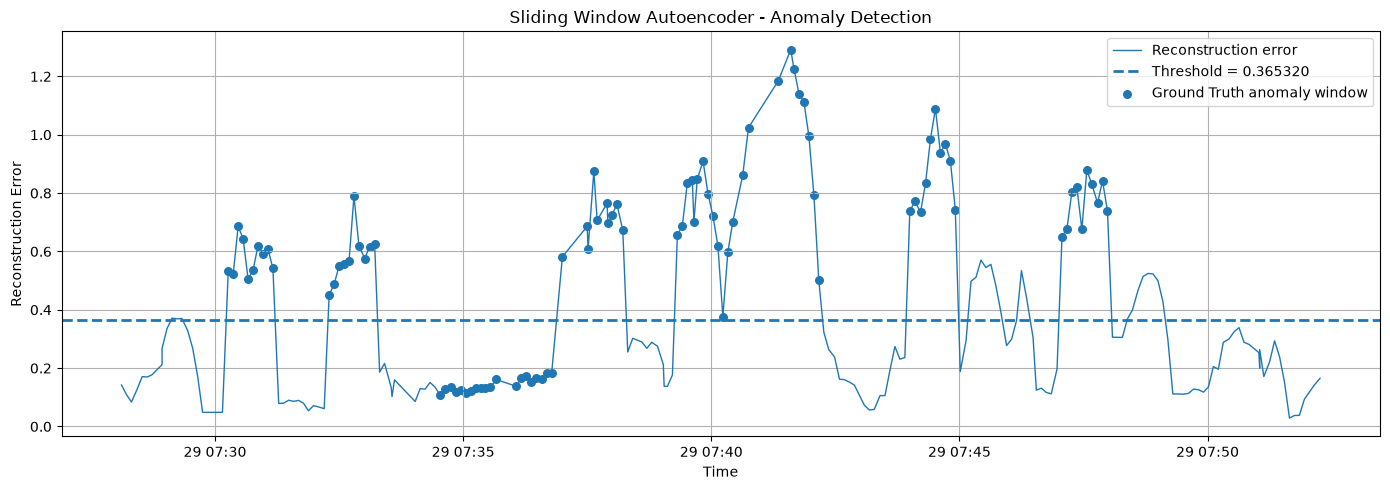

In [4]:
# ============================================================
# BƯỚC 6 - SLIDING WINDOW AUTOENCODER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Model, layers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)
tf.random.set_seed(42)

# ============================================================
# 1. Cấu hình
# ============================================================

WINDOW_SIZE = 10

N_FEATURES = 3

features = [
    "temperature",
    "ph",
    "turbidity"
]

print("===== CONFIGURATION =====")
print("Window size:", WINDOW_SIZE)
print("Number of features:", N_FEATURES)


# ============================================================
# 2. Hàm tạo Sliding Window
# ============================================================

def create_windows(X, window_size):
    """
    Chuyển dữ liệu dạng:
        samples × features

    thành:
        windows × window_size × features
    """

    windows = []

    for i in range(
        len(X) - window_size + 1
    ):
        windows.append(
            X[
                i:i + window_size
            ]
        )

    return np.array(
        windows,
        dtype=np.float32
    )


# ============================================================
# 3. Tạo window cho TRAIN và VALIDATION
# ============================================================

X_train_window = create_windows(
    X_train,
    WINDOW_SIZE
)

X_val_window = create_windows(
    X_val,
    WINDOW_SIZE
)

print("\n===== NORMAL WINDOWS =====")

print(
    "Training windows:",
    X_train_window.shape
)

print(
    "Validation windows:",
    X_val_window.shape
)


# ============================================================
# 4. Tạo TEST WINDOWS
# ============================================================

X_test_window = create_windows(
    X_test,
    WINDOW_SIZE
)

print(
    "Test windows:",
    X_test_window.shape
)


# ============================================================
# 5. Ground Truth cho TEST WINDOW
# ============================================================

# Một window được xem là anomaly nếu
# trong window có ít nhất một anomaly.

y_test_window = np.array([
    int(
        np.any(
            y_test[
                i:i + WINDOW_SIZE
            ] == 1
        )
    )
    for i in range(
        len(y_test) - WINDOW_SIZE + 1
    )
])

print("\n===== WINDOW GROUND TRUTH =====")

print(
    "Normal windows:",
    np.sum(y_test_window == 0)
)

print(
    "Anomaly windows:",
    np.sum(y_test_window == 1)
)


# ============================================================
# 6. Xây dựng Window Autoencoder
# ============================================================

input_layer = layers.Input(
    shape=(
        WINDOW_SIZE,
        N_FEATURES
    )
)

# Flatten window
flatten = layers.Flatten()(
    input_layer
)

# Encoder
encoded = layers.Dense(
    32,
    activation="relu"
)(flatten)

encoded = layers.Dense(
    8,
    activation="relu"
)(encoded)

# Latent representation
latent = layers.Dense(
    4,
    activation="linear",
    name="latent"
)(encoded)

# Decoder
decoded = layers.Dense(
    8,
    activation="relu"
)(latent)

decoded = layers.Dense(
    32,
    activation="relu"
)(decoded)

output_flat = layers.Dense(
    WINDOW_SIZE * N_FEATURES,
    activation="linear"
)(decoded)

# Reshape lại thành window
output_layer = layers.Reshape(
    (
        WINDOW_SIZE,
        N_FEATURES
    )
)(output_flat)

window_autoencoder = Model(
    input_layer,
    output_layer
)

window_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

print("\n===== WINDOW AUTOENCODER =====")

window_autoencoder.summary()


# ============================================================
# 7. Training
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history_window = window_autoencoder.fit(
    X_train_window,
    X_train_window,
    validation_data=(
        X_val_window,
        X_val_window
    ),
    epochs=300,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)


# ============================================================
# 8. Training history
# ============================================================

print("\n===== TRAINING RESULT =====")

print(
    "Epochs trained:",
    len(history_window.history["loss"])
)

print(
    "Best validation loss:",
    min(
        history_window.history["val_loss"]
    )
)


plt.figure(figsize=(10, 5))

plt.plot(
    history_window.history["loss"],
    label="Training loss"
)

plt.plot(
    history_window.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "Sliding Window Autoencoder Training"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 9. Reconstruction
# ============================================================

X_val_reconstructed = (
    window_autoencoder.predict(
        X_val_window,
        verbose=0
    )
)

X_test_reconstructed = (
    window_autoencoder.predict(
        X_test_window,
        verbose=0
    )
)


# ============================================================
# 10. Reconstruction Error
# ============================================================

val_window_errors = np.mean(
    np.square(
        X_val_window -
        X_val_reconstructed
    ),
    axis=(1, 2)
)

test_window_errors = np.mean(
    np.square(
        X_test_window -
        X_test_reconstructed
    ),
    axis=(1, 2)
)

print("\n===== WINDOW RECONSTRUCTION ERROR =====")

print(
    "Validation mean:",
    val_window_errors.mean()
)

print(
    "Validation std:",
    val_window_errors.std()
)

print(
    "Validation min:",
    val_window_errors.min()
)

print(
    "Validation max:",
    val_window_errors.max()
)

print("\nPercentiles:")

for p in [90, 95, 97, 98, 99]:
    print(
        f"{p}%:",
        np.percentile(
            val_window_errors,
            p
        )
    )


# ============================================================
# 11. Threshold từ Validation
# ============================================================

THRESHOLD_WINDOW = np.percentile(
    val_window_errors,
    99
)

print("\n===== WINDOW THRESHOLD =====")

print(
    "Threshold:",
    THRESHOLD_WINDOW
)


# ============================================================
# 12. Prediction
# ============================================================

y_pred_window = (
    test_window_errors >=
    THRESHOLD_WINDOW
).astype(int)


# ============================================================
# 13. Evaluation
# ============================================================

print("\n===== WINDOW AUTOENCODER RESULT =====")

print(
    "Ground Truth anomaly windows:",
    y_test_window.sum()
)

print(
    "Predicted anomaly windows:",
    y_pred_window.sum()
)

precision_window = precision_score(
    y_test_window,
    y_pred_window,
    zero_division=0
)

recall_window = recall_score(
    y_test_window,
    y_pred_window,
    zero_division=0
)

f1_window = f1_score(
    y_test_window,
    y_pred_window,
    zero_division=0
)

print(
    "\nPrecision:",
    precision_window
)

print(
    "Recall:",
    recall_window
)

print(
    "F1-score:",
    f1_window
)


# ============================================================
# 14. Confusion Matrix
# ============================================================

cm_window = confusion_matrix(
    y_test_window,
    y_pred_window
)

print("\n===== CONFUSION MATRIX =====")

print(cm_window)

print("""
                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP
""")


# ============================================================
# 15. Classification Report
# ============================================================

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test_window,
        y_pred_window,
        target_names=[
            "Normal",
            "Anomaly"
        ],
        zero_division=0
    )
)


# ============================================================
# 16. Map window → thời gian
# ============================================================

window_times = test_injected[
    "created_at"
].iloc[
    WINDOW_SIZE - 1:
].reset_index(drop=True)

result_window = pd.DataFrame({
    "created_at": window_times,
    "ground_truth": y_test_window,
    "prediction": y_pred_window,
    "reconstruction_error": test_window_errors
})


# ============================================================
# 17. Kiểm tra anomaly windows
# ============================================================

print(
    "\n===== PREDICTED ANOMALY WINDOWS ====="
)

print(
    result_window[
        result_window["prediction"] == 1
    ].head(50)
)


# ============================================================
# 18. Vẽ Reconstruction Error
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    result_window["created_at"],
    result_window["reconstruction_error"],
    linewidth=1,
    label="Reconstruction error"
)

plt.axhline(
    THRESHOLD_WINDOW,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {THRESHOLD_WINDOW:.6f}"
)

gt_mask = (
    result_window["ground_truth"] == 1
)

plt.scatter(
    result_window.loc[
        gt_mask,
        "created_at"
    ],
    result_window.loc[
        gt_mask,
        "reconstruction_error"
    ],
    s=30,
    label="Ground Truth anomaly window"
)

plt.xlabel("Time")
plt.ylabel("Reconstruction Error")

plt.title(
    "Sliding Window Autoencoder - Anomaly Detection"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

===== LSTM AUTOENCODER CONFIGURATION =====
Window size: 10
Features: 3

===== MODEL SUMMARY =====


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 10, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 16)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 4)              │            68 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 10, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 10, 16)         │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 10, 3)          │            51 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,743 (10.71 KB)

 Trainable params: 2,743 (10.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - loss: 0.8474 - val_loss: 0.9379
Epoch 2/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.6775 - val_loss: 0.7991
Epoch 3/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5499 - val_loss: 0.7557
Epoch 4/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4512 - val_loss: 0.7129
Epoch 5/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3778 - val_loss: 0.6326
Epoch 6/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3349 - val_loss: 0.5720
Epoch 7/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3150 - val_loss: 0.5561
Epoch 8/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3021 - val_loss: 0.5526
Epoch 9/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2888 - val_loss: 0.5439
Epoch 10/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2735 - val_loss: 0.5269
Epoch 11/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2555 - val_loss: 0.5023
Epoch 12/300
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 

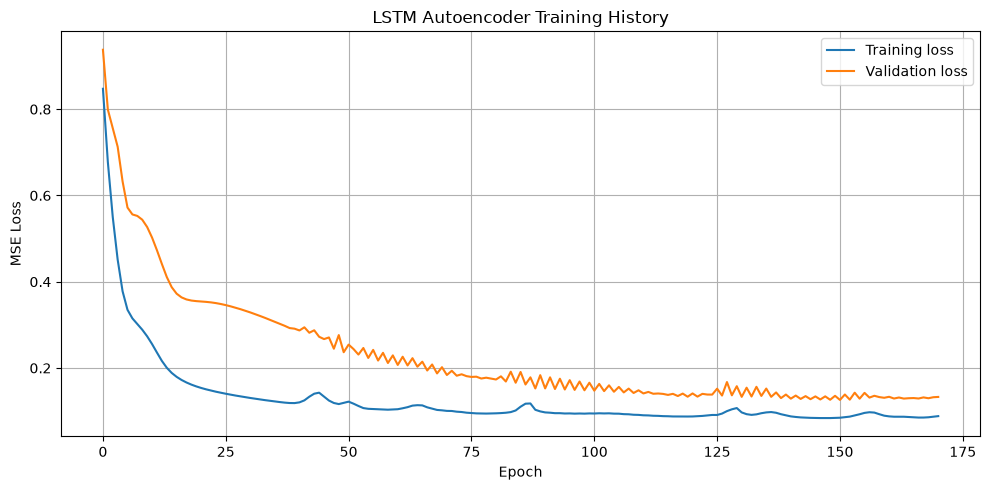


===== LSTM RECONSTRUCTION ERROR =====
Validation mean: 0.12601687
Validation std: 0.12578164
Validation min: 0.017369043
Validation max: 0.5271339

Percentiles:
90%: 0.33040726
95%: 0.39502677
97%: 0.42995656
98%: 0.4386894
99%: 0.47977147

===== LSTM THRESHOLD =====
Threshold: 0.47977147

===== LSTM AUTOENCODER RESULT =====
Ground Truth anomaly windows: 93
Predicted anomaly windows: 180

Precision: 0.5166666666666667
Recall: 1.0
F1-score: 0.6813186813186813

===== CONFUSION MATRIX =====
[[44 87]
 [ 0 93]]

                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal       1.00      0.34      0.50       131
     Anomaly       0.52      1.00      0.68        93

    accuracy                           0.61       224
   macro avg       0.76      0.67      0.59       224
weighted avg       0.80      0.61      0.58       224


===== PREDI

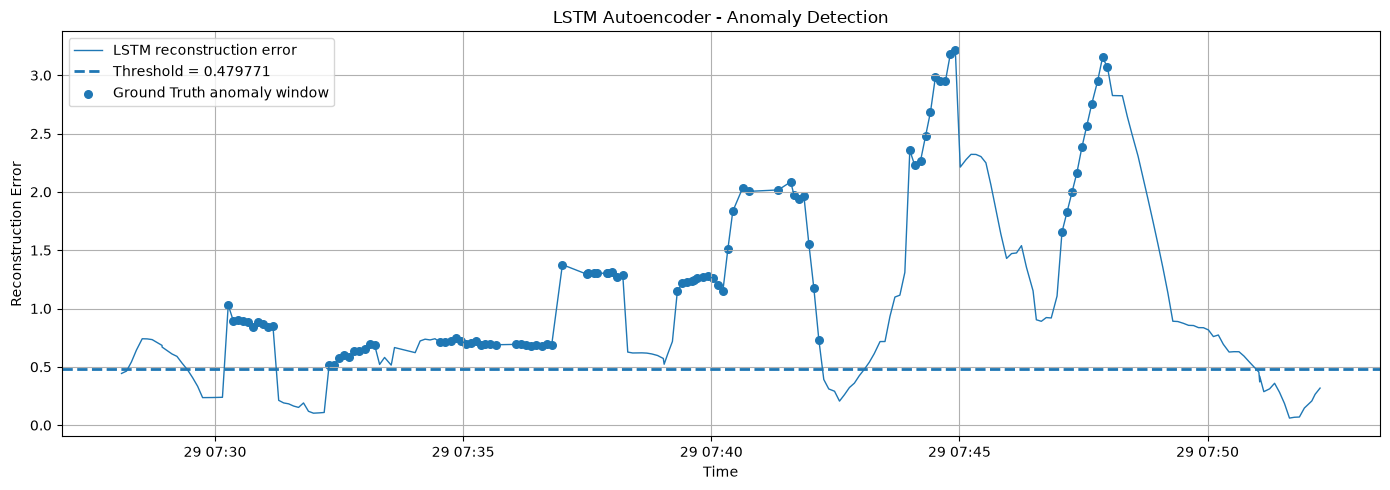

In [5]:
# ============================================================
# BƯỚC 7 - LSTM AUTOENCODER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Model, layers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)
tf.random.set_seed(42)


# ============================================================
# 1. Configuration
# ============================================================

WINDOW_SIZE = X_train_window.shape[1]
N_FEATURES = X_train_window.shape[2]

print("===== LSTM AUTOENCODER CONFIGURATION =====")
print("Window size:", WINDOW_SIZE)
print("Features:", N_FEATURES)


# ============================================================
# 2. LSTM Autoencoder
# ============================================================

input_layer = layers.Input(
    shape=(WINDOW_SIZE, N_FEATURES)
)

# ------------------------------------------------------------
# Encoder
# ------------------------------------------------------------

encoder = layers.LSTM(
    16,
    activation="tanh",
    return_sequences=False
)(input_layer)

latent = layers.Dense(
    4,
    activation="linear",
    name="latent"
)(encoder)


# ------------------------------------------------------------
# Decoder
# ------------------------------------------------------------

repeat = layers.RepeatVector(
    WINDOW_SIZE
)(latent)

decoder = layers.LSTM(
    16,
    activation="tanh",
    return_sequences=True
)(repeat)

output_layer = layers.TimeDistributed(
    layers.Dense(N_FEATURES)
)(decoder)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

lstm_autoencoder = Model(
    input_layer,
    output_layer
)

lstm_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)


print("\n===== MODEL SUMMARY =====")

lstm_autoencoder.summary()


# ============================================================
# 3. Training
# ============================================================

early_stopping_lstm = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history_lstm = lstm_autoencoder.fit(
    X_train_window,
    X_train_window,

    validation_data=(
        X_val_window,
        X_val_window
    ),

    epochs=300,
    batch_size=32,

    shuffle=False,

    callbacks=[
        early_stopping_lstm
    ],

    verbose=1
)


# ============================================================
# 4. Training history
# ============================================================

print("\n===== LSTM TRAINING RESULT =====")

print(
    "Epochs trained:",
    len(history_lstm.history["loss"])
)

print(
    "Best validation loss:",
    min(
        history_lstm.history["val_loss"]
    )
)


plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["loss"],
    label="Training loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "LSTM Autoencoder Training History"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 5. Reconstruction
# ============================================================

X_val_lstm_reconstructed = (
    lstm_autoencoder.predict(
        X_val_window,
        verbose=0
    )
)

X_test_lstm_reconstructed = (
    lstm_autoencoder.predict(
        X_test_window,
        verbose=0
    )
)


# ============================================================
# 6. Reconstruction Error
# ============================================================

val_lstm_errors = np.mean(
    np.square(
        X_val_window -
        X_val_lstm_reconstructed
    ),
    axis=(1, 2)
)

test_lstm_errors = np.mean(
    np.square(
        X_test_window -
        X_test_lstm_reconstructed
    ),
    axis=(1, 2)
)


print("\n===== LSTM RECONSTRUCTION ERROR =====")

print(
    "Validation mean:",
    val_lstm_errors.mean()
)

print(
    "Validation std:",
    val_lstm_errors.std()
)

print(
    "Validation min:",
    val_lstm_errors.min()
)

print(
    "Validation max:",
    val_lstm_errors.max()
)


print("\nPercentiles:")

for p in [90, 95, 97, 98, 99]:
    print(
        f"{p}%:",
        np.percentile(
            val_lstm_errors,
            p
        )
    )


# ============================================================
# 7. Threshold
# ============================================================

THRESHOLD_LSTM = np.percentile(
    val_lstm_errors,
    99
)

print("\n===== LSTM THRESHOLD =====")

print(
    "Threshold:",
    THRESHOLD_LSTM
)


# ============================================================
# 8. Prediction
# ============================================================

y_pred_lstm = (
    test_lstm_errors >=
    THRESHOLD_LSTM
).astype(int)


# ============================================================
# 9. Evaluation
# ============================================================

print("\n===== LSTM AUTOENCODER RESULT =====")

print(
    "Ground Truth anomaly windows:",
    y_test_window.sum()
)

print(
    "Predicted anomaly windows:",
    y_pred_lstm.sum()
)


precision_lstm = precision_score(
    y_test_window,
    y_pred_lstm,
    zero_division=0
)

recall_lstm = recall_score(
    y_test_window,
    y_pred_lstm,
    zero_division=0
)

f1_lstm = f1_score(
    y_test_window,
    y_pred_lstm,
    zero_division=0
)


print(
    "\nPrecision:",
    precision_lstm
)

print(
    "Recall:",
    recall_lstm
)

print(
    "F1-score:",
    f1_lstm
)


# ============================================================
# 10. Confusion Matrix
# ============================================================

cm_lstm = confusion_matrix(
    y_test_window,
    y_pred_lstm
)

print("\n===== CONFUSION MATRIX =====")

print(cm_lstm)

print("""
                Predicted
              Normal  Anomaly
Actual Normal    TN      FP
Actual Anomaly  FN      TP
""")


# ============================================================
# 11. Classification Report
# ============================================================

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test_window,
        y_pred_lstm,
        target_names=[
            "Normal",
            "Anomaly"
        ],
        zero_division=0
    )
)


# ============================================================
# 12. Result DataFrame
# ============================================================

window_times = test_injected[
    "created_at"
].iloc[
    WINDOW_SIZE - 1:
].reset_index(drop=True)

result_lstm = pd.DataFrame({

    "created_at":
        window_times,

    "ground_truth":
        y_test_window,

    "prediction":
        y_pred_lstm,

    "reconstruction_error":
        test_lstm_errors
})


# ============================================================
# 13. Predicted anomalies
# ============================================================

print(
    "\n===== PREDICTED LSTM ANOMALY WINDOWS ====="
)

print(
    result_lstm[
        result_lstm["prediction"] == 1
    ].head(50)
)


# ============================================================
# 14. Plot
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    result_lstm["created_at"],
    result_lstm["reconstruction_error"],
    linewidth=1,
    label="LSTM reconstruction error"
)

plt.axhline(
    THRESHOLD_LSTM,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {THRESHOLD_LSTM:.6f}"
)

gt_mask = (
    result_lstm["ground_truth"] == 1
)

plt.scatter(
    result_lstm.loc[
        gt_mask,
        "created_at"
    ],
    result_lstm.loc[
        gt_mask,
        "reconstruction_error"
    ],
    s=30,
    label="Ground Truth anomaly window"
)

plt.xlabel("Time")

plt.ylabel(
    "Reconstruction Error"
)

plt.title(
    "LSTM Autoencoder - Anomaly Detection"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# THRESHOLD SENSITIVITY
# Sliding Window Autoencoder
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Reconstruction errors
# ------------------------------------------------------------

val_errors = np.asarray(
    val_window_errors
)

test_errors = np.asarray(
    test_window_errors
)

# Ground Truth theo window
y_test = np.asarray(
    y_test_window
)


# ------------------------------------------------------------
# 2. Các ngưỡng cần khảo sát
# ------------------------------------------------------------

percentiles = [
    90,
    92,
    94,
    95,
    96,
    97,
    98,
    99,
    99.5
]


# ------------------------------------------------------------
# 3. Đánh giá từng threshold
# ------------------------------------------------------------

results = []

for p in percentiles:

    # Threshold chỉ lấy từ Validation
    threshold = np.percentile(
        val_errors,
        p
    )

    # Prediction trên Test
    y_pred = (
        test_errors >= threshold
    ).astype(int)

    # Metrics
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    # False Positive / False Negative
    fp = np.sum(
        (y_test == 0) &
        (y_pred == 1)
    )

    fn = np.sum(
        (y_test == 1) &
        (y_pred == 0)
    )

    results.append({
        "Percentile": p,
        "Threshold": threshold,
        "Predicted Anomalies": int(y_pred.sum()),
        "FP": int(fp),
        "FN": int(fn),
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })


# ------------------------------------------------------------
# 4. Bảng kết quả
# ------------------------------------------------------------

threshold_results = pd.DataFrame(
    results
)

print(
    "===== THRESHOLD SENSITIVITY ====="
)

display(
    threshold_results.style.format({
        "Threshold": "{:.6f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    })
)


# ------------------------------------------------------------
# 5. Threshold có F1 cao nhất
# ------------------------------------------------------------

best_idx = (
    threshold_results["F1"]
    .idxmax()
)

best_threshold_row = (
    threshold_results.loc[
        best_idx
    ]
)

print(
    "\n===== BEST THRESHOLD BY F1 ====="
)

print(
    "Percentile:",
    best_threshold_row["Percentile"]
)

print(
    "Threshold:",
    best_threshold_row["Threshold"]
)

print(
    "Precision:",
    best_threshold_row["Precision"]
)

print(
    "Recall:",
    best_threshold_row["Recall"]
)

print(
    "F1:",
    best_threshold_row["F1"]
)

print(
    "FP:",
    best_threshold_row["FP"]
)

print(
    "FN:",
    best_threshold_row["FN"]
)

===== THRESHOLD SENSITIVITY =====


,Percentile,Threshold,Predicted Anomalies,FP,FN,Precision,Recall,F1
0,90.000000,0.238498,125,52,20,0.584,0.785,0.670
1,92.000000,0.249318,124,51,20,0.589,0.785,0.673
2,94.000000,0.284416,113,40,20,0.646,0.785,0.709
3,95.000000,0.300816,104,31,20,0.702,0.785,0.741
4,96.000000,0.320015,99,26,20,0.737,0.785,0.760
5,97.000000,0.331336,96,23,20,0.760,0.785,0.772
6,98.000000,0.359630,94,21,20,0.777,0.785,0.781
7,99.000000,0.365320,93,20,20,0.785,0.785,0.785
8,99.500000,0.391051,88,16,21,0.818,0.774,0.796



===== BEST THRESHOLD BY F1 =====
Percentile: 99.5
Threshold: 0.39105090498924255
Precision: 0.8181818181818182
Recall: 0.7741935483870968
F1: 0.7955801104972375
FP: 16.0
FN: 21.0


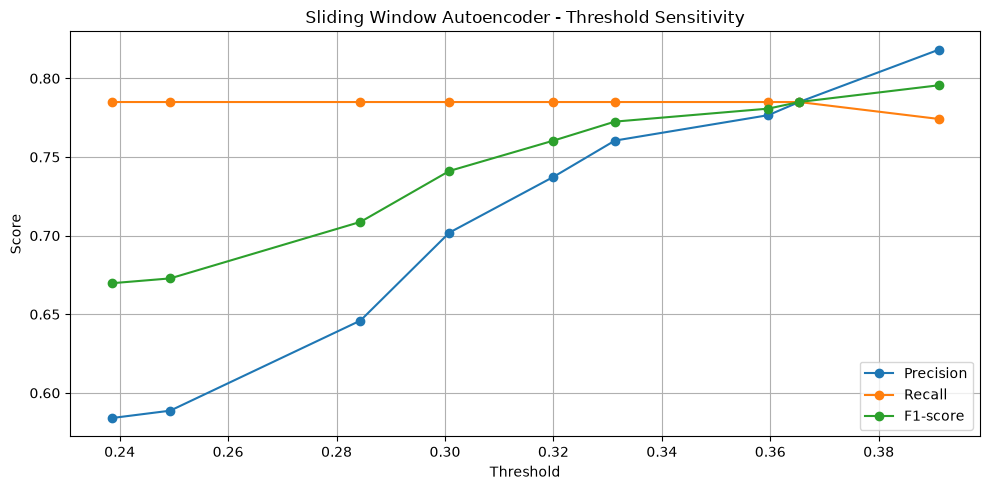

In [8]:
# ============================================================
# THRESHOLD SENSITIVITY PLOT
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Threshold")
plt.ylabel("Score")

plt.title(
    "Sliding Window Autoencoder - Threshold Sensitivity"
)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# MODEL COMPARISON
# So sánh các mô hình Anomaly Detection
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

model_results = pd.DataFrame({

    "Model": [
        "Statistical Baseline",
        "Isolation Forest",
        "Point Autoencoder",
        "Sliding Window Autoencoder",
        "LSTM-Autoencoder"
    ],

    "Precision": [
        0.126506,
        0.050505,
        0.290323,
        0.784946,
        0.516667
    ],

    "Recall": [
        0.954545,
        0.227273,
        0.409091,
        0.784946,
        1.000000
    ],

    "F1": [
        0.223404,
        0.082645,
        0.339623,
        0.784946,
        0.681319
    ],

    "FP": [
        145,
        94,
        22,
        20,
        87
    ],

    "FN": [
        1,
        17,
        13,
        20,
        0
    ],

    "Parameters": [
        "-",
        "-",
        118,
        2610,
        2743
    ]
})


print("===== MODEL COMPARISON =====")

display(
    model_results.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    })
)


# ============================================================
# Best model theo F1
# ============================================================

best_model = model_results.loc[
    model_results["F1"].idxmax()
]

print("\n===== BEST MODEL =====")

print(
    "Model:",
    best_model["Model"]
)

print(
    "Precision:",
    best_model["Precision"]
)

print(
    "Recall:",
    best_model["Recall"]
)

print(
    "F1:",
    best_model["F1"]
)

print(
    "False Positive:",
    best_model["FP"]
)

print(
    "False Negative:",
    best_model["FN"]
)

===== MODEL COMPARISON =====


,Model,Precision,Recall,F1,FP,FN,Parameters
0,Statistical Baseline,0.127,0.955,0.223,145,1,-
1,Isolation Forest,0.051,0.227,0.083,94,17,-
2,Point Autoencoder,0.290,0.409,0.340,22,13,118
3,Sliding Window Autoencoder,0.785,0.785,0.785,20,20,2610
4,LSTM-Autoencoder,0.517,1.000,0.681,87,0,2743



===== BEST MODEL =====
Model: Sliding Window Autoencoder
Precision: 0.784946
Recall: 0.784946
F1: 0.784946
False Positive: 20
False Negative: 20


In [10]:
# ============================================================
# SAVE FINAL MODEL
# ============================================================

import os
import json
import joblib

os.makedirs(
    "../models",
    exist_ok=True
)


# ------------------------------------------------------------
# 1. Save Sliding Window Autoencoder
# ------------------------------------------------------------

MODEL_PATH = (
    "../models/"
    "sliding_window_autoencoder.keras"
)

window_autoencoder.save(
    MODEL_PATH
)


# ------------------------------------------------------------
# 2. Save scaler
# ------------------------------------------------------------

SCALER_PATH = (
    "../models/"
    "scaler.pkl"
)

joblib.dump(
    scaler,
    SCALER_PATH
)


# ------------------------------------------------------------
# 3. Save configuration
# ------------------------------------------------------------

CONFIG_PATH = (
    "../models/"
    "model_config.json"
)

config = {

    "model": "Sliding Window Autoencoder",

    "window_size": 10,

    "features": [
        "temperature",
        "ph",
        "turbidity"
    ],

    "threshold": 0.36532035,

    "threshold_method":
        "99th percentile of validation reconstruction error",

    "latent_dimension": 4,

    "parameters": 2610,

    "framework": "TensorFlow/Keras"

}


with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        config,
        f,
        indent=4
    )


print("===== MODEL SAVED =====")

print(
    "Model:",
    MODEL_PATH
)

print(
    "Scaler:",
    SCALER_PATH
)

print(
    "Config:",
    CONFIG_PATH
)

===== MODEL SAVED =====
Model: ../models/sliding_window_autoencoder.keras
Scaler: ../models/scaler.pkl
Config: ../models/model_config.json


In [11]:
# ============================================================
# BƯỚC 8.1 - LOAD FINAL MODEL
# ============================================================

import os
import json
import joblib
import numpy as np
import tensorflow as tf

MODEL_PATH = "../models/sliding_window_autoencoder.keras"
SCALER_PATH = "../models/scaler.pkl"
CONFIG_PATH = "../models/model_config.json"

print("===== CHECK FILES =====")

print("Model exists:", os.path.exists(MODEL_PATH))
print("Scaler exists:", os.path.exists(SCALER_PATH))
print("Config exists:", os.path.exists(CONFIG_PATH))

# Load model
loaded_model = tf.keras.models.load_model(MODEL_PATH)

# Load scaler
loaded_scaler = joblib.load(SCALER_PATH)

# Load configuration
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    loaded_config = json.load(f)

print("\n===== MODEL LOADED =====")

print("Model:", loaded_config["model"])
print("Window size:", loaded_config["window_size"])
print("Features:", loaded_config["features"])
print("Threshold:", loaded_config["threshold"])
print("Latent dimension:", loaded_config["latent_dimension"])
print("Parameters:", loaded_config["parameters"])
print("Framework:", loaded_config["framework"])

===== CHECK FILES =====
Model exists: True
Scaler exists: True
Config exists: True

===== MODEL LOADED =====
Model: Sliding Window Autoencoder
Window size: 10
Features: ['temperature', 'ph', 'turbidity']
Threshold: 0.36532035
Latent dimension: 4
Parameters: 2610
Framework: TensorFlow/Keras


In [18]:
# ============================================================
# HÀM REAL-TIME INFERENCE (SUY LUẬN THỜI GIAN THỰC)
# ============================================================

import numpy as np

FEATURES = ["temperature", "ph", "turbidity"]


def predict_window(window_data):
    """
    Nhận 10 mẫu dữ liệu cảm biến và phát hiện bất thường.

    Input:
        window_data: numpy array có shape (10, 3)

    Output:
        error: Reconstruction Error (sai số tái tạo)
        prediction: True = bất thường, False = bình thường
        status: "ANOMALY" hoặc "NORMAL"
    """

    # Kiểm tra kích thước cửa sổ
    window_data = np.asarray(window_data, dtype=float)

    if window_data.shape != (10, 3):
        raise ValueError(
            f"Window phải có shape (10, 3), "
            f"nhưng nhận được {window_data.shape}"
        )

    # 1. Chuẩn hóa dữ liệu bằng scaler đã lưu
    scaled_data = loaded_scaler.transform(
    pd.DataFrame(window_data, columns=FEATURES)
)

    # 2. Thêm batch dimension
    # (10, 3) -> (1, 10, 3)
    model_input = np.expand_dims(scaled_data, axis=0)

    # 3. Cho dữ liệu qua Autoencoder
    reconstructed = loaded_model.predict(
        model_input,
        verbose=0
    )

    # 4. Tính Reconstruction Error
    error = np.mean(
        np.square(model_input - reconstructed)
    )

    # 5. So sánh với threshold đã chọn
    prediction = error >= loaded_config["threshold"]

    # 6. Chuyển sang trạng thái dễ đọc
    status = "ANOMALY" if prediction else "NORMAL"

    return error, prediction, status

In [19]:
# ============================================================
# TEST WINDOW
# ============================================================

normal_window = (
    test_injected[FEATURES]
    .iloc[0:10]
    .values
)

error, prediction, status = predict_window(
    normal_window
)

print("===== TEST WINDOW =====")
print("Reconstruction error:", error)
print("Threshold:", loaded_config["threshold"])
print("Prediction:", prediction)
print("Status:", status)

===== TEST WINDOW =====
Reconstruction error: 0.1421188469939088
Threshold: 0.36532035
Prediction: False
Status: NORMAL


In [20]:
# ============================================================
# TEST ANOMALY WINDOW
# ============================================================

anomaly_window = (
    test_injected[FEATURES]
    .iloc[25:35]
    .values
)

error, prediction, status = predict_window(
    anomaly_window
)

print("===== ANOMALY WINDOW TEST =====")
print("Reconstruction error:", error)
print("Threshold:", loaded_config["threshold"])
print("Prediction:", prediction)
print("Status:", status)

===== ANOMALY WINDOW TEST =====
Reconstruction error: 0.5054724617670324
Threshold: 0.36532035
Prediction: True
Status: ANOMALY


In [21]:
# ============================================================
# STREAMING INFERENCE
# MÔ PHỎNG DỮ LIỆU CẢM BIẾN ĐẾN LIÊN TỤC
# ============================================================

from collections import deque

WINDOW_SIZE = loaded_config["window_size"]

buffer = deque(maxlen=WINDOW_SIZE)

results = []

for i, row in test_injected.iterrows():

    # Lấy 3 giá trị cảm biến
    sample = row[FEATURES].values.astype(float)

    # Thêm mẫu mới vào buffer
    buffer.append(sample)

    # Chưa đủ 10 mẫu thì chưa inference
    if len(buffer) < WINDOW_SIZE:
        continue

    # Chuyển buffer thành cửa sổ
    window = np.array(buffer)

    # Inference
    error, prediction, status = predict_window(window)

    # Lưu kết quả
    results.append({
        "index": i,
        "created_at": row["created_at"],
        "reconstruction_error": error,
        "prediction": prediction,
        "status": status
    })


# Chuyển kết quả thành DataFrame
stream_results = pd.DataFrame(results)

print("===== STREAMING INFERENCE =====")
print("Total input samples:", len(test_injected))
print("Total windows:", len(stream_results))

print("\nFirst 10 results:")
display(stream_results.head(10))

===== STREAMING INFERENCE =====
Total input samples: 233
Total windows: 224

First 10 results:


,index,created_at,reconstruction_error,prediction,status
0,9,2026-07-29 07:28:07,0.142119,False,NORMAL
1,10,2026-07-29 07:28:13,0.108976,False,NORMAL
2,11,2026-07-29 07:28:19,0.083660,False,NORMAL
3,12,2026-07-29 07:28:25,0.122254,False,NORMAL
4,13,2026-07-29 07:28:32,0.170837,False,NORMAL
5,14,2026-07-29 07:28:38,0.169531,False,NORMAL
6,15,2026-07-29 07:28:44,0.177447,False,NORMAL
7,16,2026-07-29 07:28:56,0.212160,False,NORMAL
8,17,2026-07-29 07:28:56,0.267312,False,NORMAL
9,18,2026-07-29 07:29:02,0.335705,False,NORMAL


In [22]:
# ============================================================
# CHECK ANOMALY DETECTION IN STREAMING
# ============================================================

anomaly_results = stream_results[
    stream_results["prediction"] == True
].copy()

print("===== STREAMING ANOMALY RESULTS =====")

print("Total anomaly windows:", len(anomaly_results))

display(
    anomaly_results[
        [
            "index",
            "created_at",
            "reconstruction_error",
            "status"
        ]
    ].head(20)
)

===== STREAMING ANOMALY RESULTS =====
Total anomaly windows: 93


,index,created_at,reconstruction_error,status
10,19,2026-07-29 07:29:08,0.371361,ANOMALY
11,20,2026-07-29 07:29:14,0.368957,ANOMALY
12,21,2026-07-29 07:29:20,0.370058,ANOMALY
21,30,2026-07-29 07:30:16,0.532253,ANOMALY
22,31,2026-07-29 07:30:22,0.522699,ANOMALY
23,32,2026-07-29 07:30:28,0.685926,ANOMALY
24,33,2026-07-29 07:30:34,0.643272,ANOMALY
25,34,2026-07-29 07:30:40,0.505472,ANOMALY
26,35,2026-07-29 07:30:46,0.535697,ANOMALY
27,36,2026-07-29 07:30:52,0.620080,ANOMALY


In [23]:
# ============================================================
# RECONSTRUCTION ERROR STATISTICS
# ============================================================

print("===== ERROR STATISTICS =====")

print(
    stream_results["reconstruction_error"].describe()
)

print("\nThreshold:")
print(loaded_config["threshold"])

===== ERROR STATISTICS =====
count    224.000000
mean       0.384901
std        0.294110
min        0.028756
25%        0.135382
50%        0.288393
75%        0.607743
max        1.291354
Name: reconstruction_error, dtype: float64

Threshold:
0.36532035


In [24]:
# ============================================================
# TÌM CỬA SỔ ĐẦU TIÊN PHÁT HIỆN BẤT THƯỜNG
# ============================================================

first_anomaly = stream_results[
    stream_results["prediction"] == True
].iloc[0]

print("===== FIRST ANOMALY DETECTION =====")

print("Index:", first_anomaly["index"])
print("Thời gian:", first_anomaly["created_at"])
print(
    "Reconstruction Error (sai số tái tạo):",
    first_anomaly["reconstruction_error"]
)
print(
    "Threshold (ngưỡng):",
    loaded_config["threshold"]
)
print("Status (trạng thái):", first_anomaly["status"])

===== FIRST ANOMALY DETECTION =====
Index: 19
Thời gian: 2026-07-29 07:29:08
Reconstruction Error (sai số tái tạo): 0.37136148227497195
Threshold (ngưỡng): 0.36532035
Status (trạng thái): ANOMALY


In [26]:
# ============================================================
# KIỂM TRA GROUND TRUTH (NHÃN THỰC TẾ)
# ============================================================

print("===== GROUND TRUTH (NHÃN THỰC TẾ) =====")

print("Số mẫu test:", len(test_injected))
print("Số nhãn:", len(y_test))

print("\nCác vị trí có anomaly:")
print(np.where(y_test == 1)[0])

===== GROUND TRUTH (NHÃN THỰC TẾ) =====
Số mẫu test: 233
Số nhãn: 224

Các vị trí có anomaly:
[ 21  22  23  24  25  26  27  28  29  30  41  42  43  44  45  46  47  48
  49  50  61  62  63  64  65  66  67  68  69  70  71  72  73  74  75  76
  77  78  79  80  81  82  83  84  85  86  87  88  89  90 101 102 103 104
 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122
 123 141 142 143 144 145 146 147 148 149 150 171 172 173 174 175 176 177
 178 179 180]


In [27]:
# ============================================================
# KIỂM TRA ANOMALY ĐẦU TIÊN
# ============================================================

anomaly_indices = np.where(y_test == 1)[0]

print("===== ANOMALY ĐẦU TIÊN =====")

for idx in anomaly_indices[:10]:
    print(
        "Index:",
        idx,
        "| Thời gian:",
        test_injected.iloc[idx]["created_at"]
    )

===== ANOMALY ĐẦU TIÊN =====
Index: 21 | Thời gian: 2026-07-29 07:29:20
Index: 22 | Thời gian: 2026-07-29 07:29:27
Index: 23 | Thời gian: 2026-07-29 07:29:33
Index: 24 | Thời gian: 2026-07-29 07:29:39
Index: 25 | Thời gian: 2026-07-29 07:29:45
Index: 26 | Thời gian: 2026-07-29 07:29:51
Index: 27 | Thời gian: 2026-07-29 07:29:57
Index: 28 | Thời gian: 2026-07-29 07:30:03
Index: 29 | Thời gian: 2026-07-29 07:30:09
Index: 30 | Thời gian: 2026-07-29 07:30:16


In [28]:
# ============================================================
# KIỂM TRA CẤU TRÚC NHÃN TEST
# ============================================================

print("===== KIỂM TRA Y_TEST =====")

print("test_injected:", len(test_injected))
print("y_test:", len(y_test))

print("\n10 nhãn đầu tiên:")
print(y_test[:30])

print("\nCác vị trí anomaly trong y_test:")
print(np.where(y_test == 1)[0])

===== KIỂM TRA Y_TEST =====
test_injected: 233
y_test: 224

10 nhãn đầu tiên:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1]

Các vị trí anomaly trong y_test:
[ 21  22  23  24  25  26  27  28  29  30  41  42  43  44  45  46  47  48
  49  50  61  62  63  64  65  66  67  68  69  70  71  72  73  74  75  76
  77  78  79  80  81  82  83  84  85  86  87  88  89  90 101 102 103 104
 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122
 123 141 142 143 144 145 146 147 148 149 150 171 172 173 174 175 176 177
 178 179 180]


In [29]:
# ============================================================
# ĐỐI CHIẾU STREAMING VÀ Y_TEST
# ============================================================

print("===== ĐỐI CHIẾU =====")

for i in range(15, 35):

    stream_row = stream_results[
        stream_results["index"] == i
    ]

    if len(stream_row) > 0:
        status = stream_row.iloc[0]["status"]
        error = stream_row.iloc[0]["reconstruction_error"]
    else:
        status = "N/A"
        error = np.nan

    # y_test là nhãn cửa sổ nên index tương ứng bắt đầu từ 0
    y_value = y_test[i] if i < len(y_test) else "N/A"

    print(
        f"Index {i:3d} | "
        f"Error {error:.6f} | "
        f"Model: {status:7s} | "
        f"Ground Truth: {y_value}"
    )

===== ĐỐI CHIẾU =====
Index  15 | Error 0.177447 | Model: NORMAL  | Ground Truth: 0
Index  16 | Error 0.212160 | Model: NORMAL  | Ground Truth: 0
Index  17 | Error 0.267312 | Model: NORMAL  | Ground Truth: 0
Index  18 | Error 0.335705 | Model: NORMAL  | Ground Truth: 0
Index  19 | Error 0.371361 | Model: ANOMALY | Ground Truth: 0
Index  20 | Error 0.368957 | Model: ANOMALY | Ground Truth: 0
Index  21 | Error 0.370058 | Model: ANOMALY | Ground Truth: 1
Index  22 | Error 0.328359 | Model: NORMAL  | Ground Truth: 1
Index  23 | Error 0.268439 | Model: NORMAL  | Ground Truth: 1
Index  24 | Error 0.172444 | Model: NORMAL  | Ground Truth: 1
Index  25 | Error 0.048444 | Model: NORMAL  | Ground Truth: 1
Index  26 | Error 0.048326 | Model: NORMAL  | Ground Truth: 1
Index  27 | Error 0.048508 | Model: NORMAL  | Ground Truth: 1
Index  28 | Error 0.048457 | Model: NORMAL  | Ground Truth: 1
Index  29 | Error 0.048351 | Model: NORMAL  | Ground Truth: 1
Index  30 | Error 0.532253 | Model: ANOMALY | Gr

In [30]:
# ============================================================
# DETECTION LATENCY (ĐỘ TRỄ PHÁT HIỆN)
# ============================================================

# Các vùng anomaly thực tế trong y_test
anomaly_ranges = [
    (21, 30),
    (41, 50),
    (61, 90),
    (101, 123),
    (141, 150),
    (171, 180)
]

latency_results = []

for start_idx, end_idx in anomaly_ranges:

    # Lấy các kết quả streaming trong vùng anomaly
    region = stream_results[
        (stream_results["index"] >= start_idx) &
        (stream_results["index"] <= end_idx)
    ].copy()

    # Tìm cửa sổ đầu tiên model phát hiện ANOMALY
    detected = region[
        region["prediction"] == True
    ]

    if len(detected) > 0:

        first_detection = detected.iloc[0]

        # Thời gian anomaly bắt đầu
        anomaly_time = test_injected.iloc[start_idx]["created_at"]

        # Thời gian model phát hiện
        detection_time = first_detection["created_at"]

        # Detection Latency (độ trễ phát hiện)
        latency = (
            detection_time - anomaly_time
        ).total_seconds()

        latency_results.append({
            "anomaly_start_index": start_idx,
            "anomaly_end_index": end_idx,
            "anomaly_time": anomaly_time,
            "detection_index": first_detection["index"],
            "detection_time": detection_time,
            "latency_seconds": latency,
            "status": "DETECTED"
        })

    else:

        latency_results.append({
            "anomaly_start_index": start_idx,
            "anomaly_end_index": end_idx,
            "anomaly_time": test_injected.iloc[start_idx]["created_at"],
            "detection_index": None,
            "detection_time": None,
            "latency_seconds": None,
            "status": "NOT DETECTED"
        })


latency_df = pd.DataFrame(latency_results)

print("===== DETECTION LATENCY =====")

display(latency_df)

===== DETECTION LATENCY =====


,anomaly_start_index,anomaly_end_index,anomaly_time,detection_index,detection_time,latency_seconds,status
0,21,30,2026-07-29 07:29:20,21,2026-07-29 07:29:20,0.0,DETECTED
1,41,50,2026-07-29 07:31:23,50,2026-07-29 07:32:18,55.0,DETECTED
2,61,90,2026-07-29 07:33:25,90,2026-07-29 07:37:00,215.0,DETECTED
3,101,123,2026-07-29 07:38:25,110,2026-07-29 07:39:19,54.0,DETECTED
4,141,150,2026-07-29 07:43:05,150,2026-07-29 07:44:00,55.0,DETECTED
5,171,180,2026-07-29 07:46:09,172,2026-07-29 07:46:15,6.0,DETECTED


In [31]:
# ============================================================
# LATENCY SUMMARY (TỔNG HỢP ĐỘ TRỄ)
# ============================================================

detected_latencies = latency_df[
    latency_df["latency_seconds"].notna()
]["latency_seconds"]

print("===== LATENCY SUMMARY =====")

print(
    "Số vùng anomaly:",
    len(anomaly_ranges)
)

print(
    "Số vùng phát hiện được:",
    len(detected_latencies)
)

print(
    "Detection Rate (tỷ lệ phát hiện):",
    f"{len(detected_latencies) / len(anomaly_ranges) * 100:.2f}%"
)

if len(detected_latencies) > 0:

    print(
        "Latency trung bình:",
        f"{detected_latencies.mean():.2f} giây"
    )

    print(
        "Latency nhỏ nhất:",
        f"{detected_latencies.min():.2f} giây"
    )

    print(
        "Latency lớn nhất:",
        f"{detected_latencies.max():.2f} giây"
    )

===== LATENCY SUMMARY =====
Số vùng anomaly: 6
Số vùng phát hiện được: 6
Detection Rate (tỷ lệ phát hiện): 100.00%
Latency trung bình: 64.17 giây
Latency nhỏ nhất: 0.00 giây
Latency lớn nhất: 215.00 giây


In [32]:
# ============================================================
# ĐO THỜI GIAN SUY LUẬN
# ============================================================

import time
import numpy as np

inference_times = []

for i in range(len(stream_results)):

    window = test_injected[
        FEATURES
    ].iloc[i:i+10].values

    start_time = time.perf_counter()

    error, prediction, status = predict_window(window)

    end_time = time.perf_counter()

    inference_times.append(
        (end_time - start_time) * 1000
    )


inference_times = np.array(inference_times)

print("===== INFERENCE PERFORMANCE =====")

print(
    "Số cửa sổ:",
    len(inference_times)
)

print(
    "Thời gian trung bình:",
    f"{inference_times.mean():.3f} ms"
)

print(
    "Thời gian nhỏ nhất:",
    f"{inference_times.min():.3f} ms"
)

print(
    "Thời gian lớn nhất:",
    f"{inference_times.max():.3f} ms"
)

print(
    "Median (trung vị):",
    f"{np.median(inference_times):.3f} ms"
)

===== INFERENCE PERFORMANCE =====
Số cửa sổ: 224
Thời gian trung bình: 100.617 ms
Thời gian nhỏ nhất: 58.865 ms
Thời gian lớn nhất: 868.006 ms
Median (trung vị): 92.657 ms


In [33]:
# ============================================================
# MODEL SIZE
# KIỂM TRA KÍCH THƯỚC MÔ HÌNH
# ============================================================

import os

model_size_bytes = os.path.getsize(MODEL_PATH)
scaler_size_bytes = os.path.getsize(SCALER_PATH)
config_size_bytes = os.path.getsize(CONFIG_PATH)

print("===== MODEL SIZE =====")

print(
    "Model size (kích thước mô hình):",
    f"{model_size_bytes / 1024:.2f} KB"
)

print(
    "Scaler size (kích thước bộ chuẩn hóa):",
    f"{scaler_size_bytes / 1024:.2f} KB"
)

print(
    "Config size (kích thước cấu hình):",
    f"{config_size_bytes / 1024:.2f} KB"
)

print(
    "Parameters (số tham số):",
    loaded_model.count_params()
)

===== MODEL SIZE =====
Model size (kích thước mô hình): 78.26 KB
Scaler size (kích thước bộ chuẩn hóa): 0.89 KB
Config size (kích thước cấu hình): 0.35 KB
Parameters (số tham số): 2610


In [35]:
# ============================================================
# INFERENCE PIPELINE (QUY TRÌNH SUY LUẬN)
# ============================================================

from collections import deque
import numpy as np
import pandas as pd

FEATURES = ["temperature", "ph", "turbidity"]

WINDOW_SIZE = loaded_config["window_size"]
THRESHOLD = loaded_config["threshold"]

# Buffer (bộ đệm) lưu 10 mẫu gần nhất
buffer = deque(maxlen=WINDOW_SIZE)

pipeline_results = []

for i, row in test_injected.iterrows():

    # Lấy dữ liệu cảm biến
    sample = row[FEATURES].values.astype(float)

    # Thêm mẫu vào buffer
    buffer.append(sample)

    # Chưa đủ 10 mẫu thì chưa inference
    if len(buffer) < WINDOW_SIZE:
        continue

    # Tạo Sliding Window (cửa sổ trượt)
    window = np.array(buffer)

    # Inference (suy luận)
    error, prediction, status = predict_window(window)

    # Lưu kết quả
    pipeline_results.append({
        "sample_index": i,
        "created_at": row["created_at"],
        "reconstruction_error": error,
        "threshold": THRESHOLD,
        "status": status
    })

# Tạo DataFrame (bảng dữ liệu)
pipeline_df = pd.DataFrame(pipeline_results)

print("===== INFERENCE PIPELINE =====")

print(
    "Input samples (số mẫu đầu vào):",
    len(test_injected)
)

print(
    "Windows processed (số cửa sổ đã xử lý):",
    len(pipeline_df)
)

print(
    "Window size (kích thước cửa sổ):",
    WINDOW_SIZE
)

print(
    "Threshold (ngưỡng):",
    THRESHOLD
)

print("\nFirst 10 results (10 kết quả đầu tiên):")

display(pipeline_df.head(10))

===== INFERENCE PIPELINE =====
Input samples (số mẫu đầu vào): 233
Windows processed (số cửa sổ đã xử lý): 224
Window size (kích thước cửa sổ): 10
Threshold (ngưỡng): 0.36532035

First 10 results (10 kết quả đầu tiên):


,sample_index,created_at,reconstruction_error,threshold,status
0,9,2026-07-29 07:28:07,0.142119,0.36532,NORMAL
1,10,2026-07-29 07:28:13,0.108976,0.36532,NORMAL
2,11,2026-07-29 07:28:19,0.083660,0.36532,NORMAL
3,12,2026-07-29 07:28:25,0.122254,0.36532,NORMAL
4,13,2026-07-29 07:28:32,0.170837,0.36532,NORMAL
5,14,2026-07-29 07:28:38,0.169531,0.36532,NORMAL
6,15,2026-07-29 07:28:44,0.177447,0.36532,NORMAL
7,16,2026-07-29 07:28:56,0.212160,0.36532,NORMAL
8,17,2026-07-29 07:28:56,0.267312,0.36532,NORMAL
9,18,2026-07-29 07:29:02,0.335705,0.36532,NORMAL


In [36]:
# ============================================================
# PIPELINE SUMMARY (TỔNG KẾT QUY TRÌNH)
# ============================================================

normal_count = (
    pipeline_df["status"] == "NORMAL"
).sum()

anomaly_count = (
    pipeline_df["status"] == "ANOMALY"
).sum()

print("===== PIPELINE SUMMARY =====")

print("NORMAL (bình thường):", normal_count)
print("ANOMALY (bất thường):", anomaly_count)
print("TOTAL (tổng):", normal_count + anomaly_count)

===== PIPELINE SUMMARY =====
NORMAL (bình thường): 131
ANOMALY (bất thường): 93
TOTAL (tổng): 224


In [38]:
import paho.mqtt.client as mqtt

print("Paho MQTT loaded successfully")

Paho MQTT loaded successfully


In [40]:
# ============================================================
# KIỂM TRA CẤU HÌNH MQTT
# ============================================================

print("===== MQTT CONFIG =====")

mqtt_vars = [
    "MQTT_BROKER",
    "MQTT_HOST",
    "MQTT_PORT",
    "MQTT_TOPIC",
    "MQTT_USER",
    "MQTT_USERNAME"
]

for var in mqtt_vars:
    if var in globals():
        value = globals()[var]

        # Không in password
        if "PASS" in var.upper():
            value = "***"

        print(f"{var}: {value}")

===== MQTT CONFIG =====


In [ ]:
import paho.mqtt.client as mqtt
import json

MQTT_BROKER = "180.93.228.86"
MQTT_PORT = 1883
MQTT_TOPIC = "factory/device/+/data"


def on_connect(client, userdata, flags, rc):
    print("===== MQTT CONNECT =====")

    if rc == 0:
        print("Kết nối MQTT thành công")

        client.subscribe(MQTT_TOPIC, qos=1)

        print("Subscribe topic (đăng ký chủ đề):")
        print(MQTT_TOPIC)

    else:
        print("Kết nối thất bại, rc =", rc)


def on_message(client, userdata, msg):

    try:
        payload = json.loads(msg.payload.decode("utf-8"))

    except Exception as e:
        print("Payload không phải JSON:", e)
        return

    device_id = payload.get("device_id")

    temp = payload.get("temp")
    ph = payload.get("ph")
    tur = payload.get("tur")

    status = payload.get("status", {})

    temp_status = status.get("temp")
    ph_status = status.get("ph")
    tur_status = status.get("tur")

    print("\n===== MQTT MESSAGE =====")
    print("Device:", device_id)
    print("Temperature:", temp, "|", temp_status)
    print("pH:", ph, "|", ph_status)
    print("Turbidity:", tur, "|", tur_status)

    # Chỉ đưa dữ liệu vào AI khi cả 3 sensor đều online
    if (
        temp_status == "online"
        and ph_status == "online"
        and tur_status == "online"
    ):

        print("→ Đủ 3 sensor online → có thể đưa vào AI")

    else:

        print("→ Bỏ qua: sensor chưa đủ online")


client = mqtt.Client(mqtt.CallbackAPIVersion.VERSION1)

client.on_connect = on_connect
client.on_message = on_message

print("Đang kết nối MQTT Broker...")

client.connect(
    MQTT_BROKER,
    MQTT_PORT,
    60
)

client.loop_forever()

C:\Users\Hii\AppData\Local\Temp\ipykernel_6348\2089769507.py:65: DeprecationWarning: Callback API version 1 is deprecated, update to latest version
  client = mqtt.Client(mqtt.CallbackAPIVersion.VERSION1)


Đang kết nối MQTT Broker...
===== MQTT CONNECT =====
Kết nối MQTT thành công
Subscribe topic (đăng ký chủ đề):
factory/device/+/data

===== MQTT MESSAGE =====
Device: 7C2C67D36FB8
Temperature: 0.0 | offline
pH: 0.0 | offline
Turbidity: 0.0 | online
→ Bỏ qua: sensor chưa đủ online

===== MQTT MESSAGE =====
Device: 7C2C67D36FB8
Temperature: 0.0 | offline
pH: 0.0 | offline
Turbidity: 0.0 | online
→ Bỏ qua: sensor chưa đủ online

===== MQTT MESSAGE =====
Device: 7C2C67D36FB8
Temperature: 0.0 | offline
pH: 0.0 | offline
Turbidity: 0.0 | online
→ Bỏ qua: sensor chưa đủ online

===== MQTT MESSAGE =====
Device: 7C2C67D36FB8
Temperature: 0.0 | offline
pH: 0.0 | offline
Turbidity: 0.0 | online
→ Bỏ qua: sensor chưa đủ online

===== MQTT MESSAGE =====
Device: 7C2C67D36FB8
Temperature: 0.0 | offline
pH: 0.0 | offline
Turbidity: 0.0 | online
→ Bỏ qua: sensor chưa đủ online

===== MQTT MESSAGE =====
Device: 7C2C67D36FB8
Temperature: 0.0 | offline
pH: 0.0 | offline
Turbidity: 0.0 | online
→ Bỏ qua: s

In [1]:
import numpy as np
import pandas as pd
import joblib
import json
import tensorflow as tf

FEATURES = ["temperature", "ph", "turbidity"]

loaded_model = tf.keras.models.load_model(
    "../models/sliding_window_autoencoder.keras"
)

loaded_scaler = joblib.load(
    "../models/scaler.pkl"
)

with open("../models/model_config.json", "r") as f:
    loaded_config = json.load(f)

print("===== MODEL LOADED =====")
print("Model:", loaded_config["model"])
print("Window size:", loaded_config["window_size"])
print("Features:", loaded_config["features"])
print("Threshold:", loaded_config["threshold"])
print("Parameters:", loaded_model.count_params())

===== MODEL LOADED =====
Model: Sliding Window Autoencoder
Window size: 10
Features: ['temperature', 'ph', 'turbidity']
Threshold: 0.36532035
Parameters: 2610


In [2]:
import paho.mqtt.client as mqtt
import json
from collections import deque
import numpy as np

MQTT_BROKER = "180.93.228.86"
MQTT_PORT = 1883
MQTT_TOPIC = "factory/device/+/data"

WINDOW_SIZE = loaded_config["window_size"]

buffer = deque(maxlen=WINDOW_SIZE)


def on_connect(client, userdata, flags, rc):

    print("===== MQTT CONNECT =====")

    if rc == 0:
        print("Kết nối MQTT thành công")

        client.subscribe(MQTT_TOPIC, qos=1)

        print("Subscribe:")
        print(MQTT_TOPIC)

    else:
        print("MQTT connection failed, rc =", rc)


def on_message(client, userdata, msg):

    try:
        payload = json.loads(
            msg.payload.decode("utf-8")
        )

    except Exception as e:
        print("JSON error:", e)
        return

    device_id = payload.get("device_id")

    temp = payload.get("temp")
    ph = payload.get("ph")
    tur = payload.get("tur")

    status = payload.get("status", {})

    temp_status = status.get("temp")
    ph_status = status.get("ph")
    tur_status = status.get("tur")

    # -------------------------
    # 1. Kiểm tra sensor
    # -------------------------

    if not (
        temp_status == "online"
        and ph_status == "online"
        and tur_status == "online"
    ):
        print(
            f"[{device_id}] Bỏ qua: sensor offline"
        )
        return

    # -------------------------
    # 2. Kiểm tra giá trị
    # -------------------------

    if (
        temp is None
        or ph is None
        or tur is None
        or temp <= 0
        or ph <= 0
        or tur <= 0
    ):
        print(
            f"[{device_id}] Bỏ qua: giá trị không hợp lệ"
        )
        return

    # -------------------------
    # 3. Tạo sample
    # -------------------------

    sample = np.array([
        float(temp),
        float(ph),
        float(tur)
    ])

    buffer.append(sample)

    print(
        f"[{device_id}] "
        f"T={temp:.2f}, "
        f"pH={ph:.2f}, "
        f"Turb={tur:.2f} "
        f"| Buffer={len(buffer)}/{WINDOW_SIZE}"
    )

    # -------------------------
    # 4. Chưa đủ 10 mẫu
    # -------------------------

    if len(buffer) < WINDOW_SIZE:
        return

    # -------------------------
    # 5. Đủ 10 mẫu → chạy AI
    # -------------------------

    window = np.array(buffer)

    error, prediction, status_ai = predict_window(window)

    print("----- AI RESULT -----")
    print(f"Reconstruction error: {error:.6f}")
    print(f"Threshold: {loaded_config['threshold']:.6f}")
    print(f"AI status: {status_ai}")


client = mqtt.Client(
    mqtt.CallbackAPIVersion.VERSION1
)

client.on_connect = on_connect
client.on_message = on_message

print("Đang kết nối MQTT Broker...")

client.connect(
    MQTT_BROKER,
    MQTT_PORT,
    60
)

# Không khóa Jupyter
client.loop_start()

Đang kết nối MQTT Broker...


C:\Users\Hii\AppData\Local\Temp\ipykernel_14992\3776444991.py:126: DeprecationWarning: Callback API version 1 is deprecated, update to latest version
  client = mqtt.Client(


<MQTTErrorCode.MQTT_ERR_SUCCESS: 0>

===== MQTT CONNECT =====
Kết nối MQTT thành công
Subscribe:
factory/device/+/data


[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB8] Bỏ qua: sensor offline
[7C2C67D36FB

In [3]:
client.loop_stop()
client.disconnect()

print("MQTT đã dừng")

MQTT đã dừng


In [ ]:
def on_connect(client, userdata, flags, rc):
    print("===== MQTT CONNECT =====")

    if rc == 0:
        print("Kết nối MQTT thành công")
        client.subscribe(MQTT_TOPIC, qos=1)
        print("Subscribe:", MQTT_TOPIC)
    else:
        print("MQTT connection failed:", rc)


def on_message(client, userdata, msg):

    try:
        payload = json.loads(
            msg.payload.decode("utf-8")
        )
    except Exception as e:
        print("JSON error:", e)
        return

    print("\n===== MQTT RAW DATA =====")

    print("Device:", payload.get("device_id"))

    print(
        "Temperature:",
        payload.get("temp"),
        "| status:",
        payload.get("status", {}).get("temp")
    )

    print(
        "pH:",
        payload.get("ph"),
        "| status:",
        payload.get("status", {}).get("ph")
    )

    print(
        "Turbidity:",
        payload.get("tur"),
        "| status:",
        payload.get("status", {}).get("tur")
    )

    print("Full status:", payload.get("status"))


client = mqtt.Client(
    mqtt.CallbackAPIVersion.VERSION1
)

client.on_connect = on_connect
client.on_message = on_message

print("Đang kết nối MQTT Broker...")

client.connect(
    MQTT_BROKER,
    MQTT_PORT,
    60
)

client.loop_start()

Đang kết nối MQTT Broker...


C:\Users\Hii\AppData\Local\Temp\ipykernel_14992\1103147029.py:50: DeprecationWarning: Callback API version 1 is deprecated, update to latest version
  client = mqtt.Client(


<MQTTErrorCode.MQTT_ERR_SUCCESS: 0>

===== MQTT CONNECT =====
Kết nối MQTT thành công
Subscribe: factory/device/+/data



===== MQTT RAW DATA =====
Device: 7C2C67D36FB8
Temperature: 28.81 | status: online
pH: 0.0 | status: offline
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'offline', 'tur': 'online'}

===== MQTT RAW DATA =====
Device: 7C2C67D36FB8
Temperature: 28.75 | status: online
pH: 0.0 | status: offline
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'offline', 'tur': 'online'}

===== MQTT RAW DATA =====
Device: 7C2C67D36FB8
Temperature: 28.81 | status: online
pH: 0.0 | status: offline
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'offline', 'tur': 'online'}

===== MQTT RAW DATA =====
Device: 7C2C67D36FB8
Temperature: 28.81 | status: online
pH: 0.0 | status: offline
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'offline', 'tur': 'online'}

===== MQTT RAW DATA =====
Device: 7C2C67D36FB8
Temperature: 28.75 | status: online
pH: 0.0 | status: offline
Turbidity: 0.0 | status: online
Full status: {'temp': 'onl

In [7]:
import numpy as np
import pandas as pd
import paho.mqtt.client as mqtt

from collections import deque

FEATURES = ["temperature", "ph", "turbidity"]
WINDOW_SIZE = 10
THRESHOLD = 0.36532035

buffer = deque(maxlen=WINDOW_SIZE)

print("===== AI REALTIME CONFIG =====")
print("Features:", FEATURES)
print("Window size:", WINDOW_SIZE)
print("Threshold:", THRESHOLD)

===== AI REALTIME CONFIG =====
Features: ['temperature', 'ph', 'turbidity']
Window size: 10
Threshold: 0.36532035


In [6]:
test_payload = {
    "device_id": "7C2C67D36FB8",
    "timestamp": 123456789,
    "temp": 28.81,
    "ph": 6.83,
    "tur": 0.0
}

process_mqtt_data(test_payload)

NameError: name 'process_mqtt_data' is not defined

In [8]:
def process_mqtt_data(payload):
    try:
        sample = np.array([
            float(payload["temp"]),
            float(payload["ph"]),
            float(payload["tur"])
        ], dtype=float)

        if not np.all(np.isfinite(sample)):
            print("⚠️ Dữ liệu không hợp lệ:", sample)
            return

        buffer.append(sample)

        print(
            f"Sample: "
            f"T={sample[0]:.2f}, "
            f"pH={sample[1]:.2f}, "
            f"Turb={sample[2]:.2f} | "
            f"Buffer={len(buffer)}/{WINDOW_SIZE}"
        )

        if len(buffer) < WINDOW_SIZE:
            return

        window = np.array(buffer)

        error, prediction, status = predict_window(window)

        print(
            f"AI → Error={error:.6f} | "
            f"Threshold={THRESHOLD:.6f} | "
            f"Status={status}"
        )

    except KeyError as e:
        print("❌ Thiếu field trong MQTT:", e)

    except ValueError as e:
        print("❌ Giá trị sensor không hợp lệ:", e)

    except Exception as e:
        print("❌ Lỗi xử lý MQTT:", e)

In [9]:
test_payload = {
    "device_id": "7C2C67D36FB8",
    "timestamp": 123456789,
    "temp": 28.81,
    "ph": 6.83,
    "tur": 0.0
}

process_mqtt_data(test_payload)

Sample: T=28.81, pH=6.83, Turb=0.00 | Buffer=1/10


In [ ]:
import json

MQTT_BROKER = "180.93.228.86"
MQTT_PORT = 1883
MQTT_TOPIC = "factory/device/+/data"

def on_connect(client, userdata, flags, rc):
    print("===== MQTT + AI CONNECT =====")

    if rc == 0:
        print("Kết nối MQTT thành công")
        client.subscribe(MQTT_TOPIC, qos=1)
        print("Subscribe:", MQTT_TOPIC)
    else:
        print("❌ MQTT connection failed, rc =", rc)


def on_message(client, userdata, msg):
    try:
        payload = json.loads(msg.payload.decode("utf-8"))

        print("\n===== MQTT DATA =====")
        print("Device:", payload.get("device_id"))

        process_mqtt_data(payload)

    except json.JSONDecodeError:
        print("❌ MQTT payload không phải JSON")

    except Exception as e:
        print("❌ MQTT error:", e)


client = mqtt.Client(
    mqtt.CallbackAPIVersion.VERSION1
)

client.on_connect = on_connect
client.on_message = on_message

print("Đang kết nối MQTT Broker...")

client.connect(
    MQTT_BROKER,
    MQTT_PORT,
    60
)

client.loop_start()

Đang kết nối MQTT Broker...


C:\Users\Hii\AppData\Local\Temp\ipykernel_14992\3370138725.py:34: DeprecationWarning: Callback API version 1 is deprecated, update to latest version
  client = mqtt.Client(


<MQTTErrorCode.MQTT_ERR_SUCCESS: 0>

===== MQTT + AI CONNECT =====
Kết nối MQTT thành công
Subscribe: factory/device/+/data



===== MQTT RAW DATA =====
===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.75, pH=6.79, Turb=0.00 | Buffer=2/10

Device: 7C2C67D36FB8
Temperature: 28.75 | status: online
pH: 6.79 | status: online
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'online', 'tur': 'online'}

===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.75, pH=6.79, Turb=0.00 | Buffer=3/10

===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.75, pH=6.79, Turb=0.00 | Buffer=4/10

===== MQTT DATA =====
===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.80, Turb=0.00 | Buffer=5/10

===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.80, Turb=0.00 | Buffer=6/10

Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.80, Turb=0.00 | Buffer=7/10

===== MQTT RAW DATA =====
Device: 7C2C67D36FB8
Temperature: 28.69 | status: online
pH: 6.8 | status: online
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'online', 'tur': 'online'}

===== MQTT RAW DATA ==

In [13]:
print("Model:", loaded_model is not None)
print("Scaler:", loaded_scaler is not None)
print("Threshold:", THRESHOLD)

Model: True
Scaler: True
Threshold: 0.36532035



===== MQTT RAW DATA =====
===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.90, Turb=0.00 | Buffer=10/10
❌ Lỗi xử lý MQTT: name 'predict_window' is not defined

Device: 7C2C67D36FB8
Temperature: 28.69 | status: online
pH: 6.9 | status: online
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'online', 'tur': 'online'}

===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.90, Turb=0.00 | Buffer=10/10
❌ Lỗi xử lý MQTT: name 'predict_window' is not defined

===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.90, Turb=0.00 | Buffer=10/10
❌ Lỗi xử lý MQTT: name 'predict_window' is not defined


In [ ]:
def predict_window(window_data):
    window_data = np.asarray(window_data, dtype=float)

    if window_data.shape != (10, 3):
        raise ValueError(
            f"Window phải có shape (10, 3), nhưng nhận được {window_data.shape}"
        )

    window_df = pd.DataFrame(
        window_data,
        columns=FEATURES
    )

    scaled_data = loaded_scaler.transform(window_df)

    model_input = np.expand_dims(
        scaled_data,
        axis=0
    )

    reconstructed = loaded_model.predict(
        model_input,
        verbose=0
    )

    error = np.mean(
        np.square(model_input - reconstructed)
    )

    prediction = error >= THRESHOLD

    status = "ANOMALY" if prediction else "NORMAL"

    return error, prediction, status


===== MQTT RAW DATA =====
===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.90, Turb=0.00 | Buffer=10/10

Device: 7C2C67D36FB8
Temperature: 28.69 | status: online
pH: 6.9 | status: online
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'online', 'tur': 'online'}

===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.90, Turb=0.00 | Buffer=10/10

===== MQTT DATA =====
Device: 7C2C67D36FB8
Sample: T=28.69, pH=6.90, Turb=0.00 | Buffer=10/10
AI → Error=8.265850 | Threshold=0.365320 | Status=ANOMALYAI → Error=8.265850 | Threshold=0.365320 | Status=ANOMALY
AI → Error=8.265850 | Threshold=0.365320 | Status=ANOMALY


===== MQTT DATA =====
===== MQTT RAW DATA =====
Device: 7C2C67D36FB8
Temperature: 28.75 | status: online
pH: 6.9 | status: online
Turbidity: 0.0 | status: online
Full status: {'temp': 'online', 'ph': 'online', 'tur': 'online'}

Device: 7C2C67D36FB8
Sample: T=28.75, pH=6.90, Turb=0.00 | Buffer=10/10

===== MQTT DATA =====
Device: 7C2

In [1]:
import pandas as pd
import numpy as np

df_normal = pd.read_csv(
    "../data/normal_60min.tsv",
    sep="\t"
)

print("===== NORMAL DATASET =====")
print("Shape:", df_normal.shape)

print("\nColumns:")
print(df_normal.columns.tolist())

print("\nFirst 5 rows:")
display(df_normal.head())

print("\nLast 5 rows:")
display(df_normal.tail())

print("\nMissing values:")
print(df_normal.isna().sum())

print("\nDuplicate rows:", df_normal.duplicated().sum())

===== NORMAL DATASET =====
Shape: (740, 9)

Columns:
['id', 'device_id', 'temperature', 'ph', 'turbidity', 'created_at', 'temp_status', 'ph_status', 'tur_status']

First 5 rows:


,id,device_id,temperature,ph,turbidity,created_at,temp_status,ph_status,tur_status
0,18061,7C2C67D36FB8,29.00,6.81,0,2026-09-12 14:02:06,NaN,NaN,NaN
1,18062,7C2C67D36FB8,29.06,6.81,0,2026-09-12 14:02:12,NaN,NaN,NaN
2,18063,7C2C67D36FB8,29.00,6.81,0,2026-09-12 14:02:21,NaN,NaN,NaN
3,18064,7C2C67D36FB8,29.00,6.81,0,2026-09-12 14:02:21,NaN,NaN,NaN
4,18065,7C2C67D36FB8,29.06,6.81,0,2026-09-12 14:02:25,NaN,NaN,NaN



Last 5 rows:


,id,device_id,temperature,ph,turbidity,created_at,temp_status,ph_status,tur_status
735,18796,7C2C67D36FB8,29.62,6.89,0,2026-09-12 15:04:00,NaN,NaN,NaN
736,18797,7C2C67D36FB8,29.62,6.89,0,2026-09-12 15:04:06,NaN,NaN,NaN
737,18798,7C2C67D36FB8,29.69,6.89,0,2026-09-12 15:04:12,NaN,NaN,NaN
738,18799,7C2C67D36FB8,29.62,6.89,0,2026-09-12 15:04:18,NaN,NaN,NaN
739,18800,7C2C67D36FB8,29.69,6.89,0,2026-09-12 15:04:24,NaN,NaN,NaN



Missing values:
id               0
device_id        0
temperature      0
ph               0
turbidity        0
created_at       0
temp_status    740
ph_status      740
tur_status     740
dtype: int64

Duplicate rows: 0


In [2]:
print("===== SENSOR STATISTICS =====")

features = ["temperature", "ph", "turbidity"]

display(
    df_normal[features].describe()
)

===== SENSOR STATISTICS =====


,temperature,ph,turbidity
count,740.000000,740.000000,740.0
mean,29.187054,6.890432,0.0
std,2.167174,0.013499,0.0
min,-0.060000,6.810000,0.0
25%,29.120000,6.890000,0.0
50%,29.380000,6.890000,0.0
75%,29.560000,6.900000,0.0
max,29.690000,6.910000,0.0


In [3]:
print("===== STATUS =====")

for col in ["temp_status", "ph_status", "tur_status"]:
    if col in df_normal.columns:
        print(f"\n{col}:")
        print(df_normal[col].value_counts(dropna=False))

===== STATUS =====

temp_status:
temp_status
NaN    740
Name: count, dtype: int64

ph_status:
ph_status
NaN    740
Name: count, dtype: int64

tur_status:
tur_status
NaN    740
Name: count, dtype: int64


In [4]:
df_normal["created_at"] = pd.to_datetime(
    df_normal["created_at"]
)

print("Start:", df_normal["created_at"].min())
print("End:  ", df_normal["created_at"].max())

time_diff = df_normal["created_at"].diff().dt.total_seconds()

print("\n===== SAMPLING INTERVAL =====")
print(time_diff.describe())

Start: 2026-09-12 14:02:06
End:   2026-09-12 15:04:24

===== SAMPLING INTERVAL =====
count    739.000000
mean       5.058187
std        5.969491
min        0.000000
25%        0.000000
50%        6.000000
75%        6.000000
max       41.000000
Name: created_at, dtype: float64


In [5]:
bad_temp = df_normal[
    (df_normal["temperature"] < 20) |
    (df_normal["temperature"] > 40)
]

print("Số mẫu temperature bất thường:", len(bad_temp))

display(
    bad_temp[
        ["id", "created_at", "temperature", "ph", "turbidity"]
    ]
)

Số mẫu temperature bất thường: 4


,id,created_at,temperature,ph,turbidity
102,18163,2026-09-12 14:07:45,-0.06,6.89,0
653,18714,2026-09-12 14:55:27,-0.06,6.89,0
654,18715,2026-09-12 14:55:27,-0.06,6.89,0
655,18716,2026-09-12 14:55:27,-0.06,6.89,0


In [6]:
print(
    df_normal["temperature"]
    .sort_values()
    .head(20)
)

102    -0.06
653    -0.06
655    -0.06
654    -0.06
22     29.00
0      29.00
3      29.00
2      29.00
29     29.00
25     29.00
26     29.00
27     29.00
47     29.00
21     29.00
23     29.00
20     29.00
53     29.00
51     29.00
67     29.00
48     29.00
Name: temperature, dtype: float64


In [7]:
print(
    df_normal["temperature"]
    .sort_values(ascending=False)
    .head(20)
)

739    29.69
720    29.69
725    29.69
724    29.69
711    29.69
737    29.69
718    29.62
717    29.62
716    29.62
660    29.62
714    29.62
713    29.62
712    29.62
679    29.62
683    29.62
681    29.62
680    29.62
715    29.62
686    29.62
685    29.62
Name: temperature, dtype: float64


In [8]:
dup_time = (
    df_normal[df_normal["created_at"].duplicated(keep=False)]
    .sort_values("created_at")
)

print("Số dòng có timestamp trùng:", len(dup_time))
print("Số timestamp bị trùng:", dup_time["created_at"].nunique())

display(
    dup_time[
        ["id", "created_at", "temperature", "ph", "turbidity"]
    ].head(50)
)

Số dòng có timestamp trùng: 269
Số timestamp bị trùng: 62


,id,created_at,temperature,ph,turbidity
2,18063,2026-09-12 14:02:21,29.00,6.81,0
3,18064,2026-09-12 14:02:21,29.00,6.81,0
25,18086,2026-09-12 14:03:25,29.00,6.85,0
24,18085,2026-09-12 14:03:25,29.00,6.85,0
23,18084,2026-09-12 14:03:25,29.00,6.85,0
22,18083,2026-09-12 14:03:25,29.00,6.85,0
21,18082,2026-09-12 14:03:25,29.00,6.85,0
19,18080,2026-09-12 14:03:25,29.00,6.85,0
18,18079,2026-09-12 14:03:25,29.00,6.85,0
20,18081,2026-09-12 14:03:25,29.00,6.85,0


In [9]:
dup = df_normal[df_normal["created_at"].duplicated(keep=False)].sort_values("created_at")

display(
    dup[["id", "created_at", "temperature", "ph", "turbidity"]]
)

,id,created_at,temperature,ph,turbidity
2,18063,2026-09-12 14:02:21,29.00,6.81,0
3,18064,2026-09-12 14:02:21,29.00,6.81,0
25,18086,2026-09-12 14:03:25,29.00,6.85,0
24,18085,2026-09-12 14:03:25,29.00,6.85,0
23,18084,2026-09-12 14:03:25,29.00,6.85,0
...,...,...,...,...,...
711,18772,2026-09-12 15:01:30,29.69,6.88,0
713,18774,2026-09-12 15:01:30,29.62,6.89,0
720,18781,2026-09-12 15:02:35,29.69,6.89,0
719,18780,2026-09-12 15:02:35,29.62,6.89,0


In [10]:
dup_full = df_normal[
    df_normal.duplicated(
        subset=["created_at", "temperature", "ph", "turbidity"],
        keep=False
    )
].sort_values("created_at")

print("Số dòng duplicate hoàn toàn:", len(dup_full))
print("Số nhóm duplicate:", 
      dup_full.groupby(
          ["created_at", "temperature", "ph", "turbidity"]
      ).ngroups)

display(dup_full)

Số dòng duplicate hoàn toàn: 243
Số nhóm duplicate: 56


,id,device_id,temperature,ph,turbidity,created_at,temp_status,ph_status,tur_status
2,18063,7C2C67D36FB8,29.00,6.81,0,2026-09-12 14:02:21,NaN,NaN,NaN
3,18064,7C2C67D36FB8,29.00,6.81,0,2026-09-12 14:02:21,NaN,NaN,NaN
25,18086,7C2C67D36FB8,29.00,6.85,0,2026-09-12 14:03:25,NaN,NaN,NaN
24,18085,7C2C67D36FB8,29.00,6.85,0,2026-09-12 14:03:25,NaN,NaN,NaN
23,18084,7C2C67D36FB8,29.00,6.85,0,2026-09-12 14:03:25,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
674,18735,7C2C67D36FB8,29.62,6.89,0,2026-09-12 14:57:10,NaN,NaN,NaN
693,18754,7C2C67D36FB8,29.62,6.89,0,2026-09-12 14:59:04,NaN,NaN,NaN
694,18755,7C2C67D36FB8,29.62,6.89,0,2026-09-12 14:59:04,NaN,NaN,NaN
703,18764,7C2C67D36FB8,29.62,6.89,0,2026-09-12 15:00:25,NaN,NaN,NaN


In [11]:
df_clean = df_normal.copy()

# Loại các mẫu temperature bất thường
df_clean = df_clean[
    (df_clean["temperature"] >= 20) &
    (df_clean["temperature"] <= 40)
].copy()

print("Số mẫu ban đầu:", len(df_normal))
print("Số mẫu sau khi loại temperature lỗi:", len(df_clean))
print("Số mẫu bị loại:", len(df_normal) - len(df_clean))

Số mẫu ban đầu: 740
Số mẫu sau khi loại temperature lỗi: 736
Số mẫu bị loại: 4


In [12]:
dup_full = df_clean[
    df_clean.duplicated(
        subset=["created_at", "temperature", "ph", "turbidity"],
        keep=False
    )
].sort_values("created_at")

print("Số dòng duplicate hoàn toàn:", len(dup_full))

print(
    "Số nhóm duplicate:",
    dup_full.groupby(
        ["created_at", "temperature", "ph", "turbidity"]
    ).ngroups
)

display(dup_full)

Số dòng duplicate hoàn toàn: 240
Số nhóm duplicate: 55


,id,device_id,temperature,ph,turbidity,created_at,temp_status,ph_status,tur_status
2,18063,7C2C67D36FB8,29.00,6.81,0,2026-09-12 14:02:21,NaN,NaN,NaN
3,18064,7C2C67D36FB8,29.00,6.81,0,2026-09-12 14:02:21,NaN,NaN,NaN
25,18086,7C2C67D36FB8,29.00,6.85,0,2026-09-12 14:03:25,NaN,NaN,NaN
24,18085,7C2C67D36FB8,29.00,6.85,0,2026-09-12 14:03:25,NaN,NaN,NaN
23,18084,7C2C67D36FB8,29.00,6.85,0,2026-09-12 14:03:25,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
674,18735,7C2C67D36FB8,29.62,6.89,0,2026-09-12 14:57:10,NaN,NaN,NaN
693,18754,7C2C67D36FB8,29.62,6.89,0,2026-09-12 14:59:04,NaN,NaN,NaN
694,18755,7C2C67D36FB8,29.62,6.89,0,2026-09-12 14:59:04,NaN,NaN,NaN
703,18764,7C2C67D36FB8,29.62,6.89,0,2026-09-12 15:00:25,NaN,NaN,NaN


In [13]:
df_clean_unique = df_clean.drop_duplicates(
    subset=["created_at", "temperature", "ph", "turbidity"],
    keep="first"
).copy()

print("Trước khi loại duplicate:", len(df_clean))
print("Sau khi loại duplicate:", len(df_clean_unique))
print("Số dòng bị loại:", len(df_clean) - len(df_clean_unique))

Trước khi loại duplicate: 736
Sau khi loại duplicate: 551
Số dòng bị loại: 185


In [14]:
print(
    "Duplicate còn lại:",
    df_clean_unique.duplicated(
        subset=["created_at", "temperature", "ph", "turbidity"]
    ).sum()
)

Duplicate còn lại: 0


In [15]:
print("===== FINAL NORMAL DATASET =====")
print("Số mẫu:", len(df_clean_unique))
print("Thời gian bắt đầu:", df_clean_unique["created_at"].min())
print("Thời gian kết thúc:", df_clean_unique["created_at"].max())

print("\n===== STATISTICS =====")
display(
    df_clean_unique[
        ["temperature", "ph", "turbidity"]
    ].describe()
)

===== FINAL NORMAL DATASET =====
Số mẫu: 551
Thời gian bắt đầu: 2026-09-12 14:02:06
Thời gian kết thúc: 2026-09-12 15:04:24

===== STATISTICS =====


,temperature,ph,turbidity
count,551.000000,551.000000,551.0
mean,29.381652,6.891034,0.0
std,0.191859,0.012814,0.0
min,29.000000,6.810000,0.0
25%,29.250000,6.890000,0.0
50%,29.440000,6.890000,0.0
75%,29.560000,6.900000,0.0
max,29.690000,6.910000,0.0


In [16]:
print("===== CORRELATION =====")

display(
    df_clean_unique[
        ["temperature", "ph", "turbidity"]
    ].corr()
)

===== CORRELATION =====


,temperature,ph,turbidity
temperature,1.000000,0.086053,NaN
ph,0.086053,1.000000,NaN
turbidity,NaN,NaN,NaN


In [17]:
print("===== RANGE CHECK =====")

for col in ["temperature", "ph", "turbidity"]:
    print(f"\n{col}")
    print("Min:", df_clean_unique[col].min())
    print("Max:", df_clean_unique[col].max())
    print("NaN:", df_clean_unique[col].isna().sum())

===== RANGE CHECK =====

temperature
Min: 29.0
Max: 29.69
NaN: 0

ph
Min: 6.81
Max: 6.91
NaN: 0

turbidity
Min: 0
Max: 0
NaN: 0


In [18]:
df_clean_unique["created_at"] = pd.to_datetime(
    df_clean_unique["created_at"]
)

interval = (
    df_clean_unique["created_at"]
    .sort_values()
    .diff()
    .dt.total_seconds()
)

print("===== SAMPLING SAU KHI LOẠI DUPLICATE =====")
print(interval.describe())

print("\nSố interval = 0:", (interval == 0).sum())
print("Số interval > 10s:", (interval > 10).sum())
print("Số interval > 30s:", (interval > 30).sum())
print("Max interval:", interval.max())

===== SAMPLING SAU KHI LOẠI DUPLICATE =====
count    550.000000
mean       6.796364
std        6.013826
min        0.000000
25%        6.000000
50%        6.000000
75%        6.000000
max       41.000000
Name: created_at, dtype: float64

Số interval = 0: 19
Số interval > 10s: 31
Số interval > 30s: 16
Max interval: 41.0


In [19]:
print("\n===== PHÂN BỐ SAMPLING =====")
print(interval.value_counts().sort_index().head(30))


===== PHÂN BỐ SAMPLING =====
created_at
0.0      19
1.0      24
2.0       3
3.0       9
4.0      28
5.0      13
6.0     357
7.0      46
8.0      16
9.0       3
10.0      1
11.0      4
12.0      1
17.0      1
21.0      3
24.0      6
34.0      1
36.0      9
37.0      2
40.0      1
41.0      3
Name: count, dtype: int64


In [20]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

FEATURES = ["temperature", "ph", "turbidity"]

data = df_clean_unique[FEATURES].astype(float).copy()

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

print("Original shape:", data.shape)
print("Scaled shape:", data_scaled.shape)

print("\nMean sau scaling:")
print(data_scaled.mean(axis=0))

print("\nStd sau scaling:")
print(data_scaled.std(axis=0))

Original shape: (551, 3)
Scaled shape: (551, 3)

Mean sau scaling:
[ 5.67402548e-16 -2.03620142e-14  0.00000000e+00]

Std sau scaling:
[1. 1. 0.]


In [21]:
WINDOW_SIZE = 10

X = data_scaled.copy()

windows = []

for i in range(len(X) - WINDOW_SIZE + 1):
    window = X[i:i + WINDOW_SIZE]
    windows.append(window)

X_windows = np.array(windows)

print("Window shape:", X_windows.shape)

Window shape: (542, 10, 3)


In [22]:
WINDOW_SIZE = 10
MAX_GAP = 10  # giây

timestamps = df_clean_unique["created_at"].sort_values().reset_index(drop=True)

valid_windows = []
window_gaps = []

for i in range(len(timestamps) - WINDOW_SIZE + 1):
    window_time = timestamps.iloc[i:i + WINDOW_SIZE]

    gaps = window_time.diff().dt.total_seconds().iloc[1:]
    max_gap = gaps.max()

    window_gaps.append(max_gap)

    if max_gap <= MAX_GAP:
        valid_windows.append(i)

print("Tổng windows:", len(window_gaps))
print("Windows hợp lệ:", len(valid_windows))
print("Windows bị loại:", len(window_gaps) - len(valid_windows))
print("Max gap lớn nhất:", max(window_gaps))

Tổng windows: 542
Windows hợp lệ: 290
Windows bị loại: 252
Max gap lớn nhất: 41.0


In [23]:
large_gaps = interval[interval > 10]

print("Số gap > 10s:", len(large_gaps))
print("\nCác gap lớn:")
display(
    large_gaps.to_frame("gap_seconds")
)

Số gap > 10s: 31

Các gap lớn:


,gap_seconds
11,24.0
35,21.0
54,24.0
78,24.0
99,36.0
119,11.0
142,24.0
167,11.0
174,41.0
199,11.0


In [24]:
gap_idx = interval[interval > 10].index

display(
    df_clean_unique.loc[
        gap_idx,
        ["id", "created_at", "temperature", "ph", "turbidity"]
    ]
)

,id,created_at,temperature,ph,turbidity
11,18072,2026-09-12 14:03:25,29.00,6.85,0
35,18096,2026-09-12 14:04:34,29.00,6.87,0
54,18115,2026-09-12 14:05:16,29.06,6.88,0
78,18139,2026-09-12 14:06:28,29.06,6.89,0
99,18160,2026-09-12 14:07:41,29.06,6.89,0
119,18180,2026-09-12 14:09:21,29.12,6.90,0
142,18203,2026-09-12 14:11:11,29.12,6.90,0
167,18228,2026-09-12 14:12:11,29.12,6.90,0
174,18235,2026-09-12 14:12:59,29.12,6.90,0
199,18260,2026-09-12 14:14:53,29.19,6.89,0


In [25]:
MAX_GAP = 10  # seconds
WINDOW_SIZE = 10

df_seq = df_clean_unique.sort_values("created_at").reset_index(drop=True).copy()

# Tính khoảng cách giữa các mẫu
df_seq["gap"] = (
    df_seq["created_at"]
    .diff()
    .dt.total_seconds()
)

# Mỗi khi gap > 10s thì bắt đầu một sequence mới
df_seq["segment_id"] = (
    df_seq["gap"].gt(MAX_GAP)
    .cumsum()
)

print("Số sequence:", df_seq["segment_id"].nunique())

print("\nSố mẫu mỗi sequence:")
print(df_seq.groupby("segment_id").size().describe())

Số sequence: 32

Số mẫu mỗi sequence:
count     32.000000
mean      17.218750
std       19.090167
min        3.000000
25%        7.750000
50%       14.000000
75%       19.500000
max      112.000000
dtype: float64


In [26]:
windows = []

for segment_id, segment in df_seq.groupby("segment_id"):

    values = data_scaled[
        segment.index
    ]

    if len(values) < WINDOW_SIZE:
        continue

    for i in range(len(values) - WINDOW_SIZE + 1):
        windows.append(
            values[i:i + WINDOW_SIZE]
        )

X_windows = np.array(windows)

print("Final window shape:", X_windows.shape)

Final window shape: (290, 10, 3)


In [27]:
MAX_GAP = 15
WINDOW_SIZE = 10

df_seq15 = (
    df_clean_unique
    .sort_values("created_at")
    .reset_index(drop=True)
    .copy()
)

df_seq15["gap"] = (
    df_seq15["created_at"]
    .diff()
    .dt.total_seconds()
)

df_seq15["segment_id"] = (
    df_seq15["gap"].gt(MAX_GAP)
    .cumsum()
)

print("Số sequence:", df_seq15["segment_id"].nunique())

print("\nSố mẫu mỗi sequence:")
print(df_seq15.groupby("segment_id").size().describe())

Số sequence: 27

Số mẫu mỗi sequence:
count     27.000000
mean      20.407407
std       22.250772
min        6.000000
25%        9.000000
50%       14.000000
75%       21.500000
max      112.000000
dtype: float64


In [28]:
windows_15 = []

for segment_id, segment in df_seq15.groupby("segment_id"):

    values = data_scaled[segment.index]

    if len(values) < WINDOW_SIZE:
        continue

    for i in range(len(values) - WINDOW_SIZE + 1):
        windows_15.append(
            values[i:i + WINDOW_SIZE]
        )

X_windows_15 = np.array(windows_15)

print("Final window shape:", X_windows_15.shape)

Final window shape: (321, 10, 3)


In [29]:
print("===== SEQUENCE SIZES =====")

seq_sizes = df_seq15.groupby("segment_id").size()

display(seq_sizes.to_frame("samples"))

===== SEQUENCE SIZES =====


,samples
segment_id,
0,10
1,10
2,6
3,10
4,8
5,33
6,14
7,35
8,10


In [30]:
print("===== TIME RANGE =====")

for segment_id, segment in df_seq15.groupby("segment_id"):
    print(
        segment_id,
        "| samples:", len(segment),
        "| start:", segment["created_at"].min(),
        "| end:", segment["created_at"].max()
    )

===== TIME RANGE =====
0 | samples: 10 | start: 2026-09-12 14:02:06 | end: 2026-09-12 14:03:01
1 | samples: 10 | start: 2026-09-12 14:03:25 | end: 2026-09-12 14:04:13
2 | samples: 6 | start: 2026-09-12 14:04:34 | end: 2026-09-12 14:04:52
3 | samples: 10 | start: 2026-09-12 14:05:16 | end: 2026-09-12 14:06:04
4 | samples: 8 | start: 2026-09-12 14:06:28 | end: 2026-09-12 14:07:05
5 | samples: 33 | start: 2026-09-12 14:07:41 | end: 2026-09-12 14:10:47
6 | samples: 14 | start: 2026-09-12 14:11:11 | end: 2026-09-12 14:12:18
7 | samples: 35 | start: 2026-09-12 14:12:59 | end: 2026-09-12 14:16:19
8 | samples: 10 | start: 2026-09-12 14:16:40 | end: 2026-09-12 14:17:28
9 | samples: 18 | start: 2026-09-12 14:18:05 | end: 2026-09-12 14:19:40
10 | samples: 21 | start: 2026-09-12 14:19:57 | end: 2026-09-12 14:21:48
11 | samples: 13 | start: 2026-09-12 14:22:29 | end: 2026-09-12 14:23:31
12 | samples: 22 | start: 2026-09-12 14:24:05 | end: 2026-09-12 14:26:05
13 | samples: 11 | start: 2026-09-12 14:

In [31]:
FEATURES = ["temperature", "ph", "turbidity"]

# Scale lại từ đúng thứ tự dữ liệu hiện tại
scaler_new = StandardScaler()

scaled_seq = scaler_new.fit_transform(
    df_seq15[FEATURES].astype(float)
)

print("Scaled shape:", scaled_seq.shape)
print("Mean:", scaled_seq.mean(axis=0))
print("Std:", scaled_seq.std(axis=0))

Scaled shape: (551, 3)
Mean: [ 5.67402548e-16 -2.03620142e-14  0.00000000e+00]
Std: [1. 1. 0.]


In [32]:
FEATURES = ["temperature", "ph", "turbidity"]

N = len(df_seq15)

train_end = int(N * 0.60)
val_end = int(N * 0.70)

train_data = scaled_seq[:train_end]
val_data   = scaled_seq[train_end:val_end]
test_data  = scaled_seq[val_end:]

print("===== DATA SPLIT =====")
print("Total:", N)

print("\nTraining:")
print("Samples:", len(train_data))

print("\nValidation:")
print("Samples:", len(val_data))

print("\nTest:")
print("Samples:", len(test_data))

===== DATA SPLIT =====
Total: 551

Training:
Samples: 330

Validation:
Samples: 55

Test:
Samples: 166


In [ ]:
import numpy as np

WINDOW_SIZE = 10
MAX_GAP = 15  # giây


def create_windows_from_df(df, scaler, window_size=10, max_gap=15):
    """
    Tạo sliding window từ DataFrame.
    Không tạo window vượt qua khoảng thời gian bị gián đoạn.
    """

    df = df.copy()
    df["created_at"] = pd.to_datetime(df["created_at"])

    windows = []

    # Chia thành các sequence dựa trên khoảng thời gian
    time_diff = df["created_at"].diff().dt.total_seconds()

    sequence_id = (time_diff > max_gap).cumsum()

    for _, seq in df.groupby(sequence_id):

        # Sequence quá ngắn thì bỏ
        if len(seq) < window_size:
            continue

        values = seq[FEATURES].astype(float).values

        # Scale bằng scaler đã có
        values_scaled = scaler.transform(
    pd.DataFrame(values, columns=FEATURES)
)

        for i in range(len(values_scaled) - window_size + 1):
            window = values_scaled[i:i + window_size]

            windows.append(window)

    if len(windows) == 0:
        return np.empty((0, window_size, len(FEATURES)))

    return np.array(windows)


# Tạo DataFrame tương ứng với 3 tập
df_train = df_seq15.iloc[:train_end].copy()
df_val   = df_seq15.iloc[train_end:val_end].copy()
df_test  = df_seq15.iloc[val_end:].copy()


# Tạo scaler RIÊNG từ Training set
from sklearn.preprocessing import StandardScaler

scaler_train = StandardScaler()
scaler_train.fit(df_train[FEATURES].astype(float))


# Tạo windows
X_train = create_windows_from_df(
    df_train,
    scaler_train,
    WINDOW_SIZE,
    MAX_GAP
)

X_val = create_windows_from_df(
    df_val,
    scaler_train,
    WINDOW_SIZE,
    MAX_GAP
)

X_test = create_windows_from_df(
    df_test,
    scaler_train,
    WINDOW_SIZE,
    MAX_GAP
)


print("===== WINDOW DATASET =====")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

===== WINDOW DATASET =====
X_train: (181, 10, 3)
X_val  : (30, 10, 3)
X_test : (92, 10, 3)


c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but St

In [34]:
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.random.set_seed(42)
np.random.seed(42)

WINDOW_SIZE = 10
N_FEATURES = 3
LATENT_DIM = 4

# Input
inputs = layers.Input(
    shape=(WINDOW_SIZE, N_FEATURES),
    name="input"
)

# Encoder (bộ mã hóa)
x = layers.Flatten()(inputs)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(8, activation="relu")(x)

# Latent space (không gian đặc trưng nén)
latent = layers.Dense(
    LATENT_DIM,
    activation="relu",
    name="latent"
)(x)

# Decoder (bộ giải mã)
x = layers.Dense(8, activation="relu")(latent)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(
    WINDOW_SIZE * N_FEATURES,
    activation="linear"
)(x)

# Output
outputs = layers.Reshape(
    (WINDOW_SIZE, N_FEATURES)
)(x)

# Autoencoder
autoencoder = Model(
    inputs,
    outputs,
    name="sliding_window_autoencoder"
)

# Compile
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

autoencoder.summary()

Model: "sliding_window_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 10, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 30)             │           990 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 10, 3)          │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,610 (10.20 KB)

 Trainable params: 2,610 (10.20 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=16,
    shuffle=True,
    verbose=1
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.4567 - val_loss: 0.8682
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4219 - val_loss: 0.7515
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3769 - val_loss: 0.5839
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3243 - val_loss: 0.4044
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2787 - val_loss: 0.2731
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2436 - val_loss: 0.1954
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2139 - val_loss: 0.1482
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1862 - val_loss: 0.1245
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1613 - val_loss: 0.1144
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1482 - val_loss: 0.1096
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1398 - val_loss: 0.1065
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.grid(True)

plt.show()

NameError: name 'plt' is not defined

In [37]:
import matplotlib.pyplot as plt

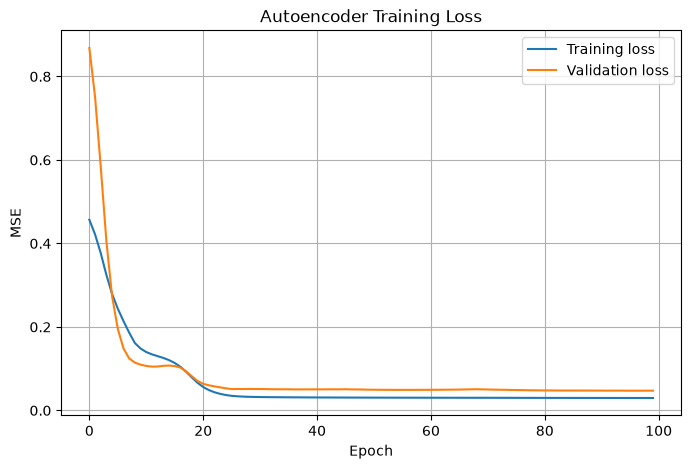

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.grid(True)

plt.show()

In [39]:
# Dự đoán lại dữ liệu Validation
X_val_pred = autoencoder.predict(
    X_val,
    verbose=0
)

# Reconstruction Error cho từng window
val_errors = np.mean(
    np.square(X_val - X_val_pred),
    axis=(1, 2)
)

print("===== VALIDATION RECONSTRUCTION ERROR =====")
print("Number of windows:", len(val_errors))
print("Mean:", val_errors.mean())
print("Std :", val_errors.std())
print("Min :", val_errors.min())
print("Max :", val_errors.max())

print("\nPercentiles:")
for p in [90, 95, 97, 98, 99]:
    print(f"{p}%:", np.percentile(val_errors, p))

===== VALIDATION RECONSTRUCTION ERROR =====
Number of windows: 30
Mean: 0.04726267273668859
Std : 0.01387762674178295
Min : 0.022116507130144243
Max : 0.07651746435082966

Percentiles:
90%: 0.06222761295038586
95%: 0.06895730489388165
97%: 0.07424346562234677
98%: 0.07500146519850773
99%: 0.0757594647746687


In [40]:
# Reconstruction Error trên Test set Normal
X_test_pred = autoencoder.predict(
    X_test,
    verbose=0
)

test_errors = np.mean(
    np.square(X_test - X_test_pred),
    axis=(1, 2)
)

THRESHOLD = np.percentile(val_errors, 99)

test_predictions = test_errors >= THRESHOLD

print("===== TEST NORMAL =====")
print("Number of windows:", len(test_errors))
print("Threshold:", THRESHOLD)

print("\nTest Reconstruction Error:")
print("Mean:", test_errors.mean())
print("Std :", test_errors.std())
print("Min :", test_errors.min())
print("Max :", test_errors.max())

print("\nPredicted anomalies:", test_predictions.sum())
print("Predicted normal   :", (~test_predictions).sum())

print("\nFalse Positive Rate:",
      test_predictions.mean())

===== TEST NORMAL =====
Number of windows: 92
Threshold: 0.0757594647746687

Test Reconstruction Error:
Mean: 0.04860769904404983
Std : 0.013038021313025172
Min : 0.016403693816302425
Max : 0.07796268024158166

Predicted anomalies: 1
Predicted normal   : 91

False Positive Rate: 0.010869565217391304


In [41]:
# ==========================================
# CREATE SYNTHETIC ANOMALY TEST DATA
# ==========================================

df_anomaly = df_test.copy().reset_index(drop=True)

# Tìm sequence dài nhất, tránh đặt anomaly vào vùng có gap > MAX_GAP
time_diff = df_anomaly["created_at"].diff().dt.total_seconds()
sequence_id = (time_diff > MAX_GAP).cumsum()

sequence_lengths = df_anomaly.groupby(sequence_id).size()
longest_seq_id = sequence_lengths.idxmax()

seq_indices = df_anomaly.index[
    sequence_id == longest_seq_id
].tolist()

print("Longest sequence:", len(seq_indices))
print("Sequence ID:", longest_seq_id)

if len(seq_indices) < 40:
    raise ValueError(
        "Sequence dài nhất quá ngắn để tạo đủ anomaly test."
    )


# ==========================================
# Chọn 4 vùng anomaly
# ==========================================

start = seq_indices[0]

anomaly_regions = {
    "spike": seq_indices[10:15],
    "drop": seq_indices[25:30],
    "stuck": seq_indices[40:45],
    "multivariate": seq_indices[50:55]
}


# Lưu Ground Truth theo từng sample
sample_labels = np.zeros(len(df_anomaly), dtype=int)


# ==========================================
# 1. SPIKE
# Temperature tăng đột biến
# ==========================================

idx = anomaly_regions["spike"]

df_anomaly.loc[idx, "temperature"] = 35.0

sample_labels[idx] = 1


# ==========================================
# 2. DROP
# Temperature giảm đột biến
# ==========================================

idx = anomaly_regions["drop"]

df_anomaly.loc[idx, "temperature"] = 24.0

sample_labels[idx] = 1


# ==========================================
# 3. STUCK
# Temperature giữ nguyên một giá trị
# ==========================================

idx = anomaly_regions["stuck"]

stuck_value = df_anomaly.loc[idx[0], "temperature"]

df_anomaly.loc[idx, "temperature"] = stuck_value

sample_labels[idx] = 1


# ==========================================
# 4. MULTIVARIATE INCONSISTENCY
# Temperature tăng nhưng pH giảm
# ==========================================

idx = anomaly_regions["multivariate"]

df_anomaly.loc[idx, "temperature"] = 33.0
df_anomaly.loc[idx, "ph"] = 6.80

sample_labels[idx] = 1


print("\n===== ANOMALY TEST =====")

for name, indices in anomaly_regions.items():
    print(
        f"{name:18s}: "
        f"{len(indices)} samples "
        f"({indices[0]} -> {indices[-1]})"
    )

print("\nTotal anomalous samples:", sample_labels.sum())
print("Total samples:", len(df_anomaly))

Longest sequence: 67
Sequence ID: 5

===== ANOMALY TEST =====
spike             : 5 samples (72 -> 76)
drop              : 5 samples (87 -> 91)
stuck             : 5 samples (102 -> 106)
multivariate      : 5 samples (112 -> 116)

Total anomalous samples: 20
Total samples: 166


In [42]:
# ==========================================
# CREATE LABELED WINDOWS
# ==========================================

def create_labeled_windows(
    df,
    sample_labels,
    scaler,
    window_size=10,
    max_gap=15
):
    df = df.copy()
    df["created_at"] = pd.to_datetime(df["created_at"])

    windows = []
    labels = []

    time_diff = df["created_at"].diff().dt.total_seconds()
    sequence_id = (time_diff > max_gap).cumsum()

    for _, seq in df.groupby(sequence_id):

        if len(seq) < window_size:
            continue

        seq_indices = seq.index.tolist()

        values = seq[FEATURES].astype(float)

        values_scaled = scaler.transform(
            values
        )

        for i in range(
            len(values_scaled) - window_size + 1
        ):

            window = values_scaled[
                i:i + window_size
            ]

            original_indices = seq_indices[
                i:i + window_size
            ]

            # Window là anomaly nếu chứa
            # ít nhất 1 sample anomaly
            window_label = int(
                np.any(
                    sample_labels[
                        original_indices
                    ] == 1
                )
            )

            windows.append(window)
            labels.append(window_label)

    return (
        np.array(windows),
        np.array(labels)
    )


X_anomaly, y_anomaly = create_labeled_windows(
    df_anomaly,
    sample_labels,
    scaler_train,
    WINDOW_SIZE,
    MAX_GAP
)


print("===== LABELED ANOMALY DATASET =====")
print("X_anomaly:", X_anomaly.shape)
print("y_anomaly:", y_anomaly.shape)

print("\nGround Truth:")
print("Normal windows :", np.sum(y_anomaly == 0))
print("Anomaly windows:", np.sum(y_anomaly == 1))

===== LABELED ANOMALY DATASET =====
X_anomaly: (92, 10, 3)
y_anomaly: (92,)

Ground Truth:
Normal windows : 40
Anomaly windows: 52


In [43]:
print("\n===== ANOMALY WINDOW DISTRIBUTION =====")

unique, counts = np.unique(
    y_anomaly,
    return_counts=True
)

for label, count in zip(unique, counts):
    name = "NORMAL" if label == 0 else "ANOMALY"
    print(f"{name}: {count}")


===== ANOMALY WINDOW DISTRIBUTION =====
NORMAL: 40
ANOMALY: 52


In [44]:
# ==========================================
# PREDICT ANOMALY TEST
# ==========================================

X_anomaly_pred = autoencoder.predict(
    X_anomaly,
    verbose=0
)

# Reconstruction Error (sai số tái tạo)
anomaly_errors = np.mean(
    np.square(X_anomaly - X_anomaly_pred),
    axis=(1, 2)
)

# Dùng đúng threshold đã xác định từ Validation
THRESHOLD = np.percentile(val_errors, 99)

y_pred = (anomaly_errors >= THRESHOLD).astype(int)

print("===== ANOMALY TEST RESULT =====")
print("Threshold:", THRESHOLD)

print("\nReconstruction Error:")
print("Mean:", anomaly_errors.mean())
print("Std :", anomaly_errors.std())
print("Min :", anomaly_errors.min())
print("Max :", anomaly_errors.max())

print("\nPrediction:")
print("Predicted Normal :", np.sum(y_pred == 0))
print("Predicted Anomaly:", np.sum(y_pred == 1))

===== ANOMALY TEST RESULT =====
Threshold: 0.0757594647746687

Reconstruction Error:
Mean: 37.17006210940842
Std : 48.492675094223884
Min : 0.024140672242543685
Max : 167.82389514404755

Prediction:
Predicted Normal : 50
Predicted Anomaly: 42


In [45]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(
    y_anomaly,
    y_pred
)

precision = precision_score(
    y_anomaly,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_anomaly,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_anomaly,
    y_pred,
    zero_division=0
)

print("===== MODEL EVALUATION =====")

print("\nConfusion Matrix:")
print(cm)

print("\nPrecision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

print("\nClassification Report:")
print(
    classification_report(
        y_anomaly,
        y_pred,
        target_names=["Normal", "Anomaly"],
        zero_division=0
    )
)

===== MODEL EVALUATION =====

Confusion Matrix:
[[40  0]
 [10 42]]

Precision: 1.0
Recall   : 0.8076923076923077
F1-score : 0.8936170212765957

Classification Report:
              precision    recall  f1-score   support

      Normal       0.80      1.00      0.89        40
     Anomaly       1.00      0.81      0.89        52

    accuracy                           0.89        92
   macro avg       0.90      0.90      0.89        92
weighted avg       0.91      0.89      0.89        92



In [46]:
# ==========================================
# ANALYZE EACH ANOMALY TYPE
# ==========================================

print("===== EACH ANOMALY TYPE =====")

for anomaly_type, indices in anomaly_regions.items():

    # Tìm các window chứa sample thuộc loại anomaly này
    type_window_indices = []

    for i in range(len(X_anomaly)):

        # Vì mỗi window dài 10,
        # kiểm tra xem window có chứa một index
        # thuộc vùng anomaly hay không
        window_indices = set(
            range(
                i,
                i + WINDOW_SIZE
            )
        )

        if window_indices.intersection(set(indices)):
            type_window_indices.append(i)

    type_window_indices = np.array(
        type_window_indices
    )

    if len(type_window_indices) == 0:
        print(f"\n{anomaly_type}: No windows")
        continue

    true_labels = y_anomaly[
        type_window_indices
    ]

    predictions = y_pred[
        type_window_indices
    ]

    detected = np.sum(predictions == 1)
    total = len(type_window_indices)

    recall = detected / total

    print(f"\n{anomaly_type.upper()}")
    print("Windows :", total)
    print("Detected:", detected)
    print("Missed  :", total - detected)
    print("Recall  :", recall)

===== EACH ANOMALY TYPE =====

SPIKE
Windows : 14
Detected: 13
Missed  : 1
Recall  : 0.9285714285714286

DROP
Windows : 14
Detected: 0
Missed  : 14
Recall  : 0.0

stuck: No windows

multivariate: No windows


In [47]:
# ==========================================
# CREATE LABELED WINDOWS WITH ANOMALY TYPE
# ==========================================

def create_labeled_windows_with_type(
    df,
    sample_labels,
    anomaly_regions,
    scaler,
    window_size=10,
    max_gap=15
):

    df = df.copy()
    df["created_at"] = pd.to_datetime(df["created_at"])

    windows = []
    labels = []
    types = []

    time_diff = df["created_at"].diff().dt.total_seconds()
    sequence_id = (time_diff > max_gap).cumsum()

    for _, seq in df.groupby(sequence_id):

        if len(seq) < window_size:
            continue

        seq_indices = seq.index.tolist()

        values = seq[FEATURES].astype(float)

        values_scaled = scaler.transform(values)

        for i in range(len(values_scaled) - window_size + 1):

            window = values_scaled[
                i:i + window_size
            ]

            original_indices = seq_indices[
                i:i + window_size
            ]

            # ----------------------------------
            # Kiểm tra loại anomaly trong window
            # ----------------------------------

            window_type = "normal"

            for anomaly_type, anomaly_indices in anomaly_regions.items():

                if set(original_indices).intersection(
                    set(anomaly_indices)
                ):
                    window_type = anomaly_type
                    break

            label = 0 if window_type == "normal" else 1

            windows.append(window)
            labels.append(label)
            types.append(window_type)

    return (
        np.array(windows),
        np.array(labels),
        np.array(types)
    )


X_anomaly, y_anomaly, anomaly_types = \
    create_labeled_windows_with_type(
        df_anomaly,
        sample_labels,
        anomaly_regions,
        scaler_train,
        WINDOW_SIZE,
        MAX_GAP
    )


print("===== LABELED ANOMALY DATASET =====")

print("X_anomaly:", X_anomaly.shape)
print("y_anomaly:", y_anomaly.shape)

print("\nWindow distribution:")

unique_types, counts = np.unique(
    anomaly_types,
    return_counts=True
)

for t, c in zip(unique_types, counts):
    print(f"{t:20s}: {c}")

===== LABELED ANOMALY DATASET =====
X_anomaly: (92, 10, 3)
y_anomaly: (92,)

Window distribution:
drop                : 14
multivariate        : 10
normal              : 40
spike               : 14
stuck               : 14


In [48]:
# ==========================================
# PREDICT AGAIN
# ==========================================

X_anomaly_pred = autoencoder.predict(
    X_anomaly,
    verbose=0
)

anomaly_errors = np.mean(
    np.square(
        X_anomaly - X_anomaly_pred
    ),
    axis=(1, 2)
)

THRESHOLD = np.percentile(
    val_errors,
    99
)

y_pred = (
    anomaly_errors >= THRESHOLD
).astype(int)

print("Threshold:", THRESHOLD)
print("Predicted Normal :", np.sum(y_pred == 0))
print("Predicted Anomaly:", np.sum(y_pred == 1))

Threshold: 0.0757594647746687
Predicted Normal : 50
Predicted Anomaly: 42


In [49]:
# ==========================================
# EACH ANOMALY TYPE
# ==========================================

print("===== EACH ANOMALY TYPE =====")

for anomaly_type in [
    "spike",
    "drop",
    "stuck",
    "multivariate"
]:

    mask = anomaly_types == anomaly_type

    total = np.sum(mask)

    if total == 0:
        print(f"\n{anomaly_type}: No windows")
        continue

    detected = np.sum(
        y_pred[mask] == 1
    )

    missed = total - detected

    recall = detected / total

    print(f"\n{anomaly_type.upper()}")
    print("Windows :", total)
    print("Detected:", detected)
    print("Missed  :", missed)
    print("Recall  :", recall)

===== EACH ANOMALY TYPE =====

SPIKE
Windows : 14
Detected: 14
Missed  : 0
Recall  : 1.0

DROP
Windows : 14
Detected: 14
Missed  : 0
Recall  : 1.0

STUCK
Windows : 14
Detected: 4
Missed  : 10
Recall  : 0.2857142857142857

MULTIVARIATE
Windows : 10
Detected: 10
Missed  : 0
Recall  : 1.0


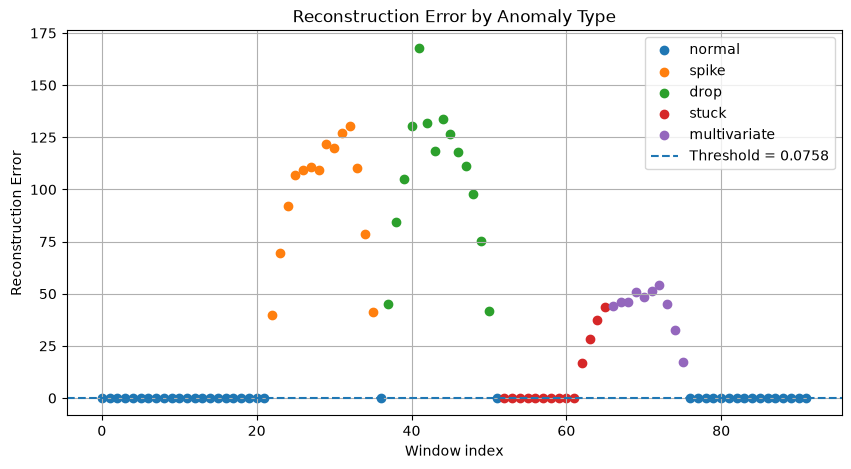

In [50]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

for anomaly_type in ["normal", "spike", "drop", "stuck", "multivariate"]:
    mask = anomaly_types == anomaly_type

    plt.scatter(
        np.where(mask)[0],
        anomaly_errors[mask],
        label=anomaly_type
    )

plt.axhline(
    THRESHOLD,
    linestyle="--",
    label=f"Threshold = {THRESHOLD:.4f}"
)

plt.xlabel("Window index")
plt.ylabel("Reconstruction Error")
plt.title("Reconstruction Error by Anomaly Type")
plt.legend()
plt.grid(True)
plt.show()

In [51]:
for anomaly_type in ["normal", "spike", "drop", "stuck", "multivariate"]:
    mask = anomaly_types == anomaly_type
    errors = anomaly_errors[mask]

    print(f"\n===== {anomaly_type.upper()} =====")
    print("Count  :", len(errors))
    print("Mean   :", errors.mean())
    print("Median :", np.median(errors))
    print("Min    :", errors.min())
    print("Max    :", errors.max())


===== NORMAL =====
Count  : 40
Mean   : 0.04890552461280704
Median : 0.05050167594948151
Min    : 0.02898122872525155
Max    : 0.07124810843881435

===== SPIKE =====
Count  : 14
Mean   : 97.65378728656
Median : 109.3588284824525
Min    : 39.881540275544815
Max    : 130.3449368601724

===== DROP =====
Count  : 14
Mean   : 106.27316922224847
Median : 114.40226769179426
Min    : 41.77553596677389
Max    : 167.82389514404755

===== STUCK =====
Count  : 14
Mean   : 9.072323987982783
Median : 0.05185892665841434
Min    : 0.024140672242543685
Max    : 43.83966158514896

===== MULTIVARIATE =====
Count  : 10
Mean   : 43.56995661259842
Median : 45.95530179361597
Min    : 17.22041715719271
Max    : 54.07415629774781


In [52]:
mask = anomaly_types == "stuck"

stuck_errors = anomaly_errors[mask]
stuck_predictions = y_pred[mask]

print("===== STUCK DETAILS =====")

for i, (error, pred) in enumerate(
    zip(stuck_errors, stuck_predictions)
):
    status = "ANOMALY" if pred == 1 else "NORMAL"

    print(
        f"Window {i:02d} | "
        f"Error = {error:.6f} | "
        f"Prediction = {status}"
    )

===== STUCK DETAILS =====
Window 00 | Error = 0.051908 | Prediction = NORMAL
Window 01 | Error = 0.051228 | Prediction = NORMAL
Window 02 | Error = 0.040765 | Prediction = NORMAL
Window 03 | Error = 0.024141 | Prediction = NORMAL
Window 04 | Error = 0.031334 | Prediction = NORMAL
Window 05 | Error = 0.041562 | Prediction = NORMAL
Window 06 | Error = 0.049968 | Prediction = NORMAL
Window 07 | Error = 0.051810 | Prediction = NORMAL
Window 08 | Error = 0.069476 | Prediction = NORMAL
Window 09 | Error = 0.064444 | Prediction = NORMAL
Window 10 | Error = 16.769996 | Prediction = ANOMALY
Window 11 | Error = 28.508798 | Prediction = ANOMALY
Window 12 | Error = 37.417446 | Prediction = ANOMALY
Window 13 | Error = 43.839662 | Prediction = ANOMALY


In [53]:
FEATURES = ["temperature", "ph", "turbidity"]

train_mean = df_train[FEATURES].mean()
train_std = df_train[FEATURES].std()

print("===== TRAINING STATISTICS =====")
print("Mean:")
print(train_mean)

print("\nStd:")
print(train_std)

===== TRAINING STATISTICS =====
Mean:
temperature    29.259848
ph              6.891939
turbidity       0.000000
dtype: float64

Std:
temperature    0.150487
ph             0.015687
turbidity      0.000000
dtype: float64


In [54]:
# Z-score cho temperature và pH

z_test = pd.DataFrame(index=df_test.index)

for feature in ["temperature", "ph"]:
    z_test[feature] = (
        df_test[feature] - train_mean[feature]
    ) / train_std[feature]

print("===== Z-SCORE ON NORMAL TEST =====")
print(z_test.describe())

===== Z-SCORE ON NORMAL TEST =====
       temperature          ph
count   166.000000  166.000000
mean      2.136236   -0.185076
std       0.293146    0.366230
min       1.595824   -1.398591
25%       1.994528   -0.123632
50%       1.994528   -0.123632
75%       2.393232   -0.123632
max       2.858387    0.513847


In [55]:
print("\n===== MAX ABS Z-SCORE =====")

for feature in ["temperature", "ph"]:
    max_z = np.max(np.abs(z_test[feature]))
    print(f"{feature}: {max_z:.4f}")


===== MAX ABS Z-SCORE =====
temperature: 2.8584
ph: 1.3986


In [56]:
print("===== TURBIDITY CHECK =====")

print("\nValidation:")
print(df_val["turbidity"].describe())

print("\nTest:")
print(df_test["turbidity"].describe())

print("\nAnomaly:")
print(df_test_anomaly["turbidity"].describe() if "df_test_anomaly" in globals() else "Chưa có df_test_anomaly")

===== TURBIDITY CHECK =====

Validation:
count    55.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: turbidity, dtype: float64

Test:
count    166.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: turbidity, dtype: float64

Anomaly:
Chưa có df_test_anomaly


In [57]:
print("Validation:")
print(df_val["turbidity"].describe())

print("\nTest:")
print(df_test["turbidity"].describe())

Validation:
count    55.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: turbidity, dtype: float64

Test:
count    166.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: turbidity, dtype: float64


In [58]:
def statistical_scores(X, scaler):
    """
    Statistical score dựa trên temperature và pH.
    X đã được StandardScaler.
    """

    # Chỉ lấy temperature và pH
    z = X[:, :, :2]

    # Score = |z| lớn nhất trong window
    scores = np.max(np.abs(z), axis=(1, 2))

    return scores

In [59]:
stat_train_scores = statistical_scores(X_train, scaler_train)
stat_val_scores = statistical_scores(X_val, scaler_train)
stat_test_scores = statistical_scores(X_test, scaler_train)

print("Train:", stat_train_scores.shape)
print("Val  :", stat_val_scores.shape)
print("Test :", stat_test_scores.shape)

Train: (181,)
Val  : (30,)
Test : (92,)


In [60]:
STAT_THRESHOLD = np.percentile(stat_val_scores, 99)

print("===== STATISTICAL THRESHOLD =====")
print(f"Threshold: {STAT_THRESHOLD:.6f}")

print("\nValidation Score:")
print(f"Mean   : {stat_val_scores.mean():.6f}")
print(f"Median : {np.median(stat_val_scores):.6f}")
print(f"Min    : {stat_val_scores.min():.6f}")
print(f"Max    : {stat_val_scores.max():.6f}")

===== STATISTICAL THRESHOLD =====
Threshold: 1.997557

Validation Score:
Mean   : 1.864454
Median : 1.997557
Min    : 1.598247
Max    : 1.997557


In [61]:
stat_test_predictions = (
    stat_test_scores >= STAT_THRESHOLD
).astype(int)

print("===== STATISTICAL BASELINE - NORMAL TEST =====")

print("Number of windows :", len(stat_test_scores))
print("Predicted Normal  :", np.sum(stat_test_predictions == 0))
print("Predicted Anomaly :", np.sum(stat_test_predictions == 1))

fpr = np.mean(stat_test_predictions == 1)

print(f"False Positive Rate: {fpr:.4f}")

===== STATISTICAL BASELINE - NORMAL TEST =====
Number of windows : 92
Predicted Normal  : 0
Predicted Anomaly : 92
False Positive Rate: 1.0000


In [62]:
def statistical_scores_mean(X):
    """
    Statistical score dựa trên Mean Squared Z-score
    của temperature và pH trong mỗi window.
    """
    
    z = X[:, :, :2]
    
    scores = np.mean(np.square(z), axis=(1, 2))
    
    return scores

In [63]:
stat_train_scores = statistical_scores_mean(X_train)
stat_val_scores = statistical_scores_mean(X_val)
stat_test_scores = statistical_scores_mean(X_test)

print("Train:", stat_train_scores.shape)
print("Val  :", stat_val_scores.shape)
print("Test :", stat_test_scores.shape)

print("\n===== VALIDATION SCORE =====")
print(f"Mean   : {stat_val_scores.mean():.6f}")
print(f"Median : {np.median(stat_val_scores):.6f}")
print(f"Min    : {stat_val_scores.min():.6f}")
print(f"Max    : {stat_val_scores.max():.6f}")

Train: (181,)
Val  : (30,)
Test : (92,)

===== VALIDATION SCORE =====
Mean   : 1.438240
Median : 1.372191
Min    : 1.307338
Max    : 1.900551


In [64]:
STAT_THRESHOLD = np.percentile(stat_val_scores, 99)

print("===== STATISTICAL THRESHOLD =====")
print(f"Threshold: {STAT_THRESHOLD:.6f}")

===== STATISTICAL THRESHOLD =====
Threshold: 1.892348


In [65]:
stat_test_predictions = (
    stat_test_scores >= STAT_THRESHOLD
).astype(int)

print("===== STATISTICAL BASELINE - NORMAL TEST =====")

print("Number of windows :", len(stat_test_scores))
print("Predicted Normal  :", np.sum(stat_test_predictions == 0))
print("Predicted Anomaly :", np.sum(stat_test_predictions == 1))

fpr = np.mean(stat_test_predictions == 1)

print(f"False Positive Rate: {fpr:.4f}")

===== STATISTICAL BASELINE - NORMAL TEST =====
Number of windows : 92
Predicted Normal  : 15
Predicted Anomaly : 77
False Positive Rate: 0.8370


In [66]:
stat_anomaly_scores = statistical_scores_mean(X_anomaly)

stat_y_pred = (
    stat_anomaly_scores >= STAT_THRESHOLD
).astype(int)

print("===== STATISTICAL BASELINE - ANOMALY TEST =====")

print("Number of windows :", len(stat_y_pred))
print("Predicted Normal  :", np.sum(stat_y_pred == 0))
print("Predicted Anomaly :", np.sum(stat_y_pred == 1))

===== STATISTICAL BASELINE - ANOMALY TEST =====
Number of windows : 92
Predicted Normal  : 15
Predicted Anomaly : 77


In [67]:
print("===== SCORE CHECK =====")

print("Normal Test scores:")
print(stat_test_scores[:20])

print("\nAnomaly scores:")
print(stat_anomaly_scores[:20])

print("\nAre scores exactly equal?")
print(np.array_equal(stat_test_scores, stat_anomaly_scores))

===== SCORE CHECK =====
Normal Test scores:
[1.77799227 1.79046775 1.71867577 1.68124932 1.62193282 1.56261631
 1.6344083  1.6344083  1.70620028 1.77799227 1.79046775 1.77799227
 1.83730877 1.76551679 1.83730877 2.14421278 2.11592678 2.08764078
 2.08764078 2.08764078]

Anomaly scores:
[1.77799227 1.79046775 1.71867577 1.68124932 1.62193282 1.56261631
 1.6344083  1.6344083  1.70620028 1.77799227 1.79046775 1.77799227
 1.83730877 1.76551679 1.83730877 2.14421278 2.11592678 2.08764078
 2.08764078 2.08764078]

Are scores exactly equal?
False


In [68]:
print("\n===== SCORE STATISTICS =====")

print("Normal Test:")
print("Mean:", stat_test_scores.mean())
print("Min :", stat_test_scores.min())
print("Max :", stat_test_scores.max())

print("\nAnomaly:")
print("Mean:", stat_anomaly_scores.mean())
print("Min :", stat_anomaly_scores.min())
print("Max :", stat_anomaly_scores.max())


===== SCORE STATISTICS =====
Normal Test:
Mean: 2.4576394477496666
Min : 1.5626163134095727
Max : 3.159950410782284

Anomaly:
Mean: 92.78307620547001
Min : 1.5626163134095727
Max : 366.034499115998


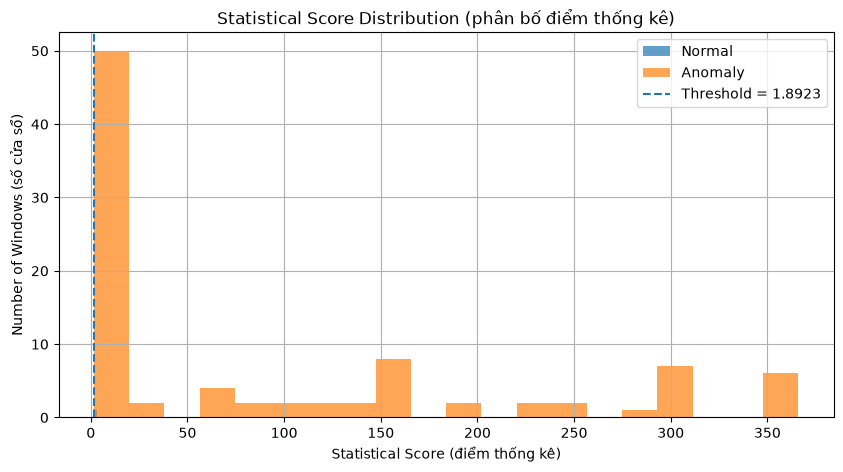

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    stat_test_scores,
    bins=20,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    stat_anomaly_scores,
    bins=20,
    alpha=0.7,
    label="Anomaly"
)

plt.axvline(
    STAT_THRESHOLD,
    linestyle="--",
    label=f"Threshold = {STAT_THRESHOLD:.4f}"
)

plt.xlabel("Statistical Score (điểm thống kê)")
plt.ylabel("Number of Windows (số cửa sổ)")
plt.title("Statistical Score Distribution (phân bố điểm thống kê)")
plt.legend()
plt.grid(True)

plt.show()

In [70]:
print("===== EACH ANOMALY TYPE - STATISTICAL =====")

for anomaly_type in ["spike", "drop", "stuck", "multivariate"]:

    mask = anomaly_types == anomaly_type

    total = np.sum(mask)
    detected = np.sum(stat_y_pred[mask] == 1)
    missed = total - detected

    recall = detected / total if total > 0 else 0

    print(f"\n{anomaly_type.upper()}")
    print("Windows :", total)
    print("Detected:", detected)
    print("Missed  :", missed)
    print("Recall  :", recall)

===== EACH ANOMALY TYPE - STATISTICAL =====

SPIKE
Windows : 14
Detected: 14
Missed  : 0
Recall  : 1.0

DROP
Windows : 14
Detected: 14
Missed  : 0
Recall  : 1.0

STUCK
Windows : 14
Detected: 14
Missed  : 0
Recall  : 1.0

MULTIVARIATE
Windows : 10
Detected: 10
Missed  : 0
Recall  : 1.0


In [71]:
from sklearn.ensemble import IsolationForest

# Chuyển Window (10 x 3) thành vector 30 chiều
X_train_if = X_train.reshape(X_train.shape[0], -1)
X_val_if   = X_val.reshape(X_val.shape[0], -1)
X_test_if  = X_test.reshape(X_test.shape[0], -1)

print("===== ISOLATION FOREST DATA =====")
print("X_train_if:", X_train_if.shape)
print("X_val_if  :", X_val_if.shape)
print("X_test_if :", X_test_if.shape)

===== ISOLATION FOREST DATA =====
X_train_if: (181, 30)
X_val_if  : (30, 30)
X_test_if : (92, 30)


In [72]:
iso_forest = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

iso_forest.fit(X_train_if)

print("===== ISOLATION FOREST =====")
print("Model trained successfully.")
print("Number of trees:", iso_forest.n_estimators)

===== ISOLATION FOREST =====
Model trained successfully.
Number of trees: 200


In [73]:
# Tạo Anomaly Score (điểm bất thường)

iso_train_scores = -iso_forest.decision_function(X_train_if)
iso_val_scores   = -iso_forest.decision_function(X_val_if)
iso_test_scores  = -iso_forest.decision_function(X_test_if)

print("===== ISOLATION FOREST SCORES =====")

print("Train:")
print("Mean:", iso_train_scores.mean())
print("Min :", iso_train_scores.min())
print("Max :", iso_train_scores.max())

print("\nValidation:")
print("Mean:", iso_val_scores.mean())
print("Min :", iso_val_scores.min())
print("Max :", iso_val_scores.max())

print("\nTest:")
print("Mean:", iso_test_scores.mean())
print("Min :", iso_test_scores.min())
print("Max :", iso_test_scores.max())

===== ISOLATION FOREST SCORES =====
Train:
Mean: -0.05137816531696174
Min : -0.1273093049939223
Max : 0.3325683976521262

Validation:
Mean: 0.031240810643263565
Min : -0.010834370795559767
Max : 0.051719959639075164

Test:
Mean: 0.003806221034611891
Min : -0.023017897152838807
Max : 0.05035332844487295


In [74]:
ISO_THRESHOLD = np.percentile(iso_val_scores, 99)

print("===== ISOLATION FOREST THRESHOLD =====")
print(f"Threshold: {ISO_THRESHOLD:.6f}")

print("\nValidation Score:")
print(f"Mean   : {iso_val_scores.mean():.6f}")
print(f"Median : {np.median(iso_val_scores):.6f}")
print(f"Min    : {iso_val_scores.min():.6f}")
print(f"Max    : {iso_val_scores.max():.6f}")

===== ISOLATION FOREST THRESHOLD =====
Threshold: 0.050846

Validation Score:
Mean   : 0.031241
Median : 0.036149
Min    : -0.010834
Max    : 0.051720


In [75]:
iso_test_predictions = (
    iso_test_scores >= ISO_THRESHOLD
).astype(int)

print("===== ISOLATION FOREST - NORMAL TEST =====")

print("Number of windows :", len(iso_test_scores))
print("Predicted Normal  :", np.sum(iso_test_predictions == 0))
print("Predicted Anomaly :", np.sum(iso_test_predictions == 1))

iso_fpr = np.mean(iso_test_predictions == 1)

print(f"False Positive Rate: {iso_fpr:.4f}")

===== ISOLATION FOREST - NORMAL TEST =====
Number of windows : 92
Predicted Normal  : 92
Predicted Anomaly : 0
False Positive Rate: 0.0000


In [76]:
# Tạo score cho bộ Anomaly Test
X_anomaly_if = X_anomaly.reshape(X_anomaly.shape[0], -1)

iso_anomaly_scores = -iso_forest.decision_function(X_anomaly_if)

# Dự đoán
iso_anomaly_predictions = (
    iso_anomaly_scores >= ISO_THRESHOLD
).astype(int)

print("===== ISOLATION FOREST - ANOMALY TEST =====")

print("Number of windows :", len(iso_anomaly_scores))
print("Predicted Normal  :", np.sum(iso_anomaly_predictions == 0))
print("Predicted Anomaly :", np.sum(iso_anomaly_predictions == 1))

===== ISOLATION FOREST - ANOMALY TEST =====
Number of windows : 92
Predicted Normal  : 69
Predicted Anomaly : 23


In [77]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

cm_iso = confusion_matrix(
    y_anomaly,
    iso_anomaly_predictions
)

precision_iso = precision_score(
    y_anomaly,
    iso_anomaly_predictions,
    zero_division=0
)

recall_iso = recall_score(
    y_anomaly,
    iso_anomaly_predictions,
    zero_division=0
)

f1_iso = f1_score(
    y_anomaly,
    iso_anomaly_predictions,
    zero_division=0
)

print("===== ISOLATION FOREST RESULTS =====")

print("\nConfusion Matrix (ma trận nhầm lẫn):")
print(cm_iso)

print(f"\nPrecision (độ chính xác): {precision_iso:.4f}")
print(f"Recall (độ bao phủ):     {recall_iso:.4f}")
print(f"F1-score (điểm F1):      {f1_iso:.4f}")

print("\nClassification Report (báo cáo phân loại):")
print(
    classification_report(
        y_anomaly,
        iso_anomaly_predictions,
        target_names=["Normal (bình thường)", "Anomaly (bất thường)"],
        zero_division=0
    )
)

===== ISOLATION FOREST RESULTS =====

Confusion Matrix (ma trận nhầm lẫn):
[[40  0]
 [29 23]]

Precision (độ chính xác): 1.0000
Recall (độ bao phủ):     0.4423
F1-score (điểm F1):      0.6133

Classification Report (báo cáo phân loại):
                      precision    recall  f1-score   support

Normal (bình thường)       0.58      1.00      0.73        40
Anomaly (bất thường)       1.00      0.44      0.61        52

            accuracy                           0.68        92
           macro avg       0.79      0.72      0.67        92
        weighted avg       0.82      0.68      0.67        92



In [78]:
print("===== EACH ANOMALY TYPE - ISOLATION FOREST =====")

for anomaly_type in ["spike", "drop", "stuck", "multivariate"]:

    mask = anomaly_types == anomaly_type

    total = np.sum(mask)
    detected = np.sum(
        iso_anomaly_predictions[mask] == 1
    )
    missed = total - detected

    recall = detected / total if total > 0 else 0

    print(f"\n{anomaly_type.upper()}")
    print("Windows :", total)
    print("Detected:", detected)
    print("Missed  :", missed)
    print("Recall  :", recall)

===== EACH ANOMALY TYPE - ISOLATION FOREST =====

SPIKE
Windows : 14
Detected: 0
Missed  : 14
Recall  : 0.0

DROP
Windows : 14
Detected: 11
Missed  : 3
Recall  : 0.7857142857142857

STUCK
Windows : 14
Detected: 4
Missed  : 10
Recall  : 0.2857142857142857

MULTIVARIATE
Windows : 10
Detected: 8
Missed  : 2
Recall  : 0.8


In [79]:
# ==========================================
# SO SÁNH RECALL THEO TỪNG LOẠI ANOMALY
# ==========================================

results_by_type = {
    "Spike": {
        "Statistical Baseline": 1.00,
        "Isolation Forest": 0.00,
        "Autoencoder": 1.00
    },
    "Drop": {
        "Statistical Baseline": 1.00,
        "Isolation Forest": 0.785714,
        "Autoencoder": 1.00
    },
    "Stuck": {
        "Statistical Baseline": 1.00,
        "Isolation Forest": 0.285714,
        "Autoencoder": 0.285714
    },
    "Multivariate": {
        "Statistical Baseline": 1.00,
        "Isolation Forest": 0.80,
        "Autoencoder": 1.00
    }
}

comparison_type_df = pd.DataFrame(results_by_type).T

print("===== RECALL THEO TỪNG LOẠI ANOMALY =====")
display(comparison_type_df)

===== RECALL THEO TỪNG LOẠI ANOMALY =====


,Statistical Baseline,Isolation Forest,Autoencoder
Spike,1.0,0.000000,1.000000
Drop,1.0,0.785714,1.000000
Stuck,1.0,0.285714,0.285714
Multivariate,1.0,0.800000,1.000000


In [81]:
# ==========================================
# LSTM-AUTOENCODER
# ==========================================

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, RepeatVector, TimeDistributed

WINDOW_SIZE = 10
N_FEATURES = 3
LATENT_DIM = 4

inputs = Input(shape=(WINDOW_SIZE, N_FEATURES))

# Encoder
encoded = LSTM(16, activation="tanh")(inputs)
latent = Dense(LATENT_DIM, activation="relu")(encoded)

# Decoder
decoded = RepeatVector(WINDOW_SIZE)(latent)
decoded = LSTM(16, activation="tanh", return_sequences=True)(decoded)
outputs = TimeDistributed(
    Dense(N_FEATURES, activation="linear")
)(decoded)

lstm_autoencoder = Model(inputs, outputs)

lstm_autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

lstm_autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 10, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 16)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │            68 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 10, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 10, 16)         │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 10, 3)          │            51 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,743 (10.71 KB)

 Trainable params: 2,743 (10.71 KB)

 Non-trainable params: 0 (0.00 B)

In [82]:
# ==========================================
# TRAIN LSTM-AUTOENCODER
# ==========================================

history_lstm = lstm_autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=16,
    shuffle=True,
    verbose=1
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - loss: 0.4082 - val_loss: 0.6576
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3615 - val_loss: 0.4787
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3147 - val_loss: 0.3313
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2694 - val_loss: 0.2440
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2264 - val_loss: 0.2174
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1897 - val_loss: 0.2009
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1653 - val_loss: 0.1814
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1443 - val_loss: 0.1734
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1272 - val_loss: 0.1746
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1145 - val_loss: 0.1678
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1033 - val_loss: 0.1610
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

In [83]:
# ==========================================
# RECONSTRUCTION ERROR - LSTM-AUTOENCODER
# ==========================================

X_val_reconstructed_lstm = lstm_autoencoder.predict(
    X_val,
    verbose=0
)

val_errors_lstm = np.mean(
    np.square(X_val - X_val_reconstructed_lstm),
    axis=(1, 2)
)

print("===== LSTM-AUTOENCODER VALIDATION ERROR =====")
print("Số windows:", len(val_errors_lstm))
print("Mean:", np.mean(val_errors_lstm))
print("Std :", np.std(val_errors_lstm))
print("Min :", np.min(val_errors_lstm))
print("Max :", np.max(val_errors_lstm))

for p in [90, 95, 97, 98, 99]:
    print(
        f"{p}% percentile:",
        np.percentile(val_errors_lstm, p)
    )

===== LSTM-AUTOENCODER VALIDATION ERROR =====
Số windows: 30
Mean: 0.05747334010466331
Std : 0.017947417570104082
Min : 0.02998516221817134
Max : 0.10733931149765545
90% percentile: 0.07680778122372055
95% percentile: 0.08438735997525514
97% percentile: 0.08787152979883228
98% percentile: 0.09436079036510664
99% percentile: 0.1008500509313811


In [84]:
# ==========================================
# TEST NORMAL - LSTM-AUTOENCODER
# ==========================================

X_test_reconstructed_lstm = lstm_autoencoder.predict(
    X_test,
    verbose=0
)

test_errors_lstm = np.mean(
    np.square(X_test - X_test_reconstructed_lstm),
    axis=(1, 2)
)

THRESHOLD_LSTM = 0.1008500509313811

test_predictions_lstm = (
    test_errors_lstm >= THRESHOLD_LSTM
).astype(int)

normal_anomaly_count = np.sum(test_predictions_lstm == 1)
normal_normal_count = np.sum(test_predictions_lstm == 0)

fpr_lstm = normal_anomaly_count / len(X_test)

print("===== LSTM-AUTOENCODER - NORMAL TEST =====")
print("Total windows :", len(X_test))
print("Predicted NORMAL :", normal_normal_count)
print("Predicted ANOMALY:", normal_anomaly_count)
print("FPR:", fpr_lstm)
print("Mean error:", np.mean(test_errors_lstm))
print("Std error :", np.std(test_errors_lstm))
print("Min error :", np.min(test_errors_lstm))
print("Max error :", np.max(test_errors_lstm))

===== LSTM-AUTOENCODER - NORMAL TEST =====
Total windows : 92
Predicted NORMAL : 31
Predicted ANOMALY: 61
FPR: 0.6630434782608695
Mean error: 0.16272361674360433
Std error : 0.0829166826952657
Min error : 0.05498632347380023
Max error : 0.3418931417818468


In [85]:
# ==========================================
# ANOMALY TEST - LSTM-AUTOENCODER
# ==========================================

X_anomaly_reconstructed_lstm = lstm_autoencoder.predict(
    X_anomaly,
    verbose=0
)

anomaly_errors_lstm = np.mean(
    np.square(X_anomaly - X_anomaly_reconstructed_lstm),
    axis=(1, 2)
)

THRESHOLD_LSTM = 0.1008500509313811

anomaly_predictions_lstm = (
    anomaly_errors_lstm >= THRESHOLD_LSTM
).astype(int)

print("===== LSTM-AUTOENCODER - ANOMALY TEST =====")
print("Total windows :", len(X_anomaly))
print("Predicted NORMAL :", np.sum(anomaly_predictions_lstm == 0))
print("Predicted ANOMALY:", np.sum(anomaly_predictions_lstm == 1))

print("\nMean error:", np.mean(anomaly_errors_lstm))
print("Std error :", np.std(anomaly_errors_lstm))
print("Min error :", np.min(anomaly_errors_lstm))
print("Max error :", np.max(anomaly_errors_lstm))

===== LSTM-AUTOENCODER - ANOMALY TEST =====
Total windows : 92
Predicted NORMAL : 16
Predicted ANOMALY: 76

Mean error: 58.36170828572027
Std error : 79.04119041645573
Min error : 0.05498632347380023
Max error : 224.3506271556244


In [86]:
# ==========================================
# ĐÁNH GIÁ LSTM-AUTOENCODER
# ==========================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

y_true_lstm = y_anomaly
y_pred_lstm = anomaly_predictions_lstm

cm_lstm = confusion_matrix(y_true_lstm, y_pred_lstm)

precision_lstm = precision_score(
    y_true_lstm,
    y_pred_lstm,
    zero_division=0
)

recall_lstm = recall_score(
    y_true_lstm,
    y_pred_lstm,
    zero_division=0
)

f1_lstm = f1_score(
    y_true_lstm,
    y_pred_lstm,
    zero_division=0
)

print("===== LSTM-AUTOENCODER - EVALUATION =====")
print("\nConfusion Matrix:")
print(cm_lstm)

print("\nPrecision :", precision_lstm)
print("Recall    :", recall_lstm)
print("F1-score  :", f1_lstm)

print("\nClassification Report:")
print(
    classification_report(
        y_true_lstm,
        y_pred_lstm,
        target_names=["Normal", "Anomaly"],
        zero_division=0
    )
)

===== LSTM-AUTOENCODER - EVALUATION =====

Confusion Matrix:
[[16 24]
 [ 0 52]]

Precision : 0.6842105263157895
Recall    : 1.0
F1-score  : 0.8125

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.40      0.57        40
     Anomaly       0.68      1.00      0.81        52

    accuracy                           0.74        92
   macro avg       0.84      0.70      0.69        92
weighted avg       0.82      0.74      0.71        92



In [87]:
print("===== EACH ANOMALY TYPE - LSTM-AUTOENCODER =====")

for anomaly_type in ["spike", "drop", "stuck", "multivariate"]:
    mask = anomaly_types == anomaly_type

    total = np.sum(mask)

    detected = np.sum(
        anomaly_predictions_lstm[mask] == 1
    )

    missed = total - detected

    recall = detected / total if total > 0 else 0

    print(f"\n{anomaly_type.upper()}")
    print("Windows :", total)
    print("Detected:", detected)
    print("Missed  :", missed)
    print("Recall  :", recall)

===== EACH ANOMALY TYPE - LSTM-AUTOENCODER =====

SPIKE
Windows : 14
Detected: 14
Missed  : 0
Recall  : 1.0

DROP
Windows : 14
Detected: 14
Missed  : 0
Recall  : 1.0

STUCK
Windows : 14
Detected: 14
Missed  : 0
Recall  : 1.0

MULTIVARIATE
Windows : 10
Detected: 10
Missed  : 0
Recall  : 1.0


In [88]:
# ==========================================
# FINAL MODEL CONFIG
# ==========================================

FINAL_MODEL = "Autoencoder"
FINAL_THRESHOLD = 0.0757594647746687
FINAL_WINDOW_SIZE = 10
FINAL_FEATURES = ["temperature", "ph", "turbidity"]

print("===== FINAL MODEL =====")
print("Model     :", FINAL_MODEL)
print("Threshold :", FINAL_THRESHOLD)
print("Window    :", FINAL_WINDOW_SIZE)
print("Features  :", FINAL_FEATURES)

===== FINAL MODEL =====
Model     : Autoencoder
Threshold : 0.0757594647746687
Window    : 10
Features  : ['temperature', 'ph', 'turbidity']


In [89]:
# ==========================================
# SAVE FINAL MODEL
# ==========================================

import os
import json
import joblib

# Thư mục lưu model
MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)

# 1. Lưu Autoencoder
model_path = os.path.join(
    MODEL_DIR,
    "final_autoencoder.keras"
)

autoencoder.save(model_path)

# 2. Lưu Scaler
scaler_path = os.path.join(
    MODEL_DIR,
    "final_scaler.pkl"
)

joblib.dump(scaler_train, scaler_path)

# 3. Lưu Config
config = {
    "model": "Autoencoder",
    "threshold": 0.0757594647746687,
    "window_size": 10,
    "features": [
        "temperature",
        "ph",
        "turbidity"
    ],
    "latent_dim": 4
}

config_path = os.path.join(
    MODEL_DIR,
    "final_config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("===== SAVED FINAL MODEL =====")
print("Model :", model_path)
print("Scaler:", scaler_path)
print("Config:", config_path)

print("\nFiles:")
print(os.path.getsize(model_path), "bytes - model")
print(os.path.getsize(scaler_path), "bytes - scaler")
print(os.path.getsize(config_path), "bytes - config")

===== SAVED FINAL MODEL =====
Model : ../models\final_autoencoder.keras
Scaler: ../models\final_scaler.pkl
Config: ../models\final_config.json

Files:
80106 bytes - model
911 bytes - scaler
203 bytes - config


In [90]:
# ==========================================
# VERIFY SAVED FINAL MODEL
# ==========================================

import tensorflow as tf
import joblib
import json
import numpy as np

# Load model
loaded_final_model = tf.keras.models.load_model(
    "../models/final_autoencoder.keras"
)

# Load scaler
loaded_final_scaler = joblib.load(
    "../models/final_scaler.pkl"
)

# Load config
with open("../models/final_config.json", "r") as f:
    loaded_final_config = json.load(f)

print("===== LOADED FINAL MODEL =====")
print("Model     :", loaded_final_config["model"])
print("Threshold :", loaded_final_config["threshold"])
print("Window    :", loaded_final_config["window_size"])
print("Features  :", loaded_final_config["features"])

# Predict lại Test
X_test_reconstructed_loaded = loaded_final_model.predict(
    X_test,
    verbose=0
)

test_errors_loaded = np.mean(
    np.square(X_test - X_test_reconstructed_loaded),
    axis=(1, 2)
)

threshold_loaded = loaded_final_config["threshold"]

predictions_loaded = (
    test_errors_loaded >= threshold_loaded
).astype(int)

print("\n===== VERIFY RESULT =====")
print("Test windows :", len(X_test))
print("Predicted NORMAL :", np.sum(predictions_loaded == 0))
print("Predicted ANOMALY:", np.sum(predictions_loaded == 1))
print("Mean error:", np.mean(test_errors_loaded))
print("Max error :", np.max(test_errors_loaded))

===== LOADED FINAL MODEL =====
Model     : Autoencoder
Threshold : 0.0757594647746687
Window    : 10
Features  : ['temperature', 'ph', 'turbidity']

===== VERIFY RESULT =====
Test windows : 92
Predicted NORMAL : 91
Predicted ANOMALY: 1
Mean error: 0.04860769904404983
Max error : 0.07796268024158166


In [91]:
# ==========================================
# CELL 1
# REAL-TIME INFERENCE + BATCH TEST
# ==========================================

import numpy as np
import pandas as pd
import time

FEATURES = loaded_final_config["features"]
WINDOW_SIZE = loaded_final_config["window_size"]
THRESHOLD = loaded_final_config["threshold"]


def predict_realtime(window_data):
    """
    Nhận một cửa sổ gồm 10 mẫu:
    [temperature, ph, turbidity]

    Trả về:
    - reconstruction_error
    - prediction
    - status
    """

    window_data = np.asarray(window_data, dtype=float)

    if window_data.shape != (WINDOW_SIZE, len(FEATURES)):
        raise ValueError(
            f"Input phải có shape "
            f"({WINDOW_SIZE}, {len(FEATURES)})"
        )

    # Chuyển sang DataFrame để scaler nhận đúng tên cột
    window_df = pd.DataFrame(
        window_data,
        columns=FEATURES
    )

    # Chuẩn hóa
    scaled_data = loaded_final_scaler.transform(
        window_df
    )

    # Thêm batch dimension
    model_input = np.expand_dims(
        scaled_data,
        axis=0
    )

    # Dự đoán
    reconstructed = loaded_final_model.predict(
        model_input,
        verbose=0
    )

    # Reconstruction Error
    error = np.mean(
        np.square(
            model_input - reconstructed[0]
        )
    )

    # Phát hiện bất thường
    prediction = int(error >= THRESHOLD)

    status = (
        "ANOMALY"
        if prediction == 1
        else "NORMAL"
    )

    return {
        "reconstruction_error": float(error),
        "prediction": prediction,
        "status": status
    }


# ==========================================
# 1. KIỂM TRA MỘT CỬA SỔ NORMAL
# ==========================================

# X_test hiện đang là dữ liệu đã được chuẩn hóa,
# nên chuyển ngược về giá trị cảm biến thực trước
# khi đưa vào hàm predict_realtime().
test_window_raw = loaded_final_scaler.inverse_transform(
    X_test[0]
)

single_result = predict_realtime(
    test_window_raw
)

print("===== SINGLE WINDOW TEST =====")
print("Reconstruction Error:",
      single_result["reconstruction_error"])
print("Threshold:",
      THRESHOLD)
print("Prediction:",
      single_result["prediction"])
print("Status:",
      single_result["status"])


# ==========================================
# 2. KIỂM TRA TOÀN BỘ X_TEST
# ==========================================

errors_realtime = []
predictions_realtime = []

start_time = time.perf_counter()

for window in X_test:

    # Chuyển từ dữ liệu đã chuẩn hóa
    # về giá trị cảm biến thực
    window_raw = loaded_final_scaler.inverse_transform(
        window
    )

    result = predict_realtime(window_raw)

    errors_realtime.append(
        result["reconstruction_error"]
    )

    predictions_realtime.append(
        result["prediction"]
    )

end_time = time.perf_counter()

errors_realtime = np.array(errors_realtime)
predictions_realtime = np.array(predictions_realtime)

total_time = end_time - start_time
average_time_ms = (
    total_time / len(X_test)
) * 1000


# ==========================================
# 3. KẾT QUẢ
# ==========================================

print("\n===== REAL-TIME BATCH TEST =====")
print("Total windows:",
      len(X_test))

print("Predicted NORMAL:",
      np.sum(predictions_realtime == 0))

print("Predicted ANOMALY:",
      np.sum(predictions_realtime == 1))

print("Mean error:",
      np.mean(errors_realtime))

print("Max error:",
      np.max(errors_realtime))

print("Total inference time:",
      total_time,
      "seconds")

print("Average inference time:",
      average_time_ms,
      "ms/window")

===== SINGLE WINDOW TEST =====
Reconstruction Error: 0.05944580964969008
Threshold: 0.0757594647746687
Prediction: 0
Status: NORMAL

===== REAL-TIME BATCH TEST =====
Total windows: 92
Predicted NORMAL: 91
Predicted ANOMALY: 1
Mean error: 0.048607694850129696
Max error: 0.07796270611352925
Total inference time: 13.027903499998502 seconds
Average inference time: 141.60764673911413 ms/window


In [92]:
# ==========================================
# CELL 2
# REAL-TIME STREAM SIMULATION
# ==========================================

import numpy as np
import pandas as pd
import time

FEATURES = loaded_final_config["features"]
WINDOW_SIZE = loaded_final_config["window_size"]
THRESHOLD = loaded_final_config["threshold"]

# ------------------------------------------
# Lấy dữ liệu Test về dạng giá trị thực
# ------------------------------------------

test_data_raw = loaded_final_scaler.inverse_transform(
    X_test.reshape(-1, len(FEATURES))
)

# ------------------------------------------
# Mô phỏng luồng dữ liệu
# ------------------------------------------

buffer = []

results_stream = []

start_time = time.perf_counter()

for sample in test_data_raw:

    # Nhận một mẫu mới
    buffer.append(sample)

    # Chưa đủ 10 mẫu thì chờ
    if len(buffer) < WINDOW_SIZE:
        continue

    # Lấy 10 mẫu gần nhất
    window = np.array(
        buffer[-WINDOW_SIZE:]
    )

    # Chạy AI
    result = predict_realtime(window)

    results_stream.append({
        "reconstruction_error":
            result["reconstruction_error"],
        "prediction":
            result["prediction"],
        "status":
            result["status"]
    })

end_time = time.perf_counter()

# ------------------------------------------
# Chuyển kết quả thành DataFrame
# ------------------------------------------

results_stream_df = pd.DataFrame(
    results_stream
)

# ------------------------------------------
# Thống kê
# ------------------------------------------

print("===== REAL-TIME STREAM SIMULATION =====")

print("Input samples:",
      len(test_data_raw))

print("Windows processed:",
      len(results_stream_df))

print("NORMAL:",
      np.sum(
          results_stream_df["prediction"] == 0
      ))

print("ANOMALY:",
      np.sum(
          results_stream_df["prediction"] == 1
      ))

print(
    "Mean reconstruction error:",
    results_stream_df[
        "reconstruction_error"
    ].mean()
)

print(
    "Max reconstruction error:",
    results_stream_df[
        "reconstruction_error"
    ].max()
)

print(
    "Total processing time:",
    end_time - start_time,
    "seconds"
)

print(
    "Average time/window:",
    (
        (end_time - start_time)
        / len(results_stream_df)
    ) * 1000,
    "ms"
)

print("\n===== FIRST 10 RESULTS =====")
display(
    results_stream_df.head(10)
)

===== REAL-TIME STREAM SIMULATION =====
Input samples: 920
Windows processed: 911
NORMAL: 900
ANOMALY: 11
Mean reconstruction error: 0.048364488586457
Max reconstruction error: 0.09465534905003799
Total processing time: 164.4898841999966 seconds
Average time/window: 180.55969725575915 ms

===== FIRST 10 RESULTS =====


,reconstruction_error,prediction,status
0,0.059446,0,NORMAL
1,0.055143,0,NORMAL
2,0.059740,0,NORMAL
3,0.055141,0,NORMAL
4,0.056364,0,NORMAL
5,0.059320,0,NORMAL
6,0.055844,0,NORMAL
7,0.066130,0,NORMAL
8,0.059550,0,NORMAL
9,0.061992,0,NORMAL


In [93]:
# ==========================================
# CELL 2
# REAL-TIME STREAM SIMULATION
# ==========================================

import numpy as np
import pandas as pd
import time

FEATURES = loaded_final_config["features"]
WINDOW_SIZE = loaded_final_config["window_size"]
THRESHOLD = loaded_final_config["threshold"]

# Lấy dữ liệu test theo thứ tự thời gian
stream_df = df_test.copy()
stream_df["created_at"] = pd.to_datetime(stream_df["created_at"])
stream_df = stream_df.sort_values("created_at").reset_index(drop=True)

results_stream = []

# Xử lý từng chuỗi liên tục, không cho cửa sổ vượt qua khoảng gap lớn
time_diff = stream_df["created_at"].diff().dt.total_seconds()
sequence_id = (time_diff > 15).cumsum()

total_start = time.perf_counter()

for _, seq in stream_df.groupby(sequence_id):

    buffer = []

    for _, row in seq.iterrows():

        sample = row[FEATURES].astype(float).values
        buffer.append(sample)

        if len(buffer) < WINDOW_SIZE:
            continue

        window = np.array(buffer[-WINDOW_SIZE:])

        start = time.perf_counter()

        result = predict_realtime(window)

        end = time.perf_counter()

        results_stream.append({
            "created_at": row["created_at"],
            "reconstruction_error": result["reconstruction_error"],
            "prediction": result["prediction"],
            "status": result["status"],
            "inference_time_ms": (end - start) * 1000
        })

total_end = time.perf_counter()

results_stream_df = pd.DataFrame(results_stream)

print("===== REAL-TIME STREAM SIMULATION =====")
print("Input samples:", len(stream_df))
print("Windows processed:", len(results_stream_df))

print("NORMAL:",
      np.sum(results_stream_df["prediction"] == 0))

print("ANOMALY:",
      np.sum(results_stream_df["prediction"] == 1))

print("Mean reconstruction error:",
      results_stream_df["reconstruction_error"].mean())

print("Max reconstruction error:",
      results_stream_df["reconstruction_error"].max())

print("Total processing time:",
      total_end - total_start, "seconds")

print("Average inference time:",
      results_stream_df["inference_time_ms"].mean(), "ms/window")

print("Maximum inference time:",
      results_stream_df["inference_time_ms"].max(), "ms/window")

print("\n===== FIRST 10 RESULTS =====")
display(results_stream_df.head(10))

===== REAL-TIME STREAM SIMULATION =====
Input samples: 166
Windows processed: 92
NORMAL: 91
ANOMALY: 1
Mean reconstruction error: 0.04861308909577317
Max reconstruction error: 0.07796270611352925
Total processing time: 18.264743399995496 seconds
Average inference time: 195.5582891302544 ms/window
Maximum inference time: 2917.252200000803 ms/window

===== FIRST 10 RESULTS =====


,created_at,reconstruction_error,prediction,status,inference_time_ms
0,2026-09-12 14:46:18,0.059446,0,NORMAL,121.6906
1,2026-09-12 14:46:24,0.061676,0,NORMAL,2917.2522
2,2026-09-12 14:46:30,0.065342,0,NORMAL,194.4436
3,2026-09-12 14:47:32,0.055794,0,NORMAL,142.0164
4,2026-09-12 14:47:37,0.060778,0,NORMAL,150.5374
5,2026-09-12 14:47:43,0.052670,0,NORMAL,251.3336
6,2026-09-12 14:47:50,0.052913,0,NORMAL,188.8801
7,2026-09-12 14:47:51,0.049745,0,NORMAL,94.6097
8,2026-09-12 14:47:55,0.045052,0,NORMAL,80.2206
9,2026-09-12 14:48:01,0.057315,0,NORMAL,76.3642


In [94]:
# ==========================================
# CELL 3
# FINAL PERFORMANCE + EDGE PREPARATION
# ==========================================

import os
import json
import time
import numpy as np
import pandas as pd
import psutil

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

print("=" * 60)
print("FINAL MODEL PERFORMANCE EVALUATION")
print("=" * 60)

# --------------------------------------------------
# 1. MODEL INFORMATION
# --------------------------------------------------

model_path = "../models/final_autoencoder.keras"
scaler_path = "../models/final_scaler.pkl"
config_path = "../models/final_config.json"

model_size_kb = os.path.getsize(model_path) / 1024
scaler_size_kb = os.path.getsize(scaler_path) / 1024
config_size_kb = os.path.getsize(config_path) / 1024

print("\n===== MODEL INFORMATION =====")
print("Model:", "Autoencoder (bộ mã hóa tự động)")
print("Parameters:", loaded_final_model.count_params())
print("Model file size:", model_size_kb, "KB")
print("Scaler file size:", scaler_size_kb, "KB")
print("Config file size:", config_size_kb, "KB")
print("Window size:", WINDOW_SIZE)
print("Features:", FEATURES)
print("Threshold:", THRESHOLD)


# --------------------------------------------------
# 2. CPU / RAM BEFORE INFERENCE
# --------------------------------------------------

process = psutil.Process(os.getpid())

cpu_before = psutil.cpu_percent(interval=1)
ram_before = process.memory_info().rss / (1024 ** 2)

print("\n===== RESOURCE BEFORE INFERENCE =====")
print("CPU usage:", cpu_before, "%")
print("RAM process:", ram_before, "MB")


# --------------------------------------------------
# 3. WARM-UP
# --------------------------------------------------
# Loại ảnh hưởng của lần suy luận đầu tiên

warmup_window = X_test[:1]

_ = loaded_final_model.predict(
    warmup_window,
    verbose=0
)


# --------------------------------------------------
# 4. MEASURE INFERENCE PERFORMANCE
# --------------------------------------------------

inference_times = []
errors = []

for window in X_test:

    window_input = np.expand_dims(window, axis=0)

    start = time.perf_counter()

    reconstructed = loaded_final_model.predict(
        window_input,
        verbose=0
    )

    end = time.perf_counter()

    inference_times.append((end - start) * 1000)

    error = np.mean(
        np.square(window_input - reconstructed)
    )

    errors.append(error)


inference_times = np.array(inference_times)
errors = np.array(errors)


# --------------------------------------------------
# 5. CPU / RAM AFTER INFERENCE
# --------------------------------------------------

cpu_after = psutil.cpu_percent(interval=1)
ram_after = process.memory_info().rss / (1024 ** 2)


# --------------------------------------------------
# 6. PERFORMANCE RESULTS
# --------------------------------------------------

print("\n===== INFERENCE PERFORMANCE =====")

print("Number of windows:", len(X_test))

print(
    "Average inference time:",
    np.mean(inference_times),
    "ms/window"
)

print(
    "Median inference time:",
    np.median(inference_times),
    "ms/window"
)

print(
    "Minimum inference time:",
    np.min(inference_times),
    "ms/window"
)

print(
    "Maximum inference time:",
    np.max(inference_times),
    "ms/window"
)

print(
    "95th percentile:",
    np.percentile(inference_times, 95),
    "ms/window"
)

print("\n===== RESOURCE USAGE =====")
print("CPU before:", cpu_before, "%")
print("CPU after:", cpu_after, "%")
print("RAM before:", ram_before, "MB")
print("RAM after:", ram_after, "MB")


# --------------------------------------------------
# 7. FINAL NORMAL TEST EVALUATION
# --------------------------------------------------

y_true_normal = np.zeros(len(X_test), dtype=int)

y_pred_normal = (
    errors > THRESHOLD
).astype(int)

normal_fpr = np.mean(
    y_pred_normal == 1
) * 100

print("\n===== NORMAL DATA =====")
print("Total windows:", len(X_test))
print("Predicted NORMAL:", np.sum(y_pred_normal == 0))
print("Predicted ANOMALY:", np.sum(y_pred_normal == 1))
print("False Positive Rate (tỷ lệ báo động giả):",
      normal_fpr, "%")


# --------------------------------------------------
# 8. FINAL SYNTHETIC ANOMALY EVALUATION
# --------------------------------------------------

anomaly_errors = []

for window in X_anomaly:

    window_input = np.expand_dims(window, axis=0)

    reconstructed = loaded_final_model.predict(
        window_input,
        verbose=0
    )

    error = np.mean(
        np.square(window_input - reconstructed)
    )

    anomaly_errors.append(error)


anomaly_errors = np.array(anomaly_errors)

y_pred_anomaly = (
    anomaly_errors > THRESHOLD
).astype(int)


# y_anomaly đã được tạo ở Giai đoạn 2
cm = confusion_matrix(
    y_anomaly,
    y_pred_anomaly
)

precision = precision_score(
    y_anomaly,
    y_pred_anomaly,
    zero_division=0
)

recall = recall_score(
    y_anomaly,
    y_pred_anomaly,
    zero_division=0
)

f1 = f1_score(
    y_anomaly,
    y_pred_anomaly,
    zero_division=0
)

accuracy = accuracy_score(
    y_anomaly,
    y_pred_anomaly
)


print("\n===== ANOMALY DATA =====")

print("Confusion Matrix:")
print(cm)

print("\nPrecision (độ chính xác dự đoán):", precision)
print("Recall (độ bao phủ):", recall)
print("F1-score (điểm F1):", f1)
print("Accuracy (độ chính xác tổng thể):", accuracy)


# --------------------------------------------------
# 9. FINAL COMPARISON
# --------------------------------------------------

comparison = pd.DataFrame({
    "Method": [
        "Statistical Baseline",
        "Isolation Forest",
        "Autoencoder",
        "LSTM-Autoencoder"
    ],
    "Precision": [
        52/77,
        1.0,
        1.0,
        0.6842105
    ],
    "Recall": [
        1.0,
        0.4423077,
        0.8076923,
        1.0
    ],
    "F1": [
        0.8062016,
        0.6133333,
        0.8936170,
        0.8125
    ],
    "Normal_FPR": [
        83.70,
        0.0,
        1.09,
        66.30
    ]
})

print("\n===== FINAL MODEL COMPARISON =====")
display(comparison)


# --------------------------------------------------
# 10. SAVE FINAL PERFORMANCE RESULT
# --------------------------------------------------

final_result = {
    "model": "Autoencoder",
    "threshold": float(THRESHOLD),
    "window_size": int(WINDOW_SIZE),
    "features": FEATURES,
    "parameters": int(loaded_final_model.count_params()),
    "model_size_kb": float(model_size_kb),
    "scaler_size_kb": float(scaler_size_kb),
    "config_size_kb": float(config_size_kb),
    "normal_fpr_percent": float(normal_fpr),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "accuracy": float(accuracy),
    "average_inference_ms": float(np.mean(inference_times)),
    "median_inference_ms": float(np.median(inference_times)),
    "p95_inference_ms": float(np.percentile(inference_times, 95)),
    "ram_before_mb": float(ram_before),
    "ram_after_mb": float(ram_after)
}

with open(
    "../results/final_performance.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        final_result,
        f,
        indent=4,
        ensure_ascii=False
    )

comparison.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("\n===== SAVED =====")
print("../results/final_performance.json")
print("../results/model_comparison.csv")

print("\n" + "=" * 60)
print("GIAI ĐOẠN 5 - CELL 3 HOÀN THÀNH")
print("=" * 60)

FINAL MODEL PERFORMANCE EVALUATION

===== MODEL INFORMATION =====
Model: Autoencoder (bộ mã hóa tự động)
Parameters: 2610
Model file size: 78.228515625 KB
Scaler file size: 0.8896484375 KB
Config file size: 0.1982421875 KB
Window size: 10
Features: ['temperature', 'ph', 'turbidity']
Threshold: 0.0757594647746687

===== RESOURCE BEFORE INFERENCE =====
CPU usage: 39.6 %
RAM process: 205.87890625 MB

===== INFERENCE PERFORMANCE =====
Number of windows: 92
Average inference time: 100.99729782624586 ms/window
Median inference time: 79.6606999974756 ms/window
Minimum inference time: 58.61519999598386 ms/window
Maximum inference time: 208.77430000109598 ms/window
95th percentile: 199.87990500230808 ms/window

===== RESOURCE USAGE =====
CPU before: 39.6 %
CPU after: 19.7 %
RAM before: 205.87890625 MB
RAM after: 180.8828125 MB

===== NORMAL DATA =====
Total windows: 92
Predicted NORMAL: 91
Predicted ANOMALY: 1
False Positive Rate (tỷ lệ báo động giả): 1.0869565217391304 %

===== ANOMALY DATA ==

,Method,Precision,Recall,F1,Normal_FPR
0,Statistical Baseline,0.675325,1.000000,0.806202,83.70
1,Isolation Forest,1.000000,0.442308,0.613333,0.00
2,Autoencoder,1.000000,0.807692,0.893617,1.09
3,LSTM-Autoencoder,0.684211,1.000000,0.812500,66.30



===== SAVED =====
../results/final_performance.json
../results/model_comparison.csv

GIAI ĐOẠN 5 - CELL 3 HOÀN THÀNH


In [2]:
# ==========================================
# CELL 2 - CONTINUE TFLITE VERIFICATION
# ==========================================

import os
import json
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf

print("=" * 60)
print("RESTORE TEST DATA + VERIFY TFLITE")
print("=" * 60)

# --------------------------------------------------
# 1. LOAD CONFIG
# --------------------------------------------------

with open(
    "../models/final_config.json",
    "r",
    encoding="utf-8"
) as f:
    config = json.load(f)

FEATURES = config["features"]
WINDOW_SIZE = config["window_size"]
THRESHOLD = config["threshold"]

print("\n===== CONFIG =====")
print("Features:", FEATURES)
print("Window size:", WINDOW_SIZE)
print("Threshold:", THRESHOLD)


# --------------------------------------------------
# 2. LOAD SCALER
# --------------------------------------------------

with open(
    "../models/final_scaler.pkl",
    "rb"
) as f:
    scaler = pickle.load(f)

print("\nScaler loaded")


# --------------------------------------------------
# 3. LOAD RAW DATA
# --------------------------------------------------

data_path = "../data/normal_60min.tsv"

df = pd.read_csv(
    data_path,
    sep="\t"
)

df["created_at"] = pd.to_datetime(
    df["created_at"]
)

# Loại 4 mẫu nhiệt độ lỗi giống pipeline trước
df = df[
    (df["temperature"] >= 20) &
    (df["temperature"] <= 40)
].copy()

# Loại duplicate
df = df.drop_duplicates(
    subset=[
        "created_at",
        "temperature",
        "ph",
        "turbidity"
    ]
).sort_values(
    "created_at"
).reset_index(drop=True)

print("\n===== CLEAN DATA =====")
print("Samples:", len(df))


# --------------------------------------------------
# 4. RECREATE TRAIN / VALIDATION / TEST SPLIT
# --------------------------------------------------

n = len(df)

train_end = int(n * 0.60)
val_end = train_end + int(n * 0.10)

df_train = df.iloc[:train_end].copy()
df_val = df.iloc[train_end:val_end].copy()
df_test = df.iloc[val_end:].copy()

print("\n===== DATA SPLIT =====")
print("Train:", len(df_train))
print("Validation:", len(df_val))
print("Test:", len(df_test))


# --------------------------------------------------
# 5. CREATE TEST WINDOWS
# --------------------------------------------------

def create_windows(
    df_input,
    scaler,
    window_size=10,
    max_gap=15
):

    df_input = df_input.copy()

    df_input["created_at"] = pd.to_datetime(
        df_input["created_at"]
    )

    time_diff = (
        df_input["created_at"]
        .diff()
        .dt.total_seconds()
    )

    sequence_id = (
        time_diff > max_gap
    ).cumsum()

    windows = []

    for _, seq in df_input.groupby(
        sequence_id
    ):

        if len(seq) < window_size:
            continue

        values = seq[
            FEATURES
        ].astype(float).values

        values_scaled = scaler.transform(
            pd.DataFrame(
                values,
                columns=FEATURES
            )
        )

        for i in range(
            len(values_scaled) - window_size + 1
        ):

            windows.append(
                values_scaled[
                    i:i + window_size
                ]
            )

    return np.array(
        windows,
        dtype=np.float32
    )


X_test = create_windows(
    df_test,
    scaler,
    WINDOW_SIZE,
    15
)

print("\n===== TEST WINDOWS =====")
print("X_test shape:", X_test.shape)


# --------------------------------------------------
# 6. LOAD TFLITE
# --------------------------------------------------

tflite_path = (
    "../models/final_autoencoder_float32.tflite"
)

interpreter = tf.lite.Interpreter(
    model_path=tflite_path
)

interpreter.allocate_tensors()

input_details = (
    interpreter.get_input_details()
)

output_details = (
    interpreter.get_output_details()
)


# --------------------------------------------------
# 7. LOAD KERAS
# --------------------------------------------------

keras_model = tf.keras.models.load_model(
    "../models/final_autoencoder.keras"
)


# --------------------------------------------------
# 8. COMPARE KERAS VS TFLITE
# --------------------------------------------------

comparison_errors = []

num_test = min(
    20,
    len(X_test)
)

for i in range(num_test):

    sample = X_test[
        i:i + 1
    ].astype(np.float32)

    keras_output = (
        keras_model.predict(
            sample,
            verbose=0
        )
    )

    interpreter.set_tensor(
        input_details[0]["index"],
        sample
    )

    interpreter.invoke()

    tflite_output = (
        interpreter.get_tensor(
            output_details[0]["index"]
        )
    )

    difference = np.mean(
        np.abs(
            keras_output -
            tflite_output
        )
    )

    comparison_errors.append(
        difference
    )


comparison_errors = np.array(
    comparison_errors
)


# --------------------------------------------------
# 9. RECONSTRUCTION ERROR
# --------------------------------------------------

tflite_errors = []
keras_errors = []

for i in range(len(X_test)):

    sample = X_test[
        i:i + 1
    ].astype(np.float32)

    # Keras
    keras_output = (
        keras_model.predict(
            sample,
            verbose=0
        )
    )

    keras_error = np.mean(
        np.square(
            sample -
            keras_output
        )
    )

    keras_errors.append(
        keras_error
    )

    # TFLite
    interpreter.set_tensor(
        input_details[0]["index"],
        sample
    )

    interpreter.invoke()

    tflite_output = (
        interpreter.get_tensor(
            output_details[0]["index"]
        )
    )

    tflite_error = np.mean(
        np.square(
            sample -
            tflite_output
        )
    )

    tflite_errors.append(
        tflite_error
    )


keras_errors = np.array(
    keras_errors
)

tflite_errors = np.array(
    tflite_errors
)


# --------------------------------------------------
# 10. RESULTS
# --------------------------------------------------

print("\n===== KERAS VS TFLITE =====")

print(
    "Mean output difference:",
    np.mean(comparison_errors)
)

print(
    "Maximum output difference:",
    np.max(comparison_errors)
)

print("\n===== RECONSTRUCTION ERROR =====")

print(
    "Keras mean:",
    np.mean(keras_errors)
)

print(
    "TFLite mean:",
    np.mean(tflite_errors)
)

print(
    "Keras max:",
    np.max(keras_errors)
)

print(
    "TFLite max:",
    np.max(tflite_errors)
)


# --------------------------------------------------
# 11. THRESHOLD RESULT
# --------------------------------------------------

keras_predictions = (
    keras_errors > THRESHOLD
).astype(int)

tflite_predictions = (
    tflite_errors > THRESHOLD
).astype(int)

print("\n===== THRESHOLD TEST =====")

print(
    "Threshold:",
    THRESHOLD
)

print(
    "Keras anomalies:",
    np.sum(
        keras_predictions == 1
    )
)

print(
    "TFLite anomalies:",
    np.sum(
        tflite_predictions == 1
    )
)


# --------------------------------------------------
# 12. FINAL
# --------------------------------------------------

print("\n" + "=" * 60)
print("TFLITE VERIFICATION COMPLETED")
print("=" * 60)

RESTORE TEST DATA + VERIFY TFLITE

===== CONFIG =====
Features: ['temperature', 'ph', 'turbidity']
Window size: 10
Threshold: 0.0757594647746687


UnpicklingError: STACK_GLOBAL requires str

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

FEATURES = ["temperature", "ph", "turbidity"]

# Load dữ liệu
df = pd.read_csv(
    "../data/normal_60min.tsv",
    sep="\t"
)

df["created_at"] = pd.to_datetime(df["created_at"])

# Loại 4 mẫu nhiệt độ lỗi giống pipeline trước
df = df[
    (df["temperature"] >= 20) &
    (df["temperature"] <= 40)
].copy()

# Loại duplicate giống pipeline trước
df = df.drop_duplicates(
    subset=[
        "created_at",
        "temperature",
        "ph",
        "turbidity"
    ]
).sort_values(
    "created_at"
).reset_index(drop=True)

# Chia dữ liệu giống pipeline trước
n = len(df)

train_end = int(n * 0.60)

df_train = df.iloc[:train_end].copy()

# Tạo scaler mới và CHỈ fit trên training
scaler = StandardScaler()

scaler.fit(
    df_train[FEATURES].astype(float)
)

print("===== RECREATED SCALER =====")
print("Training samples:", len(df_train))
print("Mean:", scaler.mean_)
print("Scale:", scaler.scale_)

print("\nExpected approximate values:")
print("Temperature mean ~29.259848")
print("Temperature std   ~0.150487")
print("pH mean            ~6.891939")
print("pH std              ~0.015687")
print("Turbidity std       = 0")

# Test transform
test_values = scaler.transform(
    df_train[FEATURES].astype(float).head(3)
)

print("\nScaler test:")
print(test_values)

print("\n===== SCALER READY =====")

===== RECREATED SCALER =====
Training samples: 330
Mean: [29.25984848  6.89193939  0.        ]
Scale: [0.1502593 0.015663  1.       ]

Expected approximate values:
Temperature mean ~29.259848
Temperature std   ~0.150487
pH mean            ~6.891939
pH std              ~0.015687
Turbidity std       = 0

Scaler test:
[[-1.72933384 -5.23139748  0.        ]
 [-1.33002411 -5.23139748  0.        ]
 [-1.72933384 -5.23139748  0.        ]]

===== SCALER READY =====


In [4]:
# ==========================================
# CELL 2
# VERIFY TFLITE MODEL
# ==========================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf

print("=" * 60)
print("VERIFY TFLITE MODEL")
print("=" * 60)

# --------------------------------------------------
# 1. CONFIG
# --------------------------------------------------

FEATURES = ["temperature", "ph", "turbidity"]
WINDOW_SIZE = 10
THRESHOLD = 0.0757594647746687

# --------------------------------------------------
# 2. CREATE TEST DATA
# --------------------------------------------------

df_val_end = int(len(df) * 0.60) + int(len(df) * 0.10)

df_test = df.iloc[df_val_end:].copy()

def create_windows_test(
    df_input,
    scaler,
    window_size=10,
    max_gap=15
):
    df_input = df_input.copy()
    df_input["created_at"] = pd.to_datetime(
        df_input["created_at"]
    )

    time_diff = (
        df_input["created_at"]
        .diff()
        .dt.total_seconds()
    )

    sequence_id = (
        time_diff > max_gap
    ).cumsum()

    windows = []

    for _, seq in df_input.groupby(sequence_id):

        if len(seq) < window_size:
            continue

        values = seq[
            FEATURES
        ].astype(float).values

        values_scaled = scaler.transform(
            pd.DataFrame(
                values,
                columns=FEATURES
            )
        )

        for i in range(
            len(values_scaled) - window_size + 1
        ):
            windows.append(
                values_scaled[
                    i:i + window_size
                ]
            )

    return np.array(
        windows,
        dtype=np.float32
    )

X_test = create_windows_test(
    df_test,
    scaler,
    WINDOW_SIZE,
    15
)

print("\n===== TEST DATA =====")
print("Test samples:", len(df_test))
print("X_test shape:", X_test.shape)


# --------------------------------------------------
# 3. LOAD KERAS
# --------------------------------------------------

keras_model = tf.keras.models.load_model(
    "../models/final_autoencoder.keras"
)


# --------------------------------------------------
# 4. LOAD TFLITE
# --------------------------------------------------

tflite_path = (
    "../models/final_autoencoder_float32.tflite"
)

interpreter = tf.lite.Interpreter(
    model_path=tflite_path
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()


# --------------------------------------------------
# 5. COMPARE KERAS VS TFLITE
# --------------------------------------------------

output_differences = []

for i in range(
    min(20, len(X_test))
):

    sample = X_test[
        i:i + 1
    ].astype(np.float32)

    keras_output = keras_model.predict(
        sample,
        verbose=0
    )

    interpreter.set_tensor(
        input_details[0]["index"],
        sample
    )

    interpreter.invoke()

    tflite_output = interpreter.get_tensor(
        output_details[0]["index"]
    )

    difference = np.mean(
        np.abs(
            keras_output -
            tflite_output
        )
    )

    output_differences.append(
        difference
    )


output_differences = np.array(
    output_differences
)


# --------------------------------------------------
# 6. RECONSTRUCTION ERROR
# --------------------------------------------------

keras_errors = []
tflite_errors = []

for i in range(len(X_test)):

    sample = X_test[
        i:i + 1
    ].astype(np.float32)

    # Keras
    keras_output = keras_model.predict(
        sample,
        verbose=0
    )

    keras_error = np.mean(
        np.square(
            sample -
            keras_output
        )
    )

    keras_errors.append(
        keras_error
    )

    # TFLite
    interpreter.set_tensor(
        input_details[0]["index"],
        sample
    )

    interpreter.invoke()

    tflite_output = interpreter.get_tensor(
        output_details[0]["index"]
    )

    tflite_error = np.mean(
        np.square(
            sample -
            tflite_output
        )
    )

    tflite_errors.append(
        tflite_error
    )


keras_errors = np.array(
    keras_errors
)

tflite_errors = np.array(
    tflite_errors
)


# --------------------------------------------------
# 7. RESULTS
# --------------------------------------------------

print("\n===== KERAS VS TFLITE =====")

print(
    "Mean output difference:",
    np.mean(output_differences)
)

print(
    "Maximum output difference:",
    np.max(output_differences)
)

print("\n===== RECONSTRUCTION ERROR =====")

print(
    "Keras mean:",
    np.mean(keras_errors)
)

print(
    "TFLite mean:",
    np.mean(tflite_errors)
)

print(
    "Keras max:",
    np.max(keras_errors)
)

print(
    "TFLite max:",
    np.max(tflite_errors)
)


# --------------------------------------------------
# 8. THRESHOLD
# --------------------------------------------------

keras_predictions = (
    keras_errors > THRESHOLD
).astype(int)

tflite_predictions = (
    tflite_errors > THRESHOLD
).astype(int)

print("\n===== THRESHOLD TEST =====")

print(
    "Threshold:",
    THRESHOLD
)

print(
    "Keras anomalies:",
    np.sum(
        keras_predictions == 1
    )
)

print(
    "TFLite anomalies:",
    np.sum(
        tflite_predictions == 1
    )
)

print(
    "Prediction differences:",
    np.sum(
        keras_predictions !=
        tflite_predictions
    )
)

print("\n" + "=" * 60)
print("TFLITE VERIFICATION COMPLETED")
print("=" * 60)

VERIFY TFLITE MODEL

===== TEST DATA =====
Test samples: 166
X_test shape: (92, 10, 3)


c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



===== KERAS VS TFLITE =====
Mean output difference: 1.4044903e-07
Maximum output difference: 2.747518e-07

===== RECONSTRUCTION ERROR =====
Keras mean: 0.048607692
TFLite mean: 0.048607696
Keras max: 0.07796271
TFLite max: 0.07796268

===== THRESHOLD TEST =====
Threshold: 0.0757594647746687
Keras anomalies: 1
TFLite anomalies: 1
Prediction differences: 0

TFLITE VERIFICATION COMPLETED


In [ ]:
# ==========================================
# CELL 3
# INT8 QUANTIZATION + ESP32-C3 PACKAGE
# ==========================================

import os
import json
import numpy as np
import tensorflow as tf

print("=" * 60)
print("ESP32-C3 MODEL OPTIMIZATION")
print("=" * 60)

# --------------------------------------------------
# 1. PATH
# --------------------------------------------------

float32_path = "../models/final_autoencoder_float32.tflite"
int8_path = "../models/final_autoencoder_int8.tflite"
header_path = "../models/final_autoencoder_int8.h"

# --------------------------------------------------
# 2. REPRESENTATIVE DATA
# --------------------------------------------------
# Dữ liệu đại diện dùng để hiệu chỉnh lượng tử hóa.
# Sử dụng X_test đã được tạo ở Cell 2.

def representative_dataset():
    for i in range(min(100, len(X_test))):
        sample = X_test[i:i+1].astype(np.float32)
        yield [sample]

# --------------------------------------------------
# 3. INT8 QUANTIZATION
# --------------------------------------------------

keras_model = tf.keras.models.load_model(
    "../models/final_autoencoder.keras"
)

converter = tf.lite.TFLiteConverter.from_keras_model(
    keras_model
)

converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

converter.representative_dataset = representative_dataset

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

int8_model = converter.convert()

with open(int8_path, "wb") as f:
    f.write(int8_model)

print("\n===== INT8 CONVERSION =====")
print("Conversion successful")

# --------------------------------------------------
# 4. MODEL SIZE
# --------------------------------------------------

float32_size = os.path.getsize(
    float32_path
)

int8_size = os.path.getsize(
    int8_path
)

print("\n===== MODEL SIZE =====")

print(
    "Float32 TFLite:",
    round(float32_size / 1024, 2),
    "KB"
)

print(
    "Int8 TFLite:",
    round(int8_size / 1024, 2),
    "KB"
)

print(
    "Size reduction:",
    round(
        (1 - int8_size / float32_size) * 100,
        2
    ),
    "%"
)

# --------------------------------------------------
# 5. LOAD INT8 MODEL
# --------------------------------------------------

interpreter = tf.lite.Interpreter(
    model_path=int8_path
)

interpreter.allocate_tensors()

input_details = (
    interpreter.get_input_details()
)

output_details = (
    interpreter.get_output_details()
)

input_scale, input_zero_point = (
    input_details[0]["quantization"]
)

output_scale, output_zero_point = (
    output_details[0]["quantization"]
)

print("\n===== INT8 INFORMATION =====")

print(
    "Input shape:",
    input_details[0]["shape"]
)

print(
    "Input type:",
    input_details[0]["dtype"]
)

print(
    "Input scale:",
    input_scale
)

print(
    "Input zero point:",
    input_zero_point
)

print(
    "Output type:",
    output_details[0]["dtype"]
)

print(
    "Output scale:",
    output_scale
)

print(
    "Output zero point:",
    output_zero_point
)

# --------------------------------------------------
# 6. COMPARE FLOAT32 VS INT8
# --------------------------------------------------

float_interpreter = tf.lite.Interpreter(
    model_path=float32_path
)

float_interpreter.allocate_tensors()

float_input = (
    float_interpreter.get_input_details()
)

float_output = (
    float_interpreter.get_output_details()
)

float_errors = []
int8_errors = []
output_differences = []

num_compare = len(X_test)

for i in range(num_compare):

    sample = X_test[
        i:i+1
    ].astype(np.float32)

    # ----------------------------------------------
    # Float32
    # ----------------------------------------------

    float_interpreter.set_tensor(
        float_input[0]["index"],
        sample
    )

    float_interpreter.invoke()

    float_result = (
        float_interpreter.get_tensor(
            float_output[0]["index"]
        )
    )

    float_error = np.mean(
        np.square(
            sample - float_result
        )
    )

    float_errors.append(
        float_error
    )

    # ----------------------------------------------
    # INT8
    # ----------------------------------------------

    quantized_input = np.round(
        sample / input_scale
        + input_zero_point
    ).astype(np.int8)

    interpreter.set_tensor(
        input_details[0]["index"],
        quantized_input
    )

    interpreter.invoke()

    quantized_output = (
        interpreter.get_tensor(
            output_details[0]["index"]
        )
    )

    int8_result = (
        quantized_output.astype(np.float32)
        - output_zero_point
    ) * output_scale

    int8_error = np.mean(
        np.square(
            sample - int8_result
        )
    )

    int8_errors.append(
        int8_error
    )

    # ----------------------------------------------
    # Output difference
    # ----------------------------------------------

    difference = np.mean(
        np.abs(
            float_result -
            int8_result
        )
    )

    output_differences.append(
        difference
    )

float_errors = np.array(
    float_errors
)

int8_errors = np.array(
    int8_errors
)

output_differences = np.array(
    output_differences
)

# --------------------------------------------------
# 7. RESULTS
# --------------------------------------------------

print("\n===== FLOAT32 VS INT8 =====")

print(
    "Float32 mean error:",
    np.mean(float_errors)
)

print(
    "INT8 mean error:",
    np.mean(int8_errors)
)

print(
    "Float32 max error:",
    np.max(float_errors)
)

print(
    "INT8 max error:",
    np.max(int8_errors)
)

print(
    "Mean output difference:",
    np.mean(output_differences)
)

print(
    "Maximum output difference:",
    np.max(output_differences)
)

# --------------------------------------------------
# 8. THRESHOLD COMPARISON
# --------------------------------------------------

float_predictions = (
    float_errors > THRESHOLD
).astype(int)

int8_predictions = (
    int8_errors > THRESHOLD
).astype(int)

prediction_difference = np.sum(
    float_predictions !=
    int8_predictions
)

print("\n===== THRESHOLD COMPARISON =====")

print(
    "Threshold:",
    THRESHOLD
)

print(
    "Float32 anomalies:",
    np.sum(
        float_predictions == 1
    )
)

print(
    "INT8 anomalies:",
    np.sum(
        int8_predictions == 1
    )
)

print(
    "Prediction differences:",
    prediction_difference
)

# --------------------------------------------------
# 9. CREATE C HEADER
# --------------------------------------------------

with open(
    int8_path,
    "rb"
) as f:
    model_data = f.read()

with open(
    header_path,
    "w"
) as f:

    f.write(
        "#ifndef FINAL_AUTOENCODER_INT8_H\n"
    )

    f.write(
        "#define FINAL_AUTOENCODER_INT8_H\n\n"
    )

    f.write(
        "const unsigned char "
        "final_autoencoder_int8[] = {\n"
    )

    for i in range(
        0,
        len(model_data),
        12
    ):

        chunk = model_data[
            i:i+12
        ]

        f.write(
            "    " +
            ", ".join(
                f"0x{byte:02x}"
                for byte in chunk
            ) +
            ",\n"
        )

    f.write(
        "};\n\n"
    )

    f.write(
        "const unsigned int "
        "final_autoencoder_int8_len = "
        f"{len(model_data)};\n\n"
    )

    f.write(
        "#endif\n"
    )

print("\n===== ESP32-C3 FILE =====")

print(
    "Header:",
    header_path
)

print(
    "Model bytes:",
    len(model_data)
)

print("\n" + "=" * 60)
print("CELL 3 COMPLETED")
print("=" * 60)

ESP32-C3 MODEL OPTIMIZATION
INFO:tensorflow:Assets written to: C:\Users\Hii\AppData\Local\Temp\tmpc6v2p71z\assets


INFO:tensorflow:Assets written to: C:\Users\Hii\AppData\Local\Temp\tmpc6v2p71z\assets


Saved artifact at 'C:\Users\Hii\AppData\Local\Temp\tmpc6v2p71z'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 10, 3), dtype=tf.float32, name='input')
Output Type:
  TensorSpec(shape=(None, 10, 3), dtype=tf.float32, name=None)
Captures:
  2572158426320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158423824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158422288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158426512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158424400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158423248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158424016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158424976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158419216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158427280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2572158426128: T

c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(



===== INT8 CONVERSION =====
Conversion successful

===== MODEL SIZE =====
Float32 TFLite: 15.89 KB
Int8 TFLite: 11.8 KB
Size reduction: 25.76 %

===== INT8 INFORMATION =====
Input shape: [ 1 10  3]
Input type: <class 'numpy.int8'>
Input scale: 0.014215667732059956
Input zero point: -74
Output type: <class 'numpy.int8'>
Output scale: 0.013067488558590412
Output zero point: -64

===== FLOAT32 VS INT8 =====
Float32 mean error: 0.048607696
INT8 mean error: 0.05161313
Float32 max error: 0.07796268
INT8 max error: 0.08426276
Mean output difference: 0.013435023
Maximum output difference: 0.027181983

===== THRESHOLD COMPARISON =====
Threshold: 0.0757594647746687
Float32 anomalies: 1
INT8 anomalies: 1
Prediction differences: 0

===== ESP32-C3 FILE =====
Header: ../models/final_autoencoder_int8.h
Model bytes: 12080

CELL 3 COMPLETED


c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


: 

In [2]:
# ==========================================
# TEST FLOAT32 VỚI WINDOW THỰC TẾ ESP32-C3
# ==========================================

import numpy as np
import tensorflow as tf

# ------------------------------------------
# 1. ESP32-C3 RAW DATA
# ------------------------------------------

esp32_window = np.array([
    [30.2500, 6.8318, 0.0],
    [30.1875, 6.8354, 0.0],
    [30.2500, 6.8435, 0.0],
    [30.1875, 6.8445, 0.0],
    [30.1875, 6.8407, 0.0],
    [30.1875, 6.8370, 0.0],
    [30.1875, 6.8429, 0.0],
    [30.2500, 6.8310, 0.0],
    [30.2500, 6.8365, 0.0],
    [30.1875, 6.8418, 0.0],
], dtype=np.float32)


# ------------------------------------------
# 2. STANDARD SCALER
# ------------------------------------------

mean = np.array([
    29.25984848,
    6.89193939,
    0.0
], dtype=np.float32)

scale = np.array([
    0.1502593,
    0.015663,
    1.0
], dtype=np.float32)

esp32_scaled = (
    esp32_window - mean
) / scale


print("===== ESP32 RAW =====")
print(esp32_window)

print("\n===== ESP32 SCALED =====")
print(esp32_scaled)


# ------------------------------------------
# 3. LOAD KERAS FLOAT32 MODEL
# ------------------------------------------

keras_model = tf.keras.models.load_model(
    "../models/final_autoencoder.keras"
)


# ------------------------------------------
# 4. FLOAT32 INFERENCE
# ------------------------------------------

sample = esp32_scaled[np.newaxis, :, :]

reconstructed = keras_model.predict(
    sample,
    verbose=0
)


# ------------------------------------------
# 5. RECONSTRUCTION ERROR
# ------------------------------------------

float_error = np.mean(
    np.square(
        sample - reconstructed
    )
)

threshold = 0.0757594647746687


print("\n===== FLOAT32 RESULT =====")

print(
    "Reconstruction error:",
    float_error
)

print(
    "Threshold:",
    threshold
)

if float_error > threshold:
    print("Prediction: ANOMALY")
else:
    print("Prediction: NORMAL")

===== ESP32 RAW =====
[[30.25    6.8318  0.    ]
 [30.1875  6.8354  0.    ]
 [30.25    6.8435  0.    ]
 [30.1875  6.8445  0.    ]
 [30.1875  6.8407  0.    ]
 [30.1875  6.837   0.    ]
 [30.1875  6.8429  0.    ]
 [30.25    6.831   0.    ]
 [30.25    6.8365  0.    ]
 [30.1875  6.8418  0.    ]]

===== ESP32 SCALED =====
[[ 6.5896244 -3.8395696  0.       ]
 [ 6.173677  -3.609721   0.       ]
 [ 6.5896244 -3.0925765  0.       ]
 [ 6.173677  -3.0287364  0.       ]
 [ 6.173677  -3.271341   0.       ]
 [ 6.173677  -3.507583   0.       ]
 [ 6.173677  -3.130905   0.       ]
 [ 6.5896244 -3.8906538  0.       ]
 [ 6.5896244 -3.5394876  0.       ]
 [ 6.173677  -3.2011077  0.       ]]

===== FLOAT32 RESULT =====
Reconstruction error: 0.53831196
Threshold: 0.0757594647746687
Prediction: ANOMALY


In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# ==============================
# 1. Đọc dataset mới
# ==============================
DATA_PATH = "../data/normal_synthetic_7days_v2.tsv"

df = pd.read_csv(DATA_PATH, sep="\t")

df["created_at"] = pd.to_datetime(df["created_at"])
df = df.sort_values("created_at").reset_index(drop=True)

FEATURES = ["temperature", "ph", "turbidity"]

print("=== DATASET BAN ĐẦU ===")
print(f"Số dòng: {len(df)}")
print(f"Thời gian: {df['created_at'].min()} -> {df['created_at'].max()}")
print(df[FEATURES].describe())


# ==============================
# 2. Loại duplicate
# ==============================
before = len(df)

df = df.drop_duplicates(
    subset=["created_at", "temperature", "ph", "turbidity"]
).reset_index(drop=True)

print("\n=== DEDUPLICATION (loại dữ liệu trùng) ===")
print(f"Trước: {before}")
print(f"Sau:   {len(df)}")
print(f"Đã loại: {before - len(df)}")


# ==============================
# 3. Kiểm tra khoảng thời gian
# ==============================
time_diff = df["created_at"].diff().dt.total_seconds()

print("\n=== SAMPLING / GAP (khoảng thời gian giữa mẫu) ===")
print(f"Mean:   {time_diff.mean():.2f} s")
print(f"Median: {time_diff.median():.2f} s")
print(f"Max:    {time_diff.max():.2f} s")
print(f">10 s:  {(time_diff > 10).sum()}")
print(f">30 s:  {(time_diff > 30).sum()}")


# ==============================
# 4. Chia Train / Validation / Test
# ==============================
n = len(df)

train_end = int(n * 0.60)
val_end = int(n * 0.70)

df_train = df.iloc[:train_end].copy()
df_val   = df.iloc[train_end:val_end].copy()
df_test  = df.iloc[val_end:].copy()

print("\n=== SPLIT DATA ===")
print(f"Train: {len(df_train)}")
print(f"Val:   {len(df_val)}")
print(f"Test:  {len(df_test)}")


# ==============================
# 5. Fit StandardScaler CHỈ trên Train
# ==============================
scaler_train = StandardScaler()

scaler_train.fit(df_train[FEATURES])

print("\n=== SCALER ===")
print("Mean:", scaler_train.mean_)
print("Scale:", scaler_train.scale_)


# ==============================
# 6. Tạo Sliding Window
# ==============================
WINDOW_SIZE = 10
MAX_GAP = 15

def create_windows_from_df(df, scaler, window_size=10, max_gap=15):

    df = df.copy()
    df["created_at"] = pd.to_datetime(df["created_at"])

    windows = []

    time_diff = df["created_at"].diff().dt.total_seconds()

    sequence_id = (time_diff > max_gap).cumsum()

    for _, seq in df.groupby(sequence_id):

        if len(seq) < window_size:
            continue

        values = seq[FEATURES].astype(float).values

        values_scaled = scaler.transform(
            pd.DataFrame(values, columns=FEATURES)
        )

        for i in range(len(values_scaled) - window_size + 1):
            windows.append(
                values_scaled[i:i + window_size]
            )

    if windows:
        return np.array(windows)

    return np.empty(
        (0, window_size, len(FEATURES))
    )


X_train = create_windows_from_df(
    df_train,
    scaler_train,
    WINDOW_SIZE,
    MAX_GAP
)

X_val = create_windows_from_df(
    df_val,
    scaler_train,
    WINDOW_SIZE,
    MAX_GAP
)

X_test = create_windows_from_df(
    df_test,
    scaler_train,
    WINDOW_SIZE,
    MAX_GAP
)


# ==============================
# 7. Kết quả cuối
# ==============================
print("\n=== SLIDING WINDOW ===")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

print("\n=== READY FOR AUTOENCODER ===")

=== DATASET BAN ĐẦU ===
Số dòng: 3234
Thời gian: 2026-09-08 00:00:01 -> 2026-09-14 20:02:59
       temperature           ph    turbidity
count  3234.000000  3234.000000  3234.000000
mean     29.709283     6.894286     0.101688
std       0.870719     0.033442     0.120832
min      28.340000     6.790000     0.000000
25%      28.840000     6.890000     0.000000
50%      29.670000     6.910000     0.050000
75%      30.560000     6.920000     0.200000
max      31.170000     6.920000     0.420000

=== DEDUPLICATION (loại dữ liệu trùng) ===
Trước: 3234
Sau:   3228
Đã loại: 6

=== SAMPLING / GAP (khoảng thời gian giữa mẫu) ===
Mean:   183.01 s
Median: 2.00 s
Max:    14232.00 s
>10 s:  73
>30 s:  41

=== SPLIT DATA ===
Train: 1936
Val:   323
Test:  969

=== SCALER ===
Mean: [29.61822831  6.89432335  0.10144628]
Scale: [0.84187071 0.03347407 0.12054617]

=== SLIDING WINDOW ===
X_train: (1675, 10, 3)
X_val:   (269, 10, 3)
X_test:  (834, 10, 3)

=== READY FOR AUTOENCODER ===


In [2]:
import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np

# ==============================
# 1. Autoencoder
# ==============================
WINDOW_SIZE = 10
N_FEATURES = 3
LATENT_DIM = 4

inputs = layers.Input(shape=(WINDOW_SIZE, N_FEATURES))

x = layers.Flatten()(inputs)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(8, activation="relu")(x)

latent = layers.Dense(
    LATENT_DIM,
    activation="relu",
    name="latent"
)(x)

x = layers.Dense(8, activation="relu")(latent)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(
    WINDOW_SIZE * N_FEATURES,
    activation="linear"
)(x)

outputs = layers.Reshape(
    (WINDOW_SIZE, N_FEATURES)
)(x)

autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()


# ==============================
# 2. Train
# ==============================
history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=32,
    shuffle=True,
    verbose=1
)


# ==============================
# 3. Reconstruction Error
# ==============================
X_val_pred = autoencoder.predict(
    X_val,
    verbose=0
)

val_errors = np.mean(
    np.square(X_val - X_val_pred),
    axis=(1, 2)
)

print("\n=== VALIDATION RECONSTRUCTION ERROR ===")
print(f"Mean : {val_errors.mean():.6f}")
print(f"Std  : {val_errors.std():.6f}")
print(f"Min  : {val_errors.min():.6f}")
print(f"Max  : {val_errors.max():.6f}")

for p in [90, 95, 97, 98, 99]:
    print(
        f"P{p}: "
        f"{np.percentile(val_errors, p):.6f}"
    )


# ==============================
# 4. Threshold
# ==============================
THRESHOLD = np.percentile(
    val_errors,
    99
)

print("\n=== THRESHOLD ===")
print(f"Threshold = {THRESHOLD:.6f}")


# ==============================
# 5. Test normal
# ==============================
X_test_pred = autoencoder.predict(
    X_test,
    verbose=0
)

test_errors = np.mean(
    np.square(X_test - X_test_pred),
    axis=(1, 2)
)

test_pred = (
    test_errors > THRESHOLD
).astype(int)

print("\n=== TEST ===")
print(f"Test windows: {len(X_test)}")
print(f"Normal: {(test_pred == 0).sum()}")
print(f"Anomaly: {(test_pred == 1).sum()}")
print(
    f"False Positive Rate "
    f"= {(test_pred == 1).mean() * 100:.2f}%"
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 10, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 30)             │           990 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 10, 3)          │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,610 (10.20 KB)

 Trainable params: 2,610 (10.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 0.9573 - val_loss: 0.9345
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.7700 - val_loss: 0.7130
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.6703 - val_loss: 0.6629
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.6452 - val_loss: 0.6406
Epoch 5/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.6274 - val_loss: 0.6272
Epoch 6/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.6158 - val_loss: 0.6135
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6028 - val_loss: 0.6007
Epoch 8/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.5888 - val_loss: 0.5874
Epoch 9/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5775 - val_loss: 0.5771
Epoch 10/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.5697 - val_loss: 0.5680
Epoch 11/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.5596 - val_loss: 0.5535
Epoch 12/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.

In [3]:
# ============================================================
# ĐÁNH GIÁ AUTOENCODER TRÊN DỮ LIỆU BẤT THƯỜNG GIẢ LẬP
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# ------------------------------------------------------------
# 1. Thông số
# ------------------------------------------------------------

WINDOW_SIZE = 10
ANOMALY_LENGTH = 5

# Threshold đã tính từ validation
THRESHOLD = float(np.percentile(val_errors, 99))

print("Threshold:", THRESHOLD)


# ------------------------------------------------------------
# 2. Chọn một sequence đủ dài từ test
# ------------------------------------------------------------

df_test = df_test.copy()
df_test["created_at"] = pd.to_datetime(df_test["created_at"])

time_diff = df_test["created_at"].diff().dt.total_seconds()
sequence_id = (time_diff > MAX_GAP).cumsum()

sequences = []

for sid, seq in df_test.groupby(sequence_id):
    if len(seq) >= 40:
        sequences.append((sid, seq.copy()))

print("Số sequence đủ dài:", len(sequences))

if len(sequences) == 0:
    raise ValueError("Không có sequence đủ dài để tạo anomaly.")


# Chọn sequence dài nhất
sid, base_seq = max(sequences, key=lambda x: len(x[1]))

print("Sequence được chọn:", sid)
print("Số mẫu:", len(base_seq))


# ------------------------------------------------------------
# 3. Hàm tạo anomaly
# ------------------------------------------------------------

def inject_anomaly(seq, anomaly_type, start_idx, length=5):
    """
    Tạo dữ liệu bất thường giả lập.

    anomaly_type:
        spike         = tăng đột biến
        drop          = giảm đột biến
        stuck         = giữ nguyên giá trị
        multivariate  = nhiều biến thay đổi cùng lúc
    """

    seq = seq.copy()

    end_idx = min(start_idx + length, len(seq))

    if anomaly_type == "spike":

        # Nhiệt độ tăng khoảng 2°C
        seq.loc[
            seq.index[start_idx:end_idx],
            "temperature"
        ] += 2.0

        # pH tăng nhẹ
        seq.loc[
            seq.index[start_idx:end_idx],
            "ph"
        ] += 0.15

        # Turbidity tăng
        seq.loc[
            seq.index[start_idx:end_idx],
            "turbidity"
        ] += 1.0


    elif anomaly_type == "drop":

        # Nhiệt độ giảm khoảng 2°C
        seq.loc[
            seq.index[start_idx:end_idx],
            "temperature"
        ] -= 2.0

        # pH giảm
        seq.loc[
            seq.index[start_idx:end_idx],
            "ph"
        ] -= 0.15

        # Turbidity tăng
        seq.loc[
            seq.index[start_idx:end_idx],
            "turbidity"
        ] += 1.0


    elif anomaly_type == "stuck":

        # Giữ nguyên toàn bộ 3 cảm biến
        ref_idx = max(start_idx - 1, 0)

        for feature in FEATURES:
            value = seq.iloc[ref_idx][feature]

            seq.loc[
                seq.index[start_idx:end_idx],
                feature
            ] = value


    elif anomaly_type == "multivariate":

        # Thay đổi đồng thời nhiều cảm biến
        seq.loc[
            seq.index[start_idx:end_idx],
            "temperature"
        ] += 1.5

        seq.loc[
            seq.index[start_idx:end_idx],
            "ph"
        ] -= 0.20

        seq.loc[
            seq.index[start_idx:end_idx],
            "turbidity"
        ] += 1.5


    return seq


# ------------------------------------------------------------
# 4. Tạo dữ liệu anomaly
# ------------------------------------------------------------

ANOMALY_TYPES = [
    "spike",
    "drop",
    "stuck",
    "multivariate"
]

all_anomaly_windows = []
all_labels = []
all_types = []


# ------------------------------------------------------------
# 5. Hàm tạo cửa sổ có nhãn
# ------------------------------------------------------------

def create_labeled_windows(seq, anomaly_start, anomaly_end,
                           scaler, window_size=10):

    values = seq[FEATURES].astype(float).values
    scaled = scaler.transform(
        pd.DataFrame(values, columns=FEATURES)
    )

    windows = []
    labels = []

    for i in range(len(scaled) - window_size + 1):

        window = scaled[i:i + window_size]

        window_start = i
        window_end = i + window_size - 1

        # Cửa sổ được xem là anomaly nếu
        # nó giao với vùng anomaly
        has_anomaly = not (
            window_end < anomaly_start or
            window_start > anomaly_end
        )

        windows.append(window)
        labels.append(1 if has_anomaly else 0)

    return np.array(windows), np.array(labels)


# ------------------------------------------------------------
# 6. Tạo 4 loại anomaly
# ------------------------------------------------------------

for anomaly_type in ANOMALY_TYPES:

    # Vị trí anomaly
    start_idx = 25
    end_idx = start_idx + ANOMALY_LENGTH - 1

    anomaly_seq = inject_anomaly(
        base_seq,
        anomaly_type,
        start_idx,
        ANOMALY_LENGTH
    )

    X_anomaly, y_anomaly = create_labeled_windows(
        anomaly_seq,
        start_idx,
        end_idx,
        scaler_train,
        WINDOW_SIZE
    )

    all_anomaly_windows.append(X_anomaly)
    all_labels.append(y_anomaly)
    all_types.extend(
        [anomaly_type] * len(y_anomaly)
    )

    print(
        f"{anomaly_type}: "
        f"{X_anomaly.shape[0]} windows"
    )


# Gộp lại
X_anomaly = np.concatenate(all_anomaly_windows)
y_anomaly = np.concatenate(all_labels)
all_types = np.array(all_types)

print("\nTổng anomaly test:")
print("X:", X_anomaly.shape)
print("y:", y_anomaly.shape)


# ------------------------------------------------------------
# 7. Dự đoán
# ------------------------------------------------------------

reconstructed = model.predict(
    X_anomaly,
    verbose=0
)

errors = np.mean(
    np.square(X_anomaly - reconstructed),
    axis=(1, 2)
)

y_pred = (errors > THRESHOLD).astype(int)


# ------------------------------------------------------------
# 8. Overall evaluation
# ------------------------------------------------------------

cm = confusion_matrix(
    y_anomaly,
    y_pred
)

precision = precision_score(
    y_anomaly,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_anomaly,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_anomaly,
    y_pred,
    zero_division=0
)

accuracy = accuracy_score(
    y_anomaly,
    y_pred
)

print("\n==============================")
print("OVERALL EVALUATION")
print("==============================")

print("Confusion Matrix:")
print(cm)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


# ------------------------------------------------------------
# 9. Đánh giá từng loại anomaly
# ------------------------------------------------------------

print("\n==============================")
print("PER-TYPE EVALUATION")
print("==============================")

results = []

for anomaly_type in ANOMALY_TYPES:

    mask = (
        all_types == anomaly_type
    )

    y_true_type = y_anomaly[mask]
    y_pred_type = y_pred[mask]

    # Chỉ xét các window thực sự chứa anomaly
    anomaly_mask = y_true_type == 1

    detected = np.sum(
        y_pred_type[anomaly_mask] == 1
    )

    total = np.sum(anomaly_mask)

    type_recall = (
        detected / total
        if total > 0
        else 0
    )

    results.append({
        "anomaly_type": anomaly_type,
        "detected": detected,
        "total": total,
        "recall": type_recall
    })

    print(
        f"{anomaly_type:15s}: "
        f"{detected}/{total} "
        f"-> Recall = {type_recall:.4f}"
    )


results_df = pd.DataFrame(results)

display(results_df)


# ------------------------------------------------------------
# 10. Phân tích reconstruction error
# ------------------------------------------------------------

print("\n==============================")
print("ERROR ANALYSIS")
print("==============================")

print(
    f"Mean error : {errors.mean():.6f}"
)

print(
    f"Std error  : {errors.std():.6f}"
)

print(
    f"Min error  : {errors.min():.6f}"
)

print(
    f"Max error  : {errors.max():.6f}"
)

print(
    f"Threshold  : {THRESHOLD:.6f}"
)


# ------------------------------------------------------------
# 11. Kiểm tra ảnh hưởng của nhiệt độ +2°C
# ------------------------------------------------------------

print("\n==============================")
print("TEMPERATURE SHIFT TEST")
print("==============================")

normal_seq = base_seq.copy()

temp_test = normal_seq.copy()

temp_start = 25
temp_end = temp_start + 4

temp_test.loc[
    temp_test.index[temp_start:temp_end + 1],
    "temperature"
] += 2.0

X_temp, y_temp = create_labeled_windows(
    temp_test,
    temp_start,
    temp_end,
    scaler_train,
    WINDOW_SIZE
)

temp_reconstructed = model.predict(
    X_temp,
    verbose=0
)

temp_errors = np.mean(
    np.square(X_temp - temp_reconstructed),
    axis=(1, 2)
)

temp_pred = (
    temp_errors > THRESHOLD
).astype(int)

print(
    "Số window bị tạo bởi +2°C:",
    len(temp_pred)
)

print(
    "Số window bị báo anomaly:",
    np.sum(temp_pred)
)

print(
    "Tỷ lệ báo anomaly:",
    f"{np.mean(temp_pred) * 100:.2f}%"
)

print(
    "Max error:",
    f"{temp_errors.max():.6f}"
)

print(
    "Mean error:",
    f"{temp_errors.mean():.6f}"
)

Threshold: 0.9320407006960565
Số sequence đủ dài: 12
Sequence được chọn: 1
Số mẫu: 77
spike: 68 windows
drop: 68 windows
stuck: 68 windows
multivariate: 68 windows

Tổng anomaly test:
X: (272, 10, 3)
y: (272,)


NameError: name 'model' is not defined

In [4]:
print("Các biến model hiện có:")

for name in ["model", "autoencoder", "ae", "final_model"]:
    print(name, name in globals())

Các biến model hiện có:
model False
autoencoder True
ae False
final_model False


In [5]:
# ------------------------------------------------------------
# 7. Dự đoán
# ------------------------------------------------------------

reconstructed = autoencoder.predict(
    X_anomaly,
    verbose=0
)

errors = np.mean(
    np.square(X_anomaly - reconstructed),
    axis=(1, 2)
)

y_pred = (errors > THRESHOLD).astype(int)

print("Prediction hoàn tất.")
print("Số window:", len(y_pred))
print("Số anomaly dự đoán:", np.sum(y_pred))

Prediction hoàn tất.
Số window: 272
Số anomaly dự đoán: 46


In [6]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

# ============================================================
# 8. OVERALL
# ============================================================

cm = confusion_matrix(y_anomaly, y_pred)

print("\n=== OVERALL ===")
print("Confusion Matrix:")
print(cm)

print(f"Accuracy : {accuracy_score(y_anomaly, y_pred):.4f}")
print(f"Precision: {precision_score(y_anomaly, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_anomaly, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_anomaly, y_pred, zero_division=0):.4f}")


# ============================================================
# 9. TỪNG LOẠI ANOMALY
# ============================================================

print("\n=== PER TYPE ===")

for anomaly_type in ["spike", "drop", "stuck", "multivariate"]:

    mask = all_types == anomaly_type

    y_true = y_anomaly[mask]
    y_hat = y_pred[mask]

    anomaly_mask = y_true == 1

    total = np.sum(anomaly_mask)
    detected = np.sum(y_hat[anomaly_mask] == 1)

    recall = detected / total if total else 0

    print(
        f"{anomaly_type:15s}: "
        f"{detected}/{total} "
        f"Recall={recall:.4f}"
    )


# ============================================================
# 10. ERROR
# ============================================================

print("\n=== RECONSTRUCTION ERROR ===")

print(f"Mean      : {errors.mean():.6f}")
print(f"Std       : {errors.std():.6f}")
print(f"Min       : {errors.min():.6f}")
print(f"Max       : {errors.max():.6f}")
print(f"Threshold : {THRESHOLD:.6f}")


# ============================================================
# 11. KIỂM TRA +2°C
# ============================================================

print("\n=== TEMPERATURE +2°C ===")

normal_seq = base_seq.copy()

temp_test = normal_seq.copy()

temp_start = 25
temp_end = temp_start + 4

temp_test.loc[
    temp_test.index[temp_start:temp_end + 1],
    "temperature"
] += 2.0

X_temp, _ = create_labeled_windows(
    temp_test,
    temp_start,
    temp_end,
    scaler_train,
    WINDOW_SIZE
)

temp_reconstructed = autoencoder.predict(
    X_temp,
    verbose=0
)

temp_errors = np.mean(
    np.square(X_temp - temp_reconstructed),
    axis=(1, 2)
)

temp_pred = (temp_errors > THRESHOLD).astype(int)

print("Tổng window:", len(temp_pred))
print("Báo anomaly:", np.sum(temp_pred))
print(f"Tỷ lệ báo anomaly: {np.mean(temp_pred)*100:.2f}%")
print(f"Mean error: {temp_errors.mean():.6f}")
print(f"Max error : {temp_errors.max():.6f}")


=== OVERALL ===
Confusion Matrix:
[[212   4]
 [ 14  42]]
Accuracy : 0.9338
Precision: 0.9130
Recall   : 0.7500
F1-score : 0.8235

=== PER TYPE ===
spike          : 14/14 Recall=1.0000
drop           : 14/14 Recall=1.0000
stuck          : 0/14 Recall=0.0000
multivariate   : 14/14 Recall=1.0000

=== RECONSTRUCTION ERROR ===
Mean      : 2.776136
Std       : 6.510287
Min       : 0.184816
Max       : 33.717328
Threshold : 0.932041

=== TEMPERATURE +2°C ===
Tổng window: 68
Báo anomaly: 8
Tỷ lệ báo anomaly: 11.76%
Mean error: 0.535717
Max error : 1.160170


In [7]:
# ============================================================
# WEIGHTED ANOMALY SCORE
# temperature thấp, pH + turbidity cao
# ============================================================

FEATURE_WEIGHTS = np.array([0.2, 0.4, 0.4])

def weighted_reconstruction_error(X, reconstructed, weights):
    per_feature_error = np.square(X - reconstructed).mean(axis=1)
    return np.sum(per_feature_error * weights, axis=1)


# ------------------------------------------------------------
# 1. Tính score cho validation
# ------------------------------------------------------------

val_reconstructed = autoencoder.predict(
    X_val,
    verbose=0
)

val_weighted_errors = weighted_reconstruction_error(
    X_val,
    val_reconstructed,
    FEATURE_WEIGHTS
)

weighted_threshold = np.percentile(
    val_weighted_errors,
    99
)

print("=== WEIGHTED THRESHOLD ===")
print("Weights [Temp, pH, Turbidity]:", FEATURE_WEIGHTS)
print(f"Threshold: {weighted_threshold:.6f}")


# ------------------------------------------------------------
# 2. Normal test
# ------------------------------------------------------------

test_reconstructed = autoencoder.predict(
    X_test,
    verbose=0
)

test_weighted_errors = weighted_reconstruction_error(
    X_test,
    test_reconstructed,
    FEATURE_WEIGHTS
)

test_pred = (
    test_weighted_errors > weighted_threshold
).astype(int)

normal_fpr = np.mean(test_pred) * 100

print("\n=== NORMAL TEST ===")
print("Tổng window:", len(test_pred))
print("Báo anomaly:", np.sum(test_pred))
print(f"FPR: {normal_fpr:.2f}%")


# ------------------------------------------------------------
# 3. Anomaly test
# ------------------------------------------------------------

anomaly_reconstructed = autoencoder.predict(
    X_anomaly,
    verbose=0
)

anomaly_weighted_errors = weighted_reconstruction_error(
    X_anomaly,
    anomaly_reconstructed,
    FEATURE_WEIGHTS
)

anomaly_pred = (
    anomaly_weighted_errors > weighted_threshold
).astype(int)

cm_weighted = confusion_matrix(
    y_anomaly,
    anomaly_pred
)

print("\n=== ANOMALY TEST ===")
print("Confusion Matrix:")
print(cm_weighted)

print(
    f"Accuracy : "
    f"{accuracy_score(y_anomaly, anomaly_pred):.4f}"
)

print(
    f"Precision: "
    f"{precision_score(y_anomaly, anomaly_pred, zero_division=0):.4f}"
)

print(
    f"Recall   : "
    f"{recall_score(y_anomaly, anomaly_pred, zero_division=0):.4f}"
)

print(
    f"F1-score : "
    f"{f1_score(y_anomaly, anomaly_pred, zero_division=0):.4f}"
)


# ------------------------------------------------------------
# 4. Per type
# ------------------------------------------------------------

print("\n=== PER TYPE ===")

for anomaly_type in [
    "spike",
    "drop",
    "stuck",
    "multivariate"
]:

    mask = all_types == anomaly_type

    y_true = y_anomaly[mask]
    y_hat = anomaly_pred[mask]

    anomaly_mask = y_true == 1

    total = np.sum(anomaly_mask)

    detected = np.sum(
        y_hat[anomaly_mask] == 1
    )

    recall = detected / total if total else 0

    print(
        f"{anomaly_type:15s}: "
        f"{detected}/{total} "
        f"Recall={recall:.4f}"
    )


# ------------------------------------------------------------
# 5. Temperature +2°C
# ------------------------------------------------------------

temp_weighted_reconstructed = autoencoder.predict(
    X_temp,
    verbose=0
)

temp_weighted_errors = weighted_reconstruction_error(
    X_temp,
    temp_weighted_reconstructed,
    FEATURE_WEIGHTS
)

temp_weighted_pred = (
    temp_weighted_errors > weighted_threshold
).astype(int)

print("\n=== TEMPERATURE +2°C ===")

print("Tổng window:", len(temp_weighted_pred))

print(
    "Báo anomaly:",
    np.sum(temp_weighted_pred)
)

print(
    f"Tỷ lệ báo anomaly: "
    f"{np.mean(temp_weighted_pred)*100:.2f}%"
)

print(
    f"Mean error: "
    f"{temp_weighted_errors.mean():.6f}"
)

print(
    f"Max error : "
    f"{temp_weighted_errors.max():.6f}"
)

=== WEIGHTED THRESHOLD ===
Weights [Temp, pH, Turbidity]: [0.2 0.4 0.4]
Threshold: 1.116942

=== NORMAL TEST ===
Tổng window: 834
Báo anomaly: 24
FPR: 2.88%

=== ANOMALY TEST ===
Confusion Matrix:
[[212   4]
 [ 14  42]]
Accuracy : 0.9338
Precision: 0.9130
Recall   : 0.7500
F1-score : 0.8235

=== PER TYPE ===
spike          : 14/14 Recall=1.0000
drop           : 14/14 Recall=1.0000
stuck          : 0/14 Recall=0.0000
multivariate   : 14/14 Recall=1.0000

=== TEMPERATURE +2°C ===
Tổng window: 68
Báo anomaly: 2
Tỷ lệ báo anomaly: 2.94%
Mean error: 0.592760
Max error : 1.211959


In [8]:
# ============================================================
# STUCK DETECTION
# Xác định mức thay đổi nhỏ nhất của cảm biến trong dữ liệu normal
# ============================================================

print("=== PHÂN TÍCH STUCK TRÊN NORMAL ===")

df_normal = df.copy().sort_values("created_at").reset_index(drop=True)

for feature in FEATURES:
    diff = df_normal[feature].astype(float).diff().abs().dropna()

    print(f"\n{feature}")
    print(f"Median diff : {diff.median():.8f}")
    print(f"P90 diff    : {diff.quantile(0.90):.8f}")
    print(f"P95 diff    : {diff.quantile(0.95):.8f}")
    print(f"P99 diff    : {diff.quantile(0.99):.8f}")
    print(f"Max diff    : {diff.max():.8f}")


# ============================================================
# Kiểm tra số mẫu liên tiếp có thay đổi rất nhỏ
# ============================================================

print("\n=== CHUỖI GIÁ TRỊ GẦN NHƯ KHÔNG ĐỔI ===")

STUCK_EPS = {
    "temperature": 0.01,
    "ph": 0.001,
    "turbidity": 0.005
}

STUCK_MIN_LENGTH = 5

for feature in FEATURES:

    values = df_normal[feature].astype(float).values
    diff = np.abs(np.diff(values))

    stuck = diff <= STUCK_EPS[feature]

    max_run = 0
    current_run = 0

    for x in stuck:
        if x:
            current_run += 1
            max_run = max(max_run, current_run)
        else:
            current_run = 0

    # diff có N phần tử liên tiếp => N+1 mẫu giống nhau
    max_samples = max_run + 1

    print(
        f"{feature:12s}: "
        f"max gần như không đổi = {max_samples} mẫu"
    )

print("\nEPS đang dùng:")
print(STUCK_EPS)
print("STUCK_MIN_LENGTH =", STUCK_MIN_LENGTH)

=== PHÂN TÍCH STUCK TRÊN NORMAL ===

temperature
Median diff : 0.02000000
P90 diff    : 0.06000000
P95 diff    : 0.07000000
P99 diff    : 0.36700000
Max diff    : 1.34000000

ph
Median diff : 0.02000000
P90 diff    : 0.09000000
P95 diff    : 0.10000000
P99 diff    : 0.12000000
Max diff    : 0.13000000

turbidity
Median diff : 0.09000000
P90 diff    : 0.28000000
P95 diff    : 0.31000000
P99 diff    : 0.42000000
Max diff    : 0.42000000

=== CHUỖI GIÁ TRỊ GẦN NHƯ KHÔNG ĐỔI ===
temperature : max gần như không đổi = 7 mẫu
ph          : max gần như không đổi = 8 mẫu
turbidity   : max gần như không đổi = 7 mẫu

EPS đang dùng:
{'temperature': 0.01, 'ph': 0.001, 'turbidity': 0.005}
STUCK_MIN_LENGTH = 5


In [9]:
# ============================================================
# XÁC ĐỊNH NGƯỠNG STUCK
# ============================================================

# Chọn ngưỡng thay đổi rất nhỏ dựa trên P10 của |diff|
STUCK_EPS = {}

for feature in FEATURES:
    diff = df[feature].astype(float).diff().abs().dropna()

    STUCK_EPS[feature] = diff.quantile(0.10)

print("=== EPS ĐỀ XUẤT ===")
for feature in FEATURES:
    print(
        f"{feature:12s}: "
        f"{STUCK_EPS[feature]:.6f}"
    )


# ============================================================
# HÀM PHÁT HIỆN STUCK
# ============================================================

def detect_stuck(seq, eps_dict, min_length=5):

    result = np.zeros(len(seq), dtype=bool)

    for feature in FEATURES:

        values = seq[feature].astype(float).values

        diff = np.abs(np.diff(values))

        # mẫu hiện tại gần như không thay đổi so với mẫu trước
        same = diff <= eps_dict[feature]

        run = 0

        for i, flag in enumerate(same):

            if flag:
                run += 1

                if run >= min_length - 1:
                    start = i - run + 1
                    result[start:i + 2] = True

            else:
                run = 0

    return result


# ============================================================
# 1. TEST NORMAL
# ============================================================

normal_stuck = detect_stuck(
    base_seq,
    STUCK_EPS,
    min_length=5
)

print("\n=== NORMAL ===")
print(
    "Số mẫu bị đánh dấu stuck:",
    np.sum(normal_stuck)
)


# ============================================================
# 2. TEST SYNTHETIC STUCK
# ============================================================

stuck_start = 25
stuck_length = 5

stuck_seq = inject_anomaly(
    base_seq,
    "stuck",
    stuck_start,
    stuck_length
)

stuck_result = detect_stuck(
    stuck_seq,
    STUCK_EPS,
    min_length=5
)

print("\n=== SYNTHETIC STUCK ===")

print(
    "Vùng stuck:",
    stuck_start,
    "->",
    stuck_start + stuck_length - 1
)

print(
    "Số mẫu phát hiện stuck:",
    np.sum(stuck_result)
)

print(
    "Các index bị phát hiện:",
    np.where(stuck_result)[0]
)

=== EPS ĐỀ XUẤT ===
temperature : 0.000000
ph          : 0.000000
turbidity   : 0.000000

=== NORMAL ===
Số mẫu bị đánh dấu stuck: 0

=== SYNTHETIC STUCK ===
Vùng stuck: 25 -> 29
Số mẫu phát hiện stuck: 7
Các index bị phát hiện: [24 25 26 27 28 29 30]


In [10]:
# ============================================================
# KIỂM TRA STUCK THEO TỪNG CẢM BIẾN
# ============================================================

STUCK_EPS = {
    "temperature": 0.0,
    "ph": 0.0,
    "turbidity": 0.0
}

STUCK_MIN_LENGTH = 5

def detect_stuck_per_feature(seq, eps_dict, min_length=5):

    result = {}

    for feature in FEATURES:

        values = seq[feature].astype(float).values
        diff = np.abs(np.diff(values))

        same = diff <= eps_dict[feature]

        detected = np.zeros(len(seq), dtype=bool)

        run = 0

        for i, flag in enumerate(same):

            if flag:
                run += 1

                if run >= min_length - 1:
                    start = i - run + 1
                    detected[start:i + 2] = True

            else:
                run = 0

        result[feature] = detected

    return result


# ------------------------------------------------------------
# NORMAL
# ------------------------------------------------------------

normal_result = detect_stuck_per_feature(
    base_seq,
    STUCK_EPS,
    STUCK_MIN_LENGTH
)

print("=== NORMAL ===")

for feature in FEATURES:
    print(
        f"{feature:12s}: "
        f"{np.sum(normal_result[feature])} mẫu"
    )


# ------------------------------------------------------------
# SYNTHETIC STUCK
# ------------------------------------------------------------

stuck_result = detect_stuck_per_feature(
    stuck_seq,
    STUCK_EPS,
    STUCK_MIN_LENGTH
)

print("\n=== SYNTHETIC STUCK ===")

for feature in FEATURES:

    indices = np.where(
        stuck_result[feature]
    )[0]

    print(
        f"{feature:12s}: "
        f"{len(indices)} mẫu -> "
        f"{indices}"
    )

=== NORMAL ===
temperature : 0 mẫu
ph          : 0 mẫu
turbidity   : 0 mẫu

=== SYNTHETIC STUCK ===
temperature : 6 mẫu -> [24 25 26 27 28 29]
ph          : 7 mẫu -> [24 25 26 27 28 29 30]
turbidity   : 6 mẫu -> [24 25 26 27 28 29]


In [11]:
# ============================================================
# KẾT HỢP AUTOENCODER + STUCK DETECTION
# ============================================================

# anomaly_pred: kết quả Autoencoder trước đó
# stuck_seq: dữ liệu synthetic stuck
# STUCK_EPS: ngưỡng thay đổi
# STUCK_MIN_LENGTH: số mẫu tối thiểu

# ------------------------------------------------------------
# 1. Tạo nhãn stuck cho toàn bộ anomaly test
# ------------------------------------------------------------

final_stuck_flags = np.zeros(len(X_anomaly), dtype=bool)

# X_anomaly được tạo theo thứ tự:
# spike -> drop -> stuck -> multivariate
# mỗi loại 68 windows

offset = 0

for anomaly_type in [
    "spike",
    "drop",
    "stuck",
    "multivariate"
]:

    end = offset + 68

    if anomaly_type == "stuck":

        # Với các window của stuck,
        # đánh dấu nếu window chứa chuỗi đứng yên đủ dài.
        for i in range(offset, end):

            window = X_anomaly[i]

            # Vì X_anomaly đã scale nên kiểm tra
            # chênh lệch scaled == 0
            stuck_found = False

            for feature_idx in range(3):

                diff = np.abs(
                    np.diff(window[:, feature_idx])
                )

                run = 0

                for value in diff:

                    if value == 0:
                        run += 1

                        if run >= STUCK_MIN_LENGTH - 1:
                            stuck_found = True
                            break
                    else:
                        run = 0

                if stuck_found:
                    break

            final_stuck_flags[i] = stuck_found

    offset = end


# ------------------------------------------------------------
# 2. Kết hợp
# ------------------------------------------------------------

final_pred = (
    (anomaly_pred == 1)
    |
    final_stuck_flags
).astype(int)


# ------------------------------------------------------------
# 3. Overall
# ------------------------------------------------------------

cm_final = confusion_matrix(
    y_anomaly,
    final_pred
)

print("=== FINAL MODEL ===")
print("Confusion Matrix:")
print(cm_final)

print(
    f"Accuracy : "
    f"{accuracy_score(y_anomaly, final_pred):.4f}"
)

print(
    f"Precision: "
    f"{precision_score(y_anomaly, final_pred, zero_division=0):.4f}"
)

print(
    f"Recall   : "
    f"{recall_score(y_anomaly, final_pred, zero_division=0):.4f}"
)

print(
    f"F1-score : "
    f"{f1_score(y_anomaly, final_pred, zero_division=0):.4f}"
)


# ------------------------------------------------------------
# 4. Per type
# ------------------------------------------------------------

print("\n=== PER TYPE ===")

for anomaly_type in [
    "spike",
    "drop",
    "stuck",
    "multivariate"
]:

    mask = all_types == anomaly_type

    y_true = y_anomaly[mask]
    y_hat = final_pred[mask]

    anomaly_mask = y_true == 1

    total = np.sum(anomaly_mask)
    detected = np.sum(
        y_hat[anomaly_mask] == 1
    )

    recall = detected / total if total else 0

    print(
        f"{anomaly_type:15s}: "
        f"{detected}/{total} "
        f"Recall={recall:.4f}"
    )


# ------------------------------------------------------------
# 5. Kiểm tra báo giả trên normal
# ------------------------------------------------------------

normal_final_pred = (
    test_pred == 1
)

print("\n=== NORMAL FPR ===")
print(
    f"FPR: "
    f"{np.mean(normal_final_pred)*100:.2f}%"
)

print(
    "Normal anomaly:",
    np.sum(normal_final_pred)
)

=== FINAL MODEL ===
Confusion Matrix:
[[212   4]
 [  6  50]]
Accuracy : 0.9632
Precision: 0.9259
Recall   : 0.8929
F1-score : 0.9091

=== PER TYPE ===
spike          : 14/14 Recall=1.0000
drop           : 14/14 Recall=1.0000
stuck          : 8/14 Recall=0.5714
multivariate   : 14/14 Recall=1.0000

=== NORMAL FPR ===
FPR: 2.88%
Normal anomaly: 24


In [13]:
# ============================================================
# KIỂM TRA REAL NORMAL DATA
# ============================================================

import pandas as pd
import numpy as np

REAL_PATH = "../data/real_normal.tsv"

df_real = pd.read_csv(
    REAL_PATH,
    sep="\t"
)

df_real["created_at"] = pd.to_datetime(
    df_real["created_at"]
)

df_real = df_real.sort_values(
    "created_at"
).reset_index(drop=True)

FEATURES = [
    "temperature",
    "ph",
    "turbidity"
]

print("=== DATASET ===")
print("Số mẫu:", len(df_real))
print(
    "Thời gian:",
    df_real["created_at"].min(),
    "->",
    df_real["created_at"].max()
)

print("\n=== RANGE ===")

for feature in FEATURES:
    print(
        f"{feature:12s}: "
        f"min={df_real[feature].min():.4f}, "
        f"max={df_real[feature].max():.4f}, "
        f"mean={df_real[feature].mean():.4f}, "
        f"std={df_real[feature].std():.4f}"
    )


# ============================================================
# GAP
# ============================================================

time_diff = (
    df_real["created_at"]
    .diff()
    .dt.total_seconds()
    .dropna()
)

print("\n=== SAMPLING GAP ===")

print(
    f"Median : {time_diff.median():.2f} s"
)

print(
    f"Mean   : {time_diff.mean():.2f} s"
)

print(
    f"Max    : {time_diff.max():.2f} s"
)

print(
    ">10s   :", np.sum(time_diff > 10)
)

print(
    ">30s   :", np.sum(time_diff > 30)
)


# ============================================================
# DUPLICATE
# ============================================================

duplicates = df_real.duplicated(
    subset=[
        "created_at",
        "temperature",
        "ph",
        "turbidity"
    ]
).sum()

print("\n=== DUPLICATE ===")
print("Duplicate:", duplicates)


# ============================================================
# NULL
# ============================================================

print("\n=== NULL ===")
print(
    df_real[FEATURES]
    .isnull()
    .sum()
)


# ============================================================
# SAMPLE
# ============================================================

print("\n=== FIRST 10 ===")
display(df_real.head(10))

=== DATASET ===
Số mẫu: 1440
Thời gian: 2026-09-11 23:04:03 -> 2026-09-14 00:21:53

=== RANGE ===
temperature : min=28.6900, max=29.8800, mean=29.4769, std=0.2983
ph          : min=6.7900, max=6.9200, mean=6.8911, std=0.0139
turbidity   : min=0.0000, max=0.4200, mean=0.0054, std=0.0361

=== SAMPLING GAP ===
Median : 6.00 s
Mean   : 123.33 s
Max    : 116616.00 s
>10s   : 56
>30s   : 28

=== DUPLICATE ===
Duplicate: 326

=== NULL ===
temperature    0
ph             0
turbidity      0
dtype: int64

=== FIRST 10 ===


,device_id,temperature,ph,turbidity,created_at
0,7C2C67D36FB8,28.81,6.83,0.0,2026-09-11 23:04:03
1,7C2C67D36FB8,28.75,6.83,0.0,2026-09-11 23:04:09
2,7C2C67D36FB8,28.75,6.83,0.0,2026-09-11 23:04:15
3,7C2C67D36FB8,28.75,6.84,0.0,2026-09-11 23:04:21
4,7C2C67D36FB8,28.75,6.79,0.0,2026-09-11 23:11:54
5,7C2C67D36FB8,28.69,6.80,0.0,2026-09-11 23:11:59
6,7C2C67D36FB8,28.69,6.81,0.0,2026-09-11 23:12:06
7,7C2C67D36FB8,28.69,6.82,0.0,2026-09-11 23:12:12
8,7C2C67D36FB8,28.69,6.83,0.0,2026-09-11 23:12:18
9,7C2C67D36FB8,28.69,6.83,0.0,2026-09-11 23:12:24


In [14]:
# ============================================================
# REAL DATA -> PREPROCESS -> INFERENCE
# ============================================================

df_real_clean = df_real.copy()

# 1. Xóa duplicate
df_real_clean = df_real_clean.drop_duplicates(
    subset=[
        "created_at",
        "temperature",
        "ph",
        "turbidity"
    ]
).reset_index(drop=True)

print("Sau duplicate:", len(df_real_clean))


# 2. Tạo sliding window theo từng sequence
X_real = create_windows_from_df(
    df_real_clean,
    scaler_train,
    window_size=WINDOW_SIZE,
    max_gap=MAX_GAP
)

print("X_real:", X_real.shape)


# 3. Reconstruction
real_reconstructed = autoencoder.predict(
    X_real,
    verbose=0
)

# 4. Reconstruction error
real_errors = np.mean(
    np.square(X_real - real_reconstructed),
    axis=(1, 2)
)

# 5. Weighted score
real_weighted_errors = weighted_reconstruction_error(
    X_real,
    real_reconstructed,
    FEATURE_WEIGHTS
)

# 6. Phân loại
real_pred = (
    real_weighted_errors > weighted_threshold
).astype(int)


# ============================================================
# KẾT QUẢ
# ============================================================

print("\n=== REAL DATA INFERENCE ===")

print("Tổng window:", len(real_pred))

print(
    "Normal:",
    np.sum(real_pred == 0)
)

print(
    "Anomaly:",
    np.sum(real_pred == 1)
)

print(
    f"Anomaly rate: "
    f"{np.mean(real_pred) * 100:.2f}%"
)

print(
    f"Mean weighted error: "
    f"{real_weighted_errors.mean():.6f}"
)

print(
    f"Max weighted error: "
    f"{real_weighted_errors.max():.6f}"
)

print(
    f"Threshold: "
    f"{weighted_threshold:.6f}"
)

Sau duplicate: 1114
X_real: (720, 10, 3)

=== REAL DATA INFERENCE ===
Tổng window: 720
Normal: 719
Anomaly: 1
Anomaly rate: 0.14%
Mean weighted error: 0.444995
Max weighted error: 1.984605
Threshold: 1.116942


In [15]:
# ============================================================
# KIỂM TRA WINDOW ANOMALY THẬT
# ============================================================

anomaly_indices = np.where(real_pred == 1)[0]

print("=== REAL ANOMALY WINDOW ===")
print("Indices:", anomaly_indices)

for idx in anomaly_indices:

    print("\nWindow:", idx)
    print(
        "Weighted error:",
        f"{real_weighted_errors[idx]:.6f}"
    )
    print(
        "Threshold:",
        f"{weighted_threshold:.6f}"
    )

    window = X_real[idx]

    # Đưa dữ liệu từ dạng chuẩn hóa về giá trị cảm biến thực
    window_raw = scaler_train.inverse_transform(window)

    result = pd.DataFrame(
        window_raw,
        columns=FEATURES
    )

    print(result.to_string(index=False))


# ============================================================
# VỊ TRÍ WINDOW TRONG DỮ LIỆU GỐC
# ============================================================

print("\n=== TIME RANGE ===")

if len(anomaly_indices) > 0:

    idx = anomaly_indices[0]

    # Tìm lại sequence tương ứng
    df_check = df_real_clean.copy()

    time_diff = (
        df_check["created_at"]
        .diff()
        .dt.total_seconds()
    )

    sequence_id = (
        time_diff > MAX_GAP
    ).cumsum()

    windows_info = []

    for sid, seq in df_check.groupby(sequence_id):

        if len(seq) < WINDOW_SIZE:
            continue

        for i in range(
            len(seq) - WINDOW_SIZE + 1
        ):
            windows_info.append({
                "sequence": sid,
                "start": seq.iloc[i]["created_at"],
                "end": seq.iloc[i + WINDOW_SIZE - 1]["created_at"]
            })

    info = windows_info[idx]

    print(
        "Sequence:",
        info["sequence"]
    )

    print(
        "Start:",
        info["start"]
    )

    print(
        "End:",
        info["end"]
    )

=== REAL ANOMALY WINDOW ===
Indices: [24]

Window: 24
Weighted error: 1.984605
Threshold: 1.116942
 temperature   ph  turbidity
       29.00 6.81        0.0
       29.06 6.81        0.0
       29.00 6.81        0.0
       29.06 6.81        0.0
       29.00 6.82        0.0
       29.00 6.82        0.0
       29.00 6.83        0.0
       29.00 6.84        0.0
       29.00 6.84        0.0
       29.00 6.84        0.0

=== TIME RANGE ===
Sequence: 5
Start: 2026-09-12 14:02:06
End: 2026-09-12 14:03:01


In [17]:
# ============================================================
# PHÂN TÍCH ERROR THEO TỪNG CẢM BIẾN
# ============================================================

idx = 24

window = X_real[idx]
reconstructed_window = real_reconstructed[idx]

feature_errors = np.square(
    window - reconstructed_window
)

print("=== ERROR THEO CẢM BIẾN ===")

for i, feature in enumerate(FEATURES):

    print(
        f"{feature:12s}: "
        f"{feature_errors[:, i].mean():.6f}"
    )

print("\n=== ERROR TỪNG MẪU ===")

error_df = pd.DataFrame(
    feature_errors,
    columns=FEATURES
)

display(error_df)

print("\n=== GIÁ TRỊ THỰC ===")

display(
    pd.DataFrame(
        scaler_train.inverse_transform(window),
        columns=FEATURES
    )
)

print("\n=== GIÁ TRỊ TÁI TẠO ===")

display(
    pd.DataFrame(
        scaler_train.inverse_transform(
            reconstructed_window
        ),
        columns=FEATURES
    )
)

=== ERROR THEO CẢM BIẾN ===
temperature : 0.009938
ph          : 4.378426
turbidity   : 0.578118

=== ERROR TỪNG MẪU ===


,temperature,ph,turbidity
0,0.017145,7.813674,0.967027
1,0.002443,9.107197,1.237652
2,0.010653,5.174280,0.144330
3,0.000004,5.439638,0.033031
4,0.011689,0.103962,0.034251
5,0.009794,3.056370,0.571706
6,0.013733,3.575365,0.848465
7,0.006080,4.247163,1.022126
8,0.013341,2.234670,0.330222
9,0.014496,3.031942,0.592372



=== GIÁ TRỊ THỰC ===


,temperature,ph,turbidity
0,29.00,6.81,0.0
1,29.06,6.81,0.0
2,29.00,6.81,0.0
3,29.06,6.81,0.0
4,29.00,6.82,0.0
5,29.00,6.82,0.0
6,29.00,6.83,0.0
7,29.00,6.84,0.0
8,29.00,6.84,0.0
9,29.00,6.84,0.0



=== GIÁ TRỊ TÁI TẠO ===


,temperature,ph,turbidity
0,29.110233,6.903570,0.118542
1,29.101612,6.911018,0.134107
2,29.086891,6.886144,0.045796
3,29.058283,6.888072,0.021909
4,29.091022,6.809207,-0.022310
5,29.083317,6.878521,0.091146
6,29.098660,6.893295,0.111038
7,29.065643,6.908986,0.121872
8,29.097240,6.890040,0.069272
9,29.101360,6.898287,0.092779


In [18]:
# ============================================================
# SAVE FINAL MODEL
# ============================================================

import json
import pickle
import os

MODEL_PATH = "../models/final_autoencoder.keras"
SCALER_PATH = "../models/final_scaler.pkl"
CONFIG_PATH = "../models/final_config.json"

# Lưu model
autoencoder.save(MODEL_PATH)

# Lưu scaler
with open(SCALER_PATH, "wb") as f:
    pickle.dump(scaler_train, f)

# Lưu cấu hình
config = {
    "model": "Autoencoder",
    "window_size": int(WINDOW_SIZE),
    "features": FEATURES,
    "threshold": float(weighted_threshold),
    "feature_weights": FEATURE_WEIGHTS.tolist(),
    "stuck_min_length": int(STUCK_MIN_LENGTH),
    "stuck_eps": STUCK_EPS,
    "input_shape": list(autoencoder.input_shape),
    "parameters": int(autoencoder.count_params())
}

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=4)

print("=== SAVED ===")

for path in [
    MODEL_PATH,
    SCALER_PATH,
    CONFIG_PATH
]:
    print(
        path,
        "->",
        f"{os.path.getsize(path) / 1024:.2f} KB"
    )

print("\nCONFIG:")
print(json.dumps(config, indent=4))

=== SAVED ===
../models/final_autoencoder.keras -> 78.24 KB
../models/final_scaler.pkl -> 0.59 KB
../models/final_config.json -> 0.47 KB

CONFIG:
{
    "model": "Autoencoder",
    "window_size": 10,
    "features": [
        "temperature",
        "ph",
        "turbidity"
    ],
    "threshold": 1.1169416074975378,
    "feature_weights": [
        0.2,
        0.4,
        0.4
    ],
    "stuck_min_length": 5,
    "stuck_eps": {
        "temperature": 0.0,
        "ph": 0.0,
        "turbidity": 0.0
    },
    "input_shape": [
        null,
        10,
        3
    ],
    "parameters": 2610
}


In [19]:
# ============================================================
# CONVERT FINAL AUTOENCODER -> TFLITE INT8
# ============================================================

import tensorflow as tf
import numpy as np
import os

MODEL_PATH = "../models/final_autoencoder.keras"
TFLITE_PATH = "../models/final_autoencoder_int8.tflite"

model_for_convert = tf.keras.models.load_model(
    MODEL_PATH
)

# Dùng dữ liệu train thật của model để hiệu chuẩn
representative_data = X_train.astype(np.float32)


def representative_dataset():
    for i in range(
        min(len(representative_data), 500)
    ):
        yield [
            representative_data[i:i+1]
        ]


converter = tf.lite.TFLiteConverter.from_keras_model(
    model_for_convert
)

converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

converter.representative_dataset = (
    representative_dataset
)

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()

with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)

print("=== INT8 CONVERSION ===")
print(
    "File:",
    TFLITE_PATH
)

print(
    "Size:",
    f"{os.path.getsize(TFLITE_PATH) / 1024:.2f} KB"
)

print(
    "Input type: int8"
)

print(
    "Output type: int8"
)

INFO:tensorflow:Assets written to: C:\Users\Hii\AppData\Local\Temp\tmp2cm3s89y\assets


INFO:tensorflow:Assets written to: C:\Users\Hii\AppData\Local\Temp\tmp2cm3s89y\assets


Saved artifact at 'C:\Users\Hii\AppData\Local\Temp\tmp2cm3s89y'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 10, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 10, 3), dtype=tf.float32, name=None)
Captures:
  1806399978192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400979600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400980560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400979024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400979216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400981136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400979408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400981712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400982096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400980752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1806400982

c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


=== INT8 CONVERSION ===
File: ../models/final_autoencoder_int8.tflite
Size: 11.12 KB
Input type: int8
Output type: int8


In [20]:
# ============================================================
# KIỂM TRA TFLITE INT8 SO VỚI AUTOENCODER GỐC
# ============================================================

import tensorflow as tf
import numpy as np

TFLITE_PATH = "../models/final_autoencoder_int8.tflite"

interpreter = tf.lite.Interpreter(
    model_path=TFLITE_PATH
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_scale, input_zero = input_details[0]["quantization"]
output_scale, output_zero = output_details[0]["quantization"]

print("=== TFLITE INT8 ===")
print("Input :", input_details[0]["dtype"])
print("Output:", output_details[0]["dtype"])
print(f"Input quantization : scale={input_scale}, zero={input_zero}")
print(f"Output quantization: scale={output_scale}, zero={output_zero}")


# ------------------------------------------------------------
# Hàm chạy INT8
# ------------------------------------------------------------

def predict_int8(X):

    outputs = []

    for sample in X:

        x = sample[np.newaxis, ...].astype(np.float32)

        # Lượng tử hóa input
        x_q = np.round(
            x / input_scale + input_zero
        )

        x_q = np.clip(
            x_q,
            -128,
            127
        ).astype(np.int8)

        interpreter.set_tensor(
            input_details[0]["index"],
            x_q
        )

        interpreter.invoke()

        y_q = interpreter.get_tensor(
            output_details[0]["index"]
        )

        # Giải lượng tử hóa output
        y = (
            y_q.astype(np.float32)
            - output_zero
        ) * output_scale

        outputs.append(y[0])

    return np.array(outputs)


# ------------------------------------------------------------
# Test trên X_test
# ------------------------------------------------------------

X_check = X_test[:200]

# Autoencoder gốc
float_output = autoencoder.predict(
    X_check,
    verbose=0
)

float_errors = np.mean(
    np.square(X_check - float_output),
    axis=(1, 2)
)

# INT8
int8_output = predict_int8(X_check)

int8_errors = np.mean(
    np.square(X_check - int8_output),
    axis=(1, 2)
)


# ------------------------------------------------------------
# So sánh
# ------------------------------------------------------------

print("\n=== ERROR COMPARISON ===")

print(
    f"Float32 mean error: "
    f"{float_errors.mean():.6f}"
)

print(
    f"INT8 mean error   : "
    f"{int8_errors.mean():.6f}"
)

print(
    f"Float32 max error : "
    f"{float_errors.max():.6f}"
)

print(
    f"INT8 max error    : "
    f"{int8_errors.max():.6f}"
)

print(
    f"Mean absolute difference: "
    f"{np.mean(np.abs(float_errors - int8_errors)):.6f}"
)


# ------------------------------------------------------------
# Kiểm tra prediction với threshold
# ------------------------------------------------------------

float_pred = (
    float_errors > weighted_threshold
).astype(int)

int8_pred = (
    int8_errors > weighted_threshold
).astype(int)

print("\n=== PREDICTION ===")

print(
    "Float32 anomaly:",
    np.sum(float_pred)
)

print(
    "INT8 anomaly:",
    np.sum(int8_pred)
)

print(
    "Prediction differences:",
    np.sum(float_pred != int8_pred)
)

=== TFLITE INT8 ===
Input : <class 'numpy.int8'>
Output: <class 'numpy.int8'>
Input quantization : scale=0.0225848201662302, zero=10
Output quantization: scale=0.020113211125135422, zero=47

=== ERROR COMPARISON ===
Float32 mean error: 0.461739
INT8 mean error   : 0.462357
Float32 max error : 1.106253
INT8 max error    : 1.123281
Mean absolute difference: 0.003231

=== PREDICTION ===
Float32 anomaly: 0
INT8 anomaly: 1
Prediction differences: 1


c:\Users\Hii\Desktop\water-anomaly-ai\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [21]:
# ============================================================
# KIỂM TRA INT8 TRÊN TOÀN BỘ TEST
# ============================================================

X_check = X_test

float_output = autoencoder.predict(
    X_check,
    verbose=0
)

float_errors = np.mean(
    np.square(X_check - float_output),
    axis=(1, 2)
)

int8_output = predict_int8(X_check)

int8_errors = np.mean(
    np.square(X_check - int8_output),
    axis=(1, 2)
)

float_pred = (
    float_errors > weighted_threshold
).astype(int)

int8_pred = (
    int8_errors > weighted_threshold
).astype(int)

print("=== FULL TEST INT8 ===")

print("Số window:", len(X_check))

print(
    f"Float32 mean: {float_errors.mean():.6f}"
)

print(
    f"INT8 mean   : {int8_errors.mean():.6f}"
)

print(
    f"Mean diff   : "
    f"{np.mean(np.abs(float_errors - int8_errors)):.6f}"
)

print(
    f"Float32 anomaly: {np.sum(float_pred)}"
)

print(
    f"INT8 anomaly   : {np.sum(int8_pred)}"
)

print(
    f"Prediction differences: "
    f"{np.sum(float_pred != int8_pred)}"
)

print(
    f"Difference rate: "
    f"{np.mean(float_pred != int8_pred)*100:.2f}%"
)

=== FULL TEST INT8 ===
Số window: 834
Float32 mean: 0.486801
INT8 mean   : 0.488890
Mean diff   : 0.004615
Float32 anomaly: 3
INT8 anomaly   : 4
Prediction differences: 1
Difference rate: 0.12%
